# KelpAdam – UTS Pembelajaran Mesin
## Data Preparation & EDA: Preferensi Gaya Belajar (Gasal 2026/2027)

Notebook ini mengolah dataset survei gaya belajar dari dosen sampai siap dianalisis dan siap untuk tahap modelling.

---
# Bagian 0 – Setup

**Aturan yang dipegang di seluruh notebook** (dari spesifikasi proyek):
1. File Excel asli **tidak pernah diubah**. Semua perubahan dilakukan pada salinan di memori lewat kode.
2. Dataset tidak berisi identitas langsung (nama, NPM, email). Kolom `ID` hanya nomor urut.
3. Setiap penghapusan atau perubahan data dicatat di **cleaning log**, beserta jumlah sebelum/sesudah dan alasannya.
4. Outlier **tidak** dihapus otomatis.

In [1]:
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

# --- Path relatif: notebook ada di UTS/notebook/, data di UTS/dataset/ ---
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
RAW_FILE    = PROJECT_DIR / "dataset" / "raw" / "Survei_Gaya_Belajar_IPS_IPK_NO_PII.xlsx"
REPORT_DIR  = PROJECT_DIR / "report"
DICT_DIR    = PROJECT_DIR / "dictionary"
PREFIX      = "KelpAdam"

print("Folder proyek :", PROJECT_DIR)
print("File data     :", RAW_FILE.name, "| ada?", RAW_FILE.exists())

Folder proyek : d:\Kuliah\Semester 5\Machine Learning\UTS
File data     : Survei_Gaya_Belajar_IPS_IPK_NO_PII.xlsx | ada? True


---
# Bagian 1 – Data Understanding

Tujuan bagian ini: **mengenal data sebelum mengubah apa pun**. Pertanyaan yang dijawab:
- Seberapa besar datanya dan dari mana asalnya?
- Kolom apa saja yang ada, dan masuk kelompok apa?
- Apa tipe datanya, berapa nilai uniknya, dan berapa rentangnya?
- Di mana ada data kosong atau format yang aneh?

## 1.1 Membaca data & bukti asal-usul (provenance)
Hash MD5 adalah "sidik jari" file. Kalau file Excel berubah sedikit saja, hash-nya ikut berubah. Ini bukti bahwa kita bekerja dengan file asli dari dosen.

In [2]:
raw = pd.read_excel(RAW_FILE)
md5 = hashlib.md5(RAW_FILE.read_bytes()).hexdigest()

print(f"Ukuran data : {raw.shape[0]} baris x {raw.shape[1]} kolom")
print(f"Jumlah sheet: {len(pd.ExcelFile(RAW_FILE).sheet_names)}")
print(f"MD5         : {md5}")

Ukuran data : 194 baris x 116 kolom
Jumlah sheet: 1
MD5         : 390ab027d2a950f63a72684d795caa72


**Asal-usul & batas penggunaan data (data governance):**
- **Sumber:** respons survei resmi mata kuliah (formulir dari dosen). Setelah periode pengisian ditutup, dosen membagikannya sebagai `Survei_Gaya_Belajar_IPS_IPK_NO_PII.xlsx`. Kelompok tidak mengunduh atau menggabungkan respons sendiri.
- **Privasi:** file sudah tanpa identitas pribadi (*NO_PII*: tanpa nama, NPM, email). Kolom `ID` hanya nomor urut untuk menelusuri baris dan **tidak dipakai sebagai variabel analisis**.
- **Batas penggunaan:** hanya untuk tugas mata kuliah ini. File mentah disimpan di `dataset/raw/`, tidak pernah ditimpa, dikecualikan dari repository lewat `.gitignore`, dan tidak dipublikasikan.


## 1.2 Kelompok kolom
Header kolom berupa teks pertanyaan yang panjang, jadi kolom dikelompokkan berdasarkan **posisinya**. Pengelompokan ini disusun dari urutan kolom dan isi pernyataan (lihat dokumen *Aturan Scoring*, Lampiran 2).

In [3]:
cols = list(raw.columns)
assert len(cols) == 116, "Struktur kolom berbeda dari yang diharapkan"

# (nama kelompok, framework, posisi awal, posisi akhir, kode singkat)
GROUPS = [
    ("ID",                  "Identifier",       0,   0,   "ID"),
    ("VARK 16 pertanyaan",  "VARK",             1,   16,  "VARK_Q"),
    ("Activist",            "Honey-Mumford",    17,  24,  "HM_ACT"),
    ("Reflector",           "Honey-Mumford",    25,  32,  "HM_REF"),
    ("Theorist",            "Honey-Mumford",    33,  40,  "HM_THE"),
    ("Pragmatist",          "Honey-Mumford",    41,  48,  "HM_PRA"),
    ("Active",              "Felder-Silverman", 49,  52,  "FS_ACT"),
    ("Reflective",          "Felder-Silverman", 53,  56,  "FS_REF"),
    ("Sensing",             "Felder-Silverman", 57,  60,  "FS_SEN"),
    ("Intuitive",           "Felder-Silverman", 61,  64,  "FS_INT"),
    ("Visual",              "Felder-Silverman", 65,  68,  "FS_VIS"),
    ("Verbal",              "Felder-Silverman", 69,  72,  "FS_VRB"),
    ("Sequential",          "Felder-Silverman", 73,  76,  "FS_SEQ"),
    ("Global",              "Felder-Silverman", 77,  80,  "FS_GLO"),
    ("CE",                  "Kolb",             81,  86,  "KOLB_CE"),
    ("RO",                  "Kolb",             87,  92,  "KOLB_RO"),
    ("AC",                  "Kolb",             93,  98,  "KOLB_AC"),
    ("AE",                  "Kolb",             99,  104, "KOLB_AE"),
    ("IPS per semester",    "Nilai akademik",   105, 114, "IPS"),
    ("IPK",                 "Nilai akademik",   115, 115, "IPK"),
]

ringkas = pd.DataFrame(
    [(fw, nama, f"{a}–{b}", b - a + 1, cols[a][:70]) for nama, fw, a, b, _ in GROUPS],
    columns=["Framework", "Kelompok", "Posisi kolom", "Jumlah kolom", "Contoh header (dipotong)"],
)
display(ringkas)

VARK_COLS   = cols[1:17]
LIKERT_COLS = cols[17:105]
IPS_COLS    = cols[105:115]
IPK_COL     = cols[115]
SURVEY_COLS = VARK_COLS + LIKERT_COLS

# Kode pendek untuk setiap kolom (dipakai untuk tampilan, lalu untuk rename di C1)
nama_baru = {}
for nama, fw, a, b, kode in GROUPS:
    for k, pos in enumerate(range(a, b + 1), 1):
        asli = cols[pos]
        if kode in ("ID", "IPK"):
            baru = kode
        elif kode == "IPS":
            tahun, smt = asli.split()[1], asli.split()[-1]      # "IPS 2025 Semester 2" -> IPS_2025_S2
            baru = f"IPS_{tahun}_S{smt}"
        elif kode == "VARK_Q":
            baru = f"VARK_Q{k:02d}"
        else:
            baru = f"{kode}_{k:02d}"
        nama_baru[asli] = baru

,Framework,Kelompok,Posisi kolom,Jumlah kolom,Contoh header (dipotong)
0,Identifier,ID,0–0,1,ID
1,VARK,VARK 16 pertanyaan,1–16,16,"Ketika mempelajari topik baru yang cukup kompleks, saya paling terbant"
2,Honey-Mumford,Activist,17–24,8,Saya menikmati aktivitas belajar baru meskipun belum sepenuhnya tahu b
3,Honey-Mumford,Reflector,25–32,8,Saya suka mengamati terlebih dahulu sebelum mengambil kesimpulan.
4,Honey-Mumford,Theorist,33–40,8,"Saya merasa nyaman jika suatu materi memiliki konsep, model, atau kera"
5,Honey-Mumford,Pragmatist,41–48,8,Saya tertarik pada ide yang dapat segera diterapkan untuk memecahkan m
6,Felder-Silverman,Active,49–52,4,Saya memahami materi lebih cepat ketika dapat mendiskusikannya atau me
7,Felder-Silverman,Reflective,53–56,4,Saya lebih suka memikirkan materi secara mendalam sebelum membicarakan
8,Felder-Silverman,Sensing,57–60,4,"Saya lebih menyukai fakta, data, contoh nyata, dan prosedur yang jelas"
9,Felder-Silverman,Intuitive,61–64,4,"Saya tertarik pada kemungkinan, pola, konsep baru, atau pendekatan yan"


## 1.3 Daftar lengkap nama kolom & tipe data
Seluruh 116 kolom beserta kode pendeknya, tipe data, jumlah sel terisi/kosong, dan jumlah nilai unik.

In [4]:
daftar_kolom = pd.DataFrame({
    "Posisi": range(len(cols)),
    "Kode pendek": [nama_baru[c] for c in cols],
    "Nama kolom asli": cols,
    "Tipe data": [str(raw[c].dtype) for c in cols],
    "Terisi": raw.notna().sum().values,
    "Kosong": raw.isna().sum().values,
    "Nilai unik": raw.nunique().values,
})
with pd.option_context("display.max_rows", None, "display.max_colwidth", 110):
    display(daftar_kolom)

,Posisi,Kode pendek,Nama kolom asli,Tipe data,Terisi,Kosong,Nilai unik
0,0,ID,ID,int64,194,0,194
1,1,VARK_Q01,"Ketika mempelajari topik baru yang cukup kompleks, saya paling terbantu jika...",str,192,2,41
2,2,VARK_Q02,"Saat harus memahami prosedur penggunaan suatu perangkat atau aplikasi, saya cenderung...",str,192,2,35
3,3,VARK_Q03,"Untuk mengingat materi menjelang ujian, saya biasanya lebih suka...",str,192,2,30
4,4,VARK_Q04,"Ketika dosen menjelaskan konsep abstrak, saya lebih mudah memahami bila...",str,192,2,33
5,5,VARK_Q05,"Saat menerima tugas baru, saya biasanya ingin terlebih dahulu...",str,192,2,35
6,6,VARK_Q06,"Jika saya tersesat di tempat yang belum dikenal, saya lebih memilih...",str,192,2,39
7,7,VARK_Q07,"Saat mempelajari data atau hasil penelitian, saya paling terbantu oleh...",str,192,2,39
8,8,VARK_Q08,"Jika harus menjelaskan ide kepada teman, saya cenderung...",str,192,2,32
9,9,VARK_Q09,"Dalam kelas daring, saya paling tertarik ketika materi menyediakan...",str,192,2,31


**Cara membaca tipe data:**
- `int64` = bilangan bulat (ID).
- `str`/`object` = teks (jawaban VARK).
- `float64` = angka desimal. Pernyataan skala 1–5 tersimpan sebagai desimal karena ada sel kosong (pandas mengubah kolom berisi `NaN` menjadi float), padahal isinya bilangan bulat. Tipe ini diperbaiki di cleaning (C3).

## 1.4 Contoh baris
Lima baris pertama untuk beberapa kolom (ID, 2 pertanyaan VARK, 2 pernyataan skala 1–5, 2 kolom IPS, IPK). Header ditampilkan memakai kode pendek supaya terbaca; teks lengkapnya ada di tabel 1.3.

In [5]:
contoh_cols = [cols[0], cols[1], cols[2], cols[17], cols[18], cols[108], cols[113], cols[115]]
with pd.option_context("display.max_colwidth", 60):
    display(raw[contoh_cols].rename(columns=nama_baru).head(5))

,ID,VARK_Q01,VARK_Q02,HM_ACT_01,HM_ACT_02,IPS_2023_S2,IPS_2025_S3,IPK
0,1,"melihat diagram, bagan, peta konsep, atau ilustrasi hubu...",meminta seseorang menjelaskan langkah-langkahnya secara ...,3.0,4.0,NaN,NaN,3.78
1,2,"melihat diagram, bagan, peta konsep, atau ilustrasi hubu...",mengikuti gambar langkah demi langkah atau tangkapan lay...,4.0,3.0,NaN,NaN,3.83
2,3,"melihat diagram, bagan, peta konsep, atau ilustrasi hubu...",langsung mencoba sambil memperbaiki kesalahan yang muncu...,5.0,4.0,NaN,NaN,3.77
3,4,"mencoba contoh, simulasi, praktik, atau melihat penerapa...",langsung mencoba sambil memperbaiki kesalahan yang muncul.;,5.0,5.0,NaN,NaN,1.97
4,5,mendengar penjelasan dan dapat berdiskusi atau bertanya ...,mengikuti gambar langkah demi langkah atau tangkapan lay...,4.0,3.0,NaN,NaN,3.54


## 1.5 Data kosong (missing values)
Pertama dilihat per kelompok, lalu per kolom, lalu pola kekosongannya untuk mencari tahu **mengapa** datanya kosong.

In [6]:
def info_kelompok(nama, kolom):
    sub = raw[kolom]
    return {
        "Kelompok": nama,
        "Jumlah kolom": len(kolom),
        "Tipe data": ", ".join(sorted({str(t) for t in sub.dtypes})),
        "Sel kosong": int(sub.isna().sum().sum()),
        "Kolom yg punya sel kosong": int(sub.isna().any().sum()),
        "Nilai unik (min–maks per kolom)": f"{sub.nunique().min()}–{sub.nunique().max()}",
    }

tabel_info = pd.DataFrame([
    info_kelompok("ID", [cols[0]]),
    info_kelompok("VARK (16)", VARK_COLS),
    info_kelompok("Likert 1–5 (88)", LIKERT_COLS),
    info_kelompok("IPS (10)", IPS_COLS),
    info_kelompok("IPK", [IPK_COL]),
])
display(tabel_info)

print("ID unik?", raw[cols[0]].is_unique, "| rentang ID:", raw[cols[0]].min(), "–", raw[cols[0]].max())

,Kelompok,Jumlah kolom,Tipe data,Sel kosong,Kolom yg punya sel kosong,Nilai unik (min–maks per kolom)
0,ID,1,int64,0,0,194–194
1,VARK (16),16,str,32,16,30–41
2,Likert 1–5 (88),88,float64,176,88,4–5
3,IPS (10),10,float64,1118,10,1–139
4,IPK,1,float64,17,1,98–98


ID unik? True | rentang ID: 1 – 194


### a) Kolom survei: dari mana sel kosongnya?

In [7]:
kosong_survei = raw[SURVEY_COLS].isna().sum()
print("Jumlah sel kosong per kolom survei:", sorted(kosong_survei.unique().tolist()),
      f"(berlaku untuk {(kosong_survei > 0).sum()} dari {len(SURVEY_COLS)} kolom)")

baris_kosong_total = raw[SURVEY_COLS].isna().all(axis=1)
print("Baris yang SELURUH jawaban surveinya kosong:", raw.loc[baris_kosong_total, cols[0]].tolist())
print("Baris yang kosong SEBAGIAN:",
      int((raw[SURVEY_COLS].isna().any(axis=1) & ~baris_kosong_total).sum()))
display(raw.loc[baris_kosong_total, [cols[0]] + IPS_COLS + [IPK_COL]].rename(columns=nama_baru))

Jumlah sel kosong per kolom survei: [2] (berlaku untuk 104 dari 104 kolom)
Baris yang SELURUH jawaban surveinya kosong: [11, 133]
Baris yang kosong SEBAGIAN: 0


,ID,IPS_2022_S1,IPS_2022_S2,IPS_2023_S1,IPS_2023_S2,IPS_2024_S1,IPS_2024_S2,IPS_2025_S1,IPS_2025_S2,IPS_2025_S3,IPS_2026_S1,IPK
10,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
132,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Temuan:** setiap kolom survei kosong tepat 2 sel, dan semuanya berasal dari **2 baris yang kosong total** (ID 11 dan 133). IPS dan IPK keduanya juga kosong. Tidak ada responden yang mengisi sebagian lalu berhenti. Kedua baris ini dibuang di cleaning (C2).

### b) IPS dan IPK: kosong per kolom

In [8]:
kosong_akad = pd.DataFrame({
    "Terisi": raw[IPS_COLS + [IPK_COL]].notna().sum(),
    "Kosong": raw[IPS_COLS + [IPK_COL]].isna().sum(),
})
kosong_akad["% kosong"] = (kosong_akad["Kosong"] / len(raw) * 100).round(1)
display(kosong_akad.rename(index=nama_baru))

,Terisi,Kosong,% kosong
IPS_2022_S1,1,193,99.5
IPS_2022_S2,1,193,99.5
IPS_2023_S1,18,176,90.7
IPS_2023_S2,18,176,90.7
IPS_2024_S1,125,69,35.6
IPS_2024_S2,125,69,35.6
IPS_2025_S1,173,21,10.8
IPS_2025_S2,172,22,11.3
IPS_2025_S3,16,178,91.8
IPS_2026_S1,173,21,10.8


### c) Pola kekosongan IPS: missing struktural
Kalau kosongnya IPS disebabkan angkatan, polanya pasti teratur: mahasiswa angkatan 2024 punya IPS mulai 2024, angkatan 2025 mulai 2025, dan seterusnya. Tabel di bawah menghitung **tahun IPS pertama** setiap responden (IPS 2026 S1 tidak dihitung karena semester masih berjalan).

In [9]:
ips_selesai_raw = IPS_COLS[:-1]                                   # tanpa IPS 2026 Semester 1
punya_ips = raw[ips_selesai_raw].notna()
tahun_pertama = punya_ips.idxmax(axis=1).str.split().str[1].where(punya_ips.any(axis=1))
pengganti = pd.Series(np.where(raw[IPS_COLS[-1]].notna(), "2026 (hanya IPS semester berjalan)",
                               "tidak ada IPS sama sekali"), index=raw.index)
tahun_pertama = tahun_pertama.fillna(pengganti)
tahun_pertama[baris_kosong_total] = "baris kosong total"

def ada_celah(baris):
    idx = np.where(baris)[0]
    return len(idx) > 0 and (idx[-1] - idx[0] + 1) != len(idx)

pola = (pd.DataFrame({"Tahun IPS pertama": tahun_pertama, "IPK kosong": raw[IPK_COL].isna()})
        .groupby("Tahun IPS pertama").agg(Responden=("IPK kosong", "size"), IPK_kosong=("IPK kosong", "sum")))
display(pola)
print("Responden yang IPS-nya bolong di tengah (cuti?):",
      raw.loc[punya_ips.apply(lambda r: ada_celah(r.to_numpy()), axis=1), cols[0]].tolist())

,Responden,IPK_kosong
Tahun IPS pertama,,
2022,1,0
2023,17,0
2024,107,0
2025,48,0
2026 (hanya IPS semester berjalan),11,7
baris kosong total,2,2
tidak ada IPS sama sekali,8,8


Responden yang IPS-nya bolong di tengah (cuti?): []


**Temuan:** kekosongan IPS mengikuti pola angkatan, jadi termasuk **missing struktural**, bukan responden lupa mengisi. Konsekuensinya:
- IPS **tidak boleh diimputasi** (diisi tebakan), karena nilainya memang belum ada.
- Tahun IPS pertama bisa dipakai untuk **memperkirakan angkatan** (derived variable).
- Responden tanpa IPS sama sekali juga tidak punya IPK, sehingga analisis yang memakai IPK hanya menggunakan responden yang IPK-nya ada.

### d) Kolom yang kosong seluruhnya atau isinya hanya satu nilai
Kolom yang **seluruhnya kosong** tidak berguna sama sekali. Kolom **konstan** (hanya satu nilai) juga tidak memberi informasi, karena semua orang nilainya sama.

In [10]:
kolom_kosong_total = [nama_baru[c] for c in cols if raw[c].isna().all()]
kolom_konstan = pd.DataFrame(
    [(nama_baru[c], raw[c].dropna().unique()[0], int(raw[c].notna().sum())) for c in cols if raw[c].nunique() == 1],
    columns=["Kolom", "Satu-satunya nilai", "Jumlah terisi"],
)
print("Kolom yang seluruhnya kosong:", kolom_kosong_total if kolom_kosong_total else "tidak ada")
print("Kolom yang hanya punya 1 nilai unik:")
display(kolom_konstan)

Kolom yang seluruhnya kosong: tidak ada
Kolom yang hanya punya 1 nilai unik:


,Kolom,Satu-satunya nilai,Jumlah terisi
0,IPS_2022_S1,3.026315,1
1,IPS_2022_S2,3.133333,1
2,IPS_2026_S1,0.000000,173


**Temuan:**
- **Tidak ada kolom yang kosong seluruhnya.**
- **IPS 2026 Semester 1** hanya berisi angka 0 untuk semua yang terisi. Ini bukan IPS nol, tetapi "nilai belum ada" karena semester masih berjalan, sehingga kolom ini tidak informatif.
- **IPS 2022 Semester 1 & 2** hanya terisi oleh 1 orang (satu-satunya angkatan 2022), jadi wajar kalau nilainya hanya satu. Ini bukan masalah format.

## 1.6 Deteksi duplikat
Di tahap ini duplikat hanya **dideteksi**, belum dihapus. Ada empat tingkat pengecekan:
1. **ID ganda:** apakah ada nomor ID yang muncul dua kali?
2. **Duplikat persis:** semua kolom sama (selain ID).
3. **Jawaban survei identik:** ke-104 jawaban survei sama persis.
4. **Sangat mirip:** paling banyak 5 dari 88 jawaban skala 1–5 yang berbeda. Kalau ditemukan, IPS/IPK-nya dibandingkan. Nilai akademik berasal dari data kampus, jadi kalau IPS/IPK berbeda, hampir pasti orangnya berbeda.

In [11]:
id_col = cols[0]
print("1) ID ganda:", int(raw[id_col].duplicated().sum()))

dup_persis = raw.drop(columns=id_col).duplicated(keep=False)
print("2) Baris yang duplikat persis (selain ID):", raw.loc[dup_persis, id_col].tolist())

terisi = raw.loc[~baris_kosong_total]                     # abaikan 2 baris kosong total
dup_survei = terisi[SURVEY_COLS].duplicated(keep=False)
print("3) Jawaban survei identik (di antara baris yang terisi):", terisi.loc[dup_survei, id_col].tolist())

Lk = terisi[LIKERT_COLS].to_numpy(dtype=float)
id_t = terisi[id_col].to_numpy()
mirip = []
for i in range(len(Lk)):
    beda = (Lk[i] != Lk[i + 1:]).sum(axis=1)
    for j in np.where(beda <= 5)[0]:
        a, b = terisi.iloc[i], terisi.iloc[i + 1 + j]
        mirip.append({
            "ID a": id_t[i], "ID b": id_t[i + 1 + j],
            "Likert beda (dari 88)": int(beda[j]),
            "VARK beda (dari 16)": int((a[VARK_COLS] != b[VARK_COLS]).sum()),
            "IPS/IPK sama?": bool(pd.concat([a[IPS_COLS + [IPK_COL]], b[IPS_COLS + [IPK_COL]]], axis=1)
                                  .nunique(axis=1, dropna=False).max() == 1),
        })
tabel_mirip = pd.DataFrame(mirip)
print(f"4) Pasangan sangat mirip: {len(tabel_mirip)} pasang; yang IPS/IPK-nya juga sama: {int(tabel_mirip['IPS/IPK sama?'].sum())}")
display(tabel_mirip.sort_values(["VARK beda (dari 16)", "Likert beda (dari 88)"]).head(10))

1) ID ganda: 0
2) Baris yang duplikat persis (selain ID): [11, 133]
3) Jawaban survei identik (di antara baris yang terisi): []
4) Pasangan sangat mirip: 78 pasang; yang IPS/IPK-nya juga sama: 0


,ID a,ID b,Likert beda (dari 88),VARK beda (dari 16),IPS/IPK sama?
49,78,188,4,1,False
56,125,132,0,3,False
29,55,132,0,10,False
28,55,125,0,11,False
65,136,159,0,11,False
10,38,78,1,11,False
13,38,188,3,11,False
53,115,159,0,12,False
43,68,136,0,14,False
75,167,174,0,14,False


**Mengapa banyak pasangan yang "sangat mirip"?** Ternyata sebagian responden menjawab **angka yang sama untuk seluruh 88 pernyataan** (*straightlining*), atau hampir seluruhnya (84–87 dari 88). Kalau dua orang sama-sama menjawab "4" untuk hampir semua pernyataan, jawaban skala mereka otomatis sangat mirip walaupun orangnya berbeda.

In [12]:
jawaban_terbanyak = terisi[LIKERT_COLS].apply(lambda r: r.value_counts().iloc[0], axis=1)
seragam = terisi[LIKERT_COLS].nunique(axis=1).eq(1)            # 88 dari 88 sama
hampir  = ~seragam & (jawaban_terbanyak >= 84)                  # 84-87 dari 88 sama
ids_seragam = set(terisi.loc[seragam, id_col])
ids_hampir  = set(terisi.loc[hampir, id_col])
print("Straightliner (88 jawaban identik):", len(ids_seragam), "orang ->", sorted(ids_seragam))
print("  angka yang dipilih:", {int(k): int(v) for k, v in terisi.loc[seragam, LIKERT_COLS[0]].value_counts().sort_index().items()})
print("Hampir straightline (84-87 identik):", len(ids_hampir), "orang ->", sorted(ids_hampir))

def jenis_pasangan(r):
    grup = ids_seragam | ids_hampir
    if r["ID a"] in ids_seragam and r["ID b"] in ids_seragam:
        return "keduanya straightliner"
    if r["ID a"] in grup and r["ID b"] in grup:
        return "keduanya (hampir) seragam"
    if r["ID a"] in grup or r["ID b"] in grup:
        return "salah satu (hampir) seragam"
    return "keduanya menjawab bervariasi"

tabel_mirip["Jenis pasangan"] = tabel_mirip.apply(jenis_pasangan, axis=1)
rekap_pasangan = tabel_mirip.groupby("Jenis pasangan").agg(
    Pasangan=("ID a", "size"),
    VARK_beda_min=("VARK beda (dari 16)", "min"),
    IPS_IPK_sama=("IPS/IPK sama?", "sum"),
)
display(rekap_pasangan)

Straightliner (88 jawaban identik): 15 orang -> [9, 38, 55, 57, 64, 68, 115, 125, 132, 136, 159, 167, 171, 174, 194]
  angka yang dipilih: {3: 5, 4: 5, 5: 5}
Hampir straightline (84-87 identik): 8 orang -> [42, 44, 78, 126, 142, 166, 187, 188]


,Pasangan,VARK_beda_min,IPS_IPK_sama
Jenis pasangan,,,
keduanya (hampir) seragam,48,1,0
keduanya straightliner,30,3,0


**Temuan deteksi duplikat:**
- **Tidak ada ID ganda.**
- Duplikat persis hanya muncul pada **ID 11 dan 133**. Keduanya "kembar" karena sama-sama kosong total, bukan karena orang yang sama mengisi dua kali. Keduanya akan dibuang di cleaning sebagai respons kosong.
- **Tidak ada jawaban survei yang identik** di antara responden yang mengisi.
- Semua pasangan yang "sangat mirip" melibatkan responden yang jawabannya **seragam atau hampir seragam**. Tidak ada pasangan mirip di antara responden yang menjawab bervariasi.
- **IPS/IPK semua pasangan berbeda**, dan jawaban VARK-nya pun umumnya berbeda jauh. Pasangan paling mirip, ID 78 & 188 (Likert beda 4, VARK beda 1), tetap punya IPS/IPK berbeda. Kesimpulannya, **tidak ada duplikat responden**.
- Temuan **straightlining** (15 orang) dan **hampir straightline** (8 orang) adalah masalah kualitas jawaban, bukan duplikat. Penanganannya diputuskan di cleaning.

## 1.7 VARK: format jawaban & kategori yang muncul
Setiap jawaban VARK berupa teks opsi yang dipisah tanda `;`, karena responden boleh memilih lebih dari satu. Yang dicek: berapa opsi unik per pertanyaan, berapa opsi yang dipilih orang per pertanyaan, dan opsi apa saja yang muncul.

In [13]:
def pecah(sel):
    """'opsi a;opsi b;' -> ['opsi a', 'opsi b']"""
    return [p.strip() for p in str(sel).split(";") if p.strip()]

rekap_vark = []
for i, c in enumerate(VARK_COLS, 1):
    isi = raw[c].dropna()
    opsi_unik = {o for sel in isi for o in pecah(sel)}
    n_pilih = isi.apply(lambda s: len(pecah(s)))
    rekap_vark.append({
        "Pertanyaan": f"Q{i:02d}",
        "Opsi unik": len(opsi_unik),
        "Min dipilih": n_pilih.min(),
        "Maks dipilih": n_pilih.max(),
        "Rata-rata dipilih": round(n_pilih.mean(), 2),
        "Selalu diakhiri ';'?": bool(isi.str.endswith(";").all()),
    })
display(pd.DataFrame(rekap_vark))

,Pertanyaan,Opsi unik,Min dipilih,Maks dipilih,Rata-rata dipilih,Selalu diakhiri ';'?
0,Q01,4,1,4,2.11,True
1,Q02,4,1,4,1.89,True
2,Q03,4,1,4,1.92,True
3,Q04,4,1,4,1.98,True
4,Q05,4,1,4,1.92,True
5,Q06,4,1,4,2.03,True
6,Q07,4,1,4,2.06,True
7,Q08,4,1,4,1.87,True
8,Q09,4,1,4,1.79,True
9,Q10,4,1,4,1.91,True


**Kategori yang muncul:** semua opsi yang ada di setiap pertanyaan, beserta berapa responden yang memilihnya. Karena boleh memilih lebih dari satu, total persentase per pertanyaan bisa lebih dari 100%.

In [14]:
n_jawab = raw[VARK_COLS[0]].notna().sum()
frek = []
for i, c in enumerate(VARK_COLS, 1):
    hitung = pd.Series([o for s in raw[c].dropna() for o in pecah(s)]).value_counts()
    for opsi, n in hitung.items():
        frek.append({"Pertanyaan": f"Q{i:02d}", "Opsi": opsi.rstrip("."), "Dipilih": int(n),
                     "% responden": round(n / n_jawab * 100, 1)})
frek_vark = pd.DataFrame(frek)
with pd.option_context("display.max_rows", None, "display.max_colwidth", 100):
    display(frek_vark)

,Pertanyaan,Opsi,Dipilih,% responden
0,Q01,"mencoba contoh, simulasi, praktik, atau melihat penerapan nyata",121,63.0
1,Q01,mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan,113,58.9
2,Q01,"melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian",92,47.9
3,Q01,"membaca uraian tertulis, definisi, atau catatan yang terstruktur",80,41.7
4,Q02,mengikuti gambar langkah demi langkah atau tangkapan layar,107,55.7
5,Q02,membaca petunjuk tertulis dan daftar langkah,94,49.0
6,Q02,langsung mencoba sambil memperbaiki kesalahan yang muncul,89,46.4
7,Q02,meminta seseorang menjelaskan langkah-langkahnya secara lisan,72,37.5
8,Q03,"berlatih soal, mencoba contoh, atau menghubungkan materi dengan pengalaman",131,68.2
9,Q03,"menulis ulang ringkasan, membuat daftar, atau membaca catatan",128,66.7


**Temuan:** setiap pertanyaan punya **tepat 4 opsi**, masing-masing mewakili satu modalitas V/A/R/K (pemetaannya ditetapkan di C4). Tidak ada isian bebas atau typo, dan orang memilih 1 sampai 4 opsi per pertanyaan. Opsi yang paling sering dipilih di antaranya "menjelaskan secara lisan" (Q12) dan "berlatih soal/mencoba contoh" (Q03).

## 1.8 Pernyataan skala 1–5: rentang, distribusi, dan statistik ringkas

In [15]:
nilai = pd.Series(raw[LIKERT_COLS].values.ravel()).dropna()
print("Nilai minimum:", nilai.min(), "| maksimum:", nilai.max())
print("Ada nilai desimal?", bool((nilai % 1 != 0).any()))

dist = nilai.value_counts().sort_index().rename("jumlah").to_frame()
dist["persen"] = (dist["jumlah"] / dist["jumlah"].sum() * 100).round(1)
display(dist)

Nilai minimum: 1.0 | maksimum: 5.0
Ada nilai desimal? False


,jumlah,persen
1.0,166,1.0
2.0,710,4.2
3.0,4387,26.0
4.0,6862,40.6
5.0,4771,28.2


**Statistik ringkas per pernyataan** (88 item). Kolom `% setuju` = persentase jawaban 4 atau 5.

In [16]:
L = raw[LIKERT_COLS]
stat_likert = pd.DataFrame({
    "Kode": [nama_baru[c] for c in LIKERT_COLS],
    "Pernyataan": [c[:75] for c in LIKERT_COLS],
    "n": L.notna().sum().values,
    "Rata-rata": L.mean().round(2).values,
    "SD": L.std().round(2).values,
    "Median": L.median().values,
    "Min": L.min().values,
    "Maks": L.max().values,
    "Nilai unik": L.nunique().values,
    "% setuju": ((L >= 4).sum() / L.notna().sum() * 100).round(1).values,
})
with pd.option_context("display.max_rows", None, "display.max_colwidth", 80):
    display(stat_likert)

print("Rata-rata item terendah :", stat_likert.nsmallest(1, "Rata-rata")[["Kode", "Rata-rata"]].values.tolist())
print("Rata-rata item tertinggi:", stat_likert.nlargest(1, "Rata-rata")[["Kode", "Rata-rata"]].values.tolist())
print("Rentang % setuju per item:", stat_likert["% setuju"].min(), "–", stat_likert["% setuju"].max())

,Kode,Pernyataan,n,Rata-rata,SD,Median,Min,Maks,Nilai unik,% setuju
0,HM_ACT_01,Saya menikmati aktivitas belajar baru meskipun belum sepenuhnya tahu bagaim,192,3.79,0.88,4.0,1.0,5.0,5,66.1
1,HM_ACT_02,Saya lebih bersemangat ketika dapat langsung terlibat dalam tugas atau tant,192,3.89,0.88,4.0,1.0,5.0,5,65.1
2,HM_ACT_03,Saya suka mencoba berbagai cara tanpa terlalu lama menunggu sebelum memulai,192,3.71,0.93,4.0,1.0,5.0,5,57.3
3,HM_ACT_04,"Diskusi, simulasi, atau aktivitas kelompok membuat saya lebih aktif belajar",192,3.85,0.87,4.0,1.0,5.0,5,67.7
4,HM_ACT_05,Saya tertarik pada pengalaman yang menuntut spontanitas dan keterlibatan la,192,3.94,0.89,4.0,1.0,5.0,5,70.3
5,HM_ACT_06,Saya cenderung menerima tantangan baru sebagai kesempatan untuk belajar.,192,3.83,0.91,4.0,1.0,5.0,5,64.1
6,HM_ACT_07,Saya merasa belajar paling hidup ketika banyak hal terjadi dan saya dapat i,192,3.98,0.88,4.0,1.0,5.0,5,70.3
7,HM_ACT_08,Saya mudah tertarik mencoba metode atau alat baru dalam pembelajaran.,192,3.93,0.84,4.0,1.0,5.0,5,71.4
8,HM_REF_01,Saya suka mengamati terlebih dahulu sebelum mengambil kesimpulan.,192,4.18,0.81,4.0,2.0,5.0,4,79.7
9,HM_REF_02,Saya mempertimbangkan pengalaman dari beberapa sudut pandang sebelum bertin,192,4.09,0.83,4.0,1.0,5.0,5,76.6


Rata-rata item terendah : [['HM_REF_06', 3.26]]
Rata-rata item tertinggi: [['HM_THE_03', 4.24]]
Rentang % setuju per item: 38.5 – 82.3


**Temuan:** semua jawaban bulat 1–5, tanpa nilai aneh. Sekitar **69% jawaban adalah 4 atau 5**, dan rata-rata setiap item berada di kisaran 3,3–4,2. Responden cenderung menjawab "setuju", dan ini penting saat menafsirkan skor nanti. Beberapa item tidak pernah dijawab 1 sehingga hanya punya 4 nilai unik. Itu wajar dan bukan error.

## 1.9 IPS dan IPK

In [17]:
display(raw[IPS_COLS + [IPK_COL]].describe().T.round(2))
print("Nilai IPS 2026 Semester 1 yang muncul:", raw[IPS_COLS[-1]].value_counts(dropna=False).to_dict())

,count,mean,std,min,25%,50%,75%,max
IPS 2022 Semester 1,1.0,3.03,NaN,3.03,3.03,3.03,3.03,3.03
IPS 2022 Semester 2,1.0,3.13,NaN,3.13,3.13,3.13,3.13,3.13
IPS 2023 Semester 1,18.0,3.49,0.38,2.68,3.20,3.62,3.73,3.97
IPS 2023 Semester 2,18.0,3.55,0.33,2.83,3.36,3.56,3.80,4.00
IPS 2024 Semester 1,125.0,3.33,0.37,2.26,3.13,3.34,3.59,4.00
IPS 2024 Semester 2,125.0,3.37,0.50,0.95,3.18,3.44,3.71,4.00
IPS 2025 Semester 1,173.0,3.29,0.56,0.87,3.01,3.40,3.72,4.00
IPS 2025 Semester 2,172.0,3.47,0.46,0.94,3.22,3.59,3.82,4.00
IPS 2025 Semester 3,16.0,3.47,0.43,3.00,3.00,3.50,3.89,4.00
IPS 2026 Semester 1,173.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00


Nilai IPS 2026 Semester 1 yang muncul: {0.0: 173, nan: 21}


**Temuan:**
- Semua nilai berada di rentang 0–4.
- **IPS 2026 Semester 1 bernilai 0 untuk semua orang** karena semester ini masih berjalan. Angka 0 di sini berarti "belum ada nilai", bukan IPS nol.
- Ada IPK = 0 pada mahasiswa baru yang belum punya IPS sama sekali.

Keduanya akan diperbaiki di tahap cleaning.

## 1.10 Ringkasan: variabel dikelompokkan berdasarkan peran
Spesifikasi (Bagian 7.1) meminta variabel dikelompokkan berdasarkan **peran/jenisnya**: metadata non-identifying, item survei, skor numerik, dan label/kategori. Tabel di bawah juga merangkum nilai unik, kategori yang muncul, rentang, dan konsistensi format setiap kelompok.

In [18]:
def rentang(kolom):
    v = raw[kolom].stack()
    return f"{v.min():g} – {v.max():g}"

def desimal_maks(kolom):
    v = raw[kolom].stack()
    return int(v.map(lambda x: len(f"{x}".split(".")[1].rstrip("0")) if "." in f"{x}" else 0).max())

opsi_per_soal = sorted({len({o for s in raw[c].dropna() for o in pecah(s)}) for c in VARK_COLS})
kombinasi = raw[VARK_COLS].nunique()

peran = pd.DataFrame([
    {
        "Peran": "Identifier (bukan PII)",
        "Kolom": "ID", "Jumlah": 1, "Tipe": "integer",
        "Nilai unik / kategori": f"{raw[cols[0]].nunique()} nilai unik (1 per baris)",
        "Rentang": rentang([cols[0]]),
        "Konsistensi format": "Unik, berurutan, tanpa celah; hanya nomor urut",
    },
    {
        "Peran": "Metadata non-identifying (konteks akademik)",
        "Kolom": "IPS per semester, IPK", "Jumlah": len(IPS_COLS) + 1, "Tipe": "numerik kontinu",
        "Nilai unik / kategori": f"IPS {raw[IPS_COLS].nunique().min()}–{raw[IPS_COLS].nunique().max()} per kolom; IPK {raw[IPK_COL].nunique()}",
        "Rentang": f"IPS {rentang(IPS_COLS)}; IPK {rentang([IPK_COL])}",
        "Konsistensi format": f"IPS sampai {desimal_maks(IPS_COLS)} desimal, IPK {desimal_maks([IPK_COL])} desimal; "
                              "IPS 2026 S1 semua 0 (semester berjalan); IPK 0 pada mhs baru",
    },
    {
        "Peran": "Item survei – kategorikal multi-jawab",
        "Kolom": "VARK_Q01–Q16", "Jumlah": len(VARK_COLS), "Tipe": "teks (opsi dipisah ';')",
        "Nilai unik / kategori": f"{opsi_per_soal[0]} opsi per soal (V/A/R/K); {kombinasi.min()}–{kombinasi.max()} kombinasi jawaban per kolom",
        "Rentang": "1–4 opsi dipilih per soal",
        "Konsistensi format": "Semua diakhiri ';', tanpa typo/isian bebas",
    },
    {
        "Peran": "Item survei – ordinal (Likert 1–5)",
        "Kolom": "HM/FS/KOLB (88 pernyataan)", "Jumlah": len(LIKERT_COLS), "Tipe": "ordinal (tersimpan float)",
        "Nilai unik / kategori": f"{raw[LIKERT_COLS].nunique().min()}–{raw[LIKERT_COLS].nunique().max()} nilai per kolom dari {{1,2,3,4,5}}",
        "Rentang": rentang(LIKERT_COLS),
        "Konsistensi format": "Semua bulat, tanpa nilai di luar 1–5",
    },
    {
        "Peran": "Skor numerik",
        "Kolom": "—", "Jumlah": 0, "Tipe": "—",
        "Nilai unik / kategori": "Belum ada di dataset asli",
        "Rentang": "—",
        "Konsistensi format": "Dibuat di Bagian 3 (scoring sesuai teori)",
    },
    {
        "Peran": "Label / kategori gaya belajar",
        "Kolom": "—", "Jumlah": 0, "Tipe": "—",
        "Nilai unik / kategori": "Belum ada di dataset asli",
        "Rentang": "—",
        "Konsistensi format": "Dibuat di Bagian 3 (scoring sesuai teori)",
    },
])
assert peran["Jumlah"].sum() == raw.shape[1]
display(peran)

,Peran,Kolom,Jumlah,Tipe,Nilai unik / kategori,Rentang,Konsistensi format
0,Identifier (bukan PII),ID,1,integer,194 nilai unik (1 per baris),1 – 194,"Unik, berurutan, tanpa celah; hanya nomor urut"
1,Metadata non-identifying (konteks akademik),"IPS per semester, IPK",11,numerik kontinu,IPS 1–139 per kolom; IPK 98,IPS 0 – 4; IPK 0 – 4,"IPS sampai 6 desimal, IPK 2 desimal; IPS 2026 S1 semua 0 (semester berjalan)..."
2,Item survei – kategorikal multi-jawab,VARK_Q01–Q16,16,teks (opsi dipisah ';'),4 opsi per soal (V/A/R/K); 30–41 kombinasi jawaban per kolom,1–4 opsi dipilih per soal,"Semua diakhiri ';', tanpa typo/isian bebas"
3,Item survei – ordinal (Likert 1–5),HM/FS/KOLB (88 pernyataan),88,ordinal (tersimpan float),"4–5 nilai per kolom dari {1,2,3,4,5}",1 – 5,"Semua bulat, tanpa nilai di luar 1–5"
4,Skor numerik,—,0,—,Belum ada di dataset asli,—,Dibuat di Bagian 3 (scoring sesuai teori)
5,Label / kategori gaya belajar,—,0,—,Belum ada di dataset asli,—,Dibuat di Bagian 3 (scoring sesuai teori)


**Kesimpulan data understanding:**
- Dataset berisi **item survei mentah** (16 VARK + 88 Likert) ditambah **metadata akademik** (IPS, IPK) dan **ID**. Totalnya 116 kolom.
- **Belum ada skor numerik maupun label.** Keduanya harus dibuat sendiri dengan aturan teori masing-masing framework (Bagian 3).
- **Tidak ada metadata demografis** seperti prodi, angkatan, atau waktu pengisian. Angkatan hanya bisa diperkirakan dari tahun IPS pertama, dan perkiraan ini akan diperlakukan sebagai *derived variable*.
- Formatnya konsisten. Masalah yang perlu dibersihkan hanya 2 baris kosong total dan angka 0 yang sebenarnya berarti "belum ada nilai" di IPS/IPK.

## 1.11 Ringkasan temuan & apa yang akan dilakukan di cleaning
Bagian ini hanya **mendeteksi**. Semua perbaikan dikerjakan di Bagian 2 (cleaning) dan dicatat di cleaning log.

| # | Temuan data understanding | Bagian | Rencana di cleaning |
|---|---|---|---|
| 1 | Header berupa teks pertanyaan yang panjang | 1.3 | Ganti nama ke kode pendek; teks asli disimpan untuk data dictionary |
| 2 | 2 baris kosong total (ID 11, 133), yang juga terdeteksi sebagai "duplikat" satu sama lain | 1.5, 1.6 | **Hapus** (respons kosong) |
| 3 | Pernyataan skala 1–5 tersimpan sebagai desimal | 1.3, 1.8 | Validasi nilai 1–5, ubah tipe ke bilangan bulat |
| 4 | Jawaban VARK diakhiri `;`, 4 opsi per soal | 1.7 | Validasi opsi terhadap daftar resmi, rapikan format |
| 5 | IPS 2026 S1 = 0 untuk semua (semester berjalan) | 1.5d, 1.9 | Ubah 0 → kosong (`NaN`) |
| 6 | IPK = 0 pada mahasiswa baru yang belum punya IPS | 1.9 | Ubah 0 → kosong agar konsisten |
| 7 | IPS banyak kosong karena angkatan (*missing struktural*) | 1.5c | **Tidak diimputasi**; tahun IPS pertama dipakai memperkirakan angkatan |
| 8 | Beberapa IPS/IPK sangat rendah | 1.9 | **Dipertahankan** (nilai valid yang ekstrem) |
| 9 | Tidak ada duplikat responden | 1.6 | Tidak ada aksi; hasil pengecekan dicatat |
| 10 | 15 responden menjawab 88 pernyataan dengan angka yang sama, 8 lainnya hampir sama | 1.6 | **Diberi tanda (flag)**, tidak dihapus |
| 11 | Belum ada skor maupun label gaya belajar | 1.10 | Dibuat di Bagian 3 (scoring sesuai teori) |

---
# Bagian 2 – Data Cleaning

Bagian ini menangani masalah yang sudah dideteksi di Bagian 1 (lihat tabel 1.11).
Setiap langkah cleaning:
1. dikerjakan lewat kode,
2. dicatat ke `cleaning_log`: langkah, alasan, jumlah baris sebelum/sesudah, dan data yang terdampak.

Data asli (`raw`) tidak diubah. Semua perubahan dilakukan pada salinannya (`df`).

In [19]:
cleaning_log = []

def catat(langkah, aksi, alasan, n_sebelum, n_sesudah, terdampak=""):
    """Mencatat satu langkah cleaning ke dalam cleaning_log."""
    cleaning_log.append({
        "Langkah": langkah,
        "Aksi": aksi,
        "Alasan": alasan,
        "Baris sebelum": n_sebelum,
        "Baris sesudah": n_sesudah,
        "Terdampak": terdampak,
    })

df = raw.copy()   # semua cleaning dikerjakan pada salinan; `raw` tetap asli

print("Salinan data dibuat:", df.shape[0], "baris x", df.shape[1], "kolom")

Salinan data dibuat: 194 baris x 116 kolom


## C1 – Ganti nama kolom
**Masalah (temuan 1.3):** header kolom berupa teks pertanyaan yang panjang, sehingga sulit dipakai di kode.

**Penanganan:** ganti ke kode pendek yang sudah disusun di Bagian 1.2. Teks aslinya disimpan di tabel `kolom_map` supaya setiap kolom tetap bisa dilacak ke pertanyaan aslinya (Spesifikasi 7.3).

| Pola nama | Contoh | Arti |
|---|---|---|
| `VARK_Qxx` | `VARK_Q01` | Pertanyaan VARK ke-1 |
| `<FRAMEWORK>_<TIPE>_xx` | `FS_SEN_03` | Felder-Silverman, Sensing, pernyataan ke-3 |
| `IPS_<tahun>_S<n>` | `IPS_2025_S2` | IPS tahun 2025 semester 2 |

In [20]:
# 1) Simpan pasangan nama baru <-> teks asli (dipakai nanti di data dictionary)
kolom_map = pd.DataFrame({
    "nama_kolom": [nama_baru[c] for c in cols],
    "teks_asli": cols,
    "framework": [fw for nama, fw, a, b, kode in GROUPS for _ in range(a, b + 1)],
})

# 2) Ganti nama kolom di salinan data
df = df.rename(columns=nama_baru)
assert df.columns.is_unique, "Ada nama kolom baru yang kembar!"

# 3) Perbarui daftar kolom per kelompok supaya memakai nama baru
VARK_COLS   = [c for c in df.columns if c.startswith("VARK_Q")]
LIKERT_COLS = [c for c in df.columns if c.startswith(("HM_", "FS_", "KOLB_"))]
IPS_COLS    = [c for c in df.columns if c.startswith("IPS_")]
SURVEY_COLS = VARK_COLS + LIKERT_COLS

# 4) Catat ke cleaning log
catat("C1", "Ganti nama 116 kolom ke kode pendek",
      "Header asli terlalu panjang; teks asli disimpan di kolom_map",
      len(df), len(df))

print("Jumlah kolom:", len(df.columns))
print(f"VARK: {len(VARK_COLS)} | Likert: {len(LIKERT_COLS)} | IPS: {len(IPS_COLS)}")
print("Kolom IPS:", IPS_COLS)
display(kolom_map.iloc[[0, 1, 17, 49, 81, 105, 115]])

Jumlah kolom: 116
VARK: 16 | Likert: 88 | IPS: 10
Kolom IPS: ['IPS_2022_S1', 'IPS_2022_S2', 'IPS_2023_S1', 'IPS_2023_S2', 'IPS_2024_S1', 'IPS_2024_S2', 'IPS_2025_S1', 'IPS_2025_S2', 'IPS_2025_S3', 'IPS_2026_S1']


,nama_kolom,teks_asli,framework
0,ID,ID,Identifier
1,VARK_Q01,"Ketika mempelajari topik baru yang cukup kompleks, saya paling terbantu jika...",VARK
17,HM_ACT_01,Saya menikmati aktivitas belajar baru meskipun belum sepenuhnya tahu bagaima...,Honey-Mumford
49,FS_ACT_01,Saya memahami materi lebih cepat ketika dapat mendiskusikannya atau mengerja...,Felder-Silverman
81,KOLB_CE_01,Saya lebih mudah mulai belajar ketika memiliki pengalaman atau contoh konkre...,Kolb
105,IPS_2022_S1,IPS 2022 Semester 1,Nilai akademik
115,IPK,IPK,Nilai akademik


## C2 – Buang respons kosong total
**Masalah (temuan 1.5a dan 1.6):** ID 11 dan 133 tidak berisi jawaban survei sama sekali, dan IPS/IPK-nya juga kosong. Keduanya juga terdeteksi sebagai "duplikat persis" satu sama lain, padahal itu hanya karena sama-sama kosong.

**Penanganan:** kedua baris dibuang. Tidak ada data yang bisa dianalisis dari baris ini, dan Spesifikasi 7.2 menyebut "respons kosong" sebagai hal yang perlu ditangani. Jumlah sebelum/sesudah dan ID-nya dicatat di cleaning log.

In [21]:
n_sebelum = len(df)

# 1) Cari baris yang SELURUH 104 jawaban surveinya kosong
kosong_total = df[SURVEY_COLS].isna().all(axis=1)
id_kosong = df.loc[kosong_total, "ID"].tolist()

# 2) Tampilkan dulu baris yang akan dibuang (sebagai bukti)
print("Baris yang akan dibuang:")
display(df.loc[kosong_total, ["ID"] + IPS_COLS + ["IPK"]])

# 3) Buang, lalu rapikan nomor index
df = df.loc[~kosong_total].reset_index(drop=True)

# 4) Catat ke cleaning log
catat("C2", "Hapus baris yang seluruh jawaban surveinya kosong",
      "Respons kosong total (survei, IPS, dan IPK kosong); tidak ada data untuk dianalisis",
      n_sebelum, len(df), f"ID {id_kosong}")

print(f"\nJumlah baris: {n_sebelum} -> {len(df)} (dibuang: ID {id_kosong})")
print("Sisa sel kosong di kolom survei:", int(df[SURVEY_COLS].isna().sum().sum()))

Baris yang akan dibuang:


,ID,IPS_2022_S1,IPS_2022_S2,IPS_2023_S1,IPS_2023_S2,IPS_2024_S1,IPS_2024_S2,IPS_2025_S1,IPS_2025_S2,IPS_2025_S3,IPS_2026_S1,IPK
10,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
132,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Jumlah baris: 194 -> 192 (dibuang: ID [11, 133])
Sisa sel kosong di kolom survei: 0


## C3 – Validasi jawaban skala 1–5 & perbaiki tipe data
**Masalah (temuan 1.3 dan 1.8):** 88 pernyataan skala 1–5 tersimpan sebagai angka desimal (`float64`, misalnya `4.0`), padahal jawabannya bilangan bulat. Penyebabnya, pandas otomatis memakai desimal untuk kolom angka yang punya sel kosong.

**Penanganan:**
1. Validasi dulu bahwa semua jawaban adalah 1, 2, 3, 4, atau 5.
2. Ubah tipe data menjadi bilangan bulat (`Int64`).

Ini **hanya konversi format penyimpanan**. Nilai jawaban tidak berubah (`4.0` → `4`), sehingga makna jawaban asli tetap terjaga (Spesifikasi 7.3).

In [22]:
# 1) Validasi: semua jawaban harus salah satu dari 1, 2, 3, 4, 5
tidak_valid = ~df[LIKERT_COLS].isin([1, 2, 3, 4, 5])
n_tidak_valid = int(tidak_valid.sum().sum())
print("Jumlah jawaban di luar 1-5:", n_tidak_valid)
assert n_tidak_valid == 0, "Ada jawaban di luar 1-5, periksa dulu sebelum lanjut!"

# 2) Simpan salinan nilai sebelum konversi (untuk bukti bahwa nilainya tidak berubah)
sebelum = df[LIKERT_COLS].copy()

# 3) Ubah tipe data: desimal (float64) -> bilangan bulat (Int64)
print("Tipe data sebelum:", df[LIKERT_COLS].dtypes.unique())
df[LIKERT_COLS] = df[LIKERT_COLS].astype("Int64")
print("Tipe data sesudah:", df[LIKERT_COLS].dtypes.unique())

# 4) Bukti: nilai jawaban sama persis sebelum dan sesudah konversi
print("Nilai jawaban berubah?", not (sebelum == df[LIKERT_COLS].astype(float)).all().all())
display(pd.concat([sebelum.iloc[:3, :4].add_suffix(" (sebelum)"),
                   df[LIKERT_COLS].iloc[:3, :4].add_suffix(" (sesudah)")], axis=1))

# 5) Catat ke cleaning log
catat("C3", "Validasi 88 item Likert & ubah tipe float64 -> Int64",
      f"{n_tidak_valid} nilai di luar 1-5; konversi format saja, nilai jawaban tidak berubah",
      len(df), len(df))

Jumlah jawaban di luar 1-5: 0
Tipe data sebelum: [dtype('float64')]
Tipe data sesudah: [Int64Dtype()]
Nilai jawaban berubah? False


,HM_ACT_01 (sebelum),HM_ACT_02 (sebelum),HM_ACT_03 (sebelum),HM_ACT_04 (sebelum),HM_ACT_01 (sesudah),HM_ACT_02 (sesudah),HM_ACT_03 (sesudah),HM_ACT_04 (sesudah)
0,3.0,4.0,1.0,3.0,3,4,1,3
1,4.0,3.0,3.0,4.0,4,3,3,4
2,5.0,4.0,4.0,3.0,5,4,4,3


## C4 – Validasi & rapikan jawaban VARK
**Masalah (temuan 1.7):** jawaban VARK berupa teks opsi yang digabung dengan tanda `;` dan selalu diakhiri `;` (misalnya `"opsi a;opsi b;"`). Kita juga perlu memastikan tidak ada opsi asing: typo, isian bebas, atau beda huruf besar/kecil.

**Penanganan:**
1. Tetapkan **daftar opsi resmi** setiap pertanyaan beserta modalitasnya (V = Visual, A = Auditori, R = Read/Write, K = Kinestetik). Daftar ini sekaligus menjadi pemetaan yang dipakai saat scoring.
2. Cek setiap opsi yang dipilih responden terhadap daftar resmi.
3. Rapikan format menjadi `"opsi a; opsi b"`. Isi jawaban tidak berubah, hanya pemisahnya yang dirapikan (Spesifikasi 7.2: normalisasi teks secara hati-hati).

In [23]:
# 1) Daftar opsi resmi per pertanyaan dan modalitasnya (V/A/R/K)
VARK_MAP = {
    'VARK_Q01': {
        'melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.': 'V',
        'mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan.': 'A',
        'membaca uraian tertulis, definisi, atau catatan yang terstruktur.': 'R',
        'mencoba contoh, simulasi, praktik, atau melihat penerapan nyata.': 'K',
    },
    'VARK_Q02': {
        'mengikuti gambar langkah demi langkah atau tangkapan layar.': 'V',
        'meminta seseorang menjelaskan langkah-langkahnya secara lisan.': 'A',
        'membaca petunjuk tertulis dan daftar langkah.': 'R',
        'langsung mencoba sambil memperbaiki kesalahan yang muncul.': 'K',
    },
    'VARK_Q03': {
        'membuat peta konsep, skema, warna, atau diagram.': 'V',
        'menjelaskan materi dengan suara keras atau berdiskusi dengan teman.': 'A',
        'menulis ulang ringkasan, membuat daftar, atau membaca catatan.': 'R',
        'berlatih soal, mencoba contoh, atau menghubungkan materi dengan pengalaman.': 'K',
    },
    'VARK_Q04': {
        'ada visualisasi yang menunjukkan hubungan antar konsep.': 'V',
        'penjelasan disampaikan dengan contoh verbal dan tanya jawab.': 'A',
        'tersedia teks atau rumusan tertulis yang dapat saya baca kembali.': 'R',
        'ada demonstrasi, studi kasus, atau aktivitas langsung.': 'K',
    },
    'VARK_Q05': {
        'melihat contoh hasil akhir atau struktur visual tugas.': 'V',
        'mendengarkan penjelasan dosen tentang apa yang harus dilakukan.': 'A',
        'membaca instruksi dan rubrik secara rinci.': 'R',
        'mencoba bagian awal tugas untuk memahami apa yang diminta.': 'K',
    },
    'VARK_Q06': {
        'melihat peta atau petunjuk arah visual.': 'V',
        'bertanya kepada orang lain dan mendengarkan arahannya.': 'A',
        'membaca nama jalan, papan petunjuk, atau instruksi tertulis.': 'R',
        'berjalan mencoba rute sambil menyesuaikan arah.': 'K',
    },
    'VARK_Q07': {
        'grafik, diagram, dan visualisasi pola.': 'V',
        'penjelasan lisan tentang makna hasil.': 'A',
        'tabel, uraian tertulis, dan penjelasan metodologis.': 'R',
        'contoh penerapan data pada kasus nyata.': 'K',
    },
    'VARK_Q08': {
        'menggambar skema atau menunjukkan visual.': 'V',
        'menjelaskannya melalui percakapan.': 'A',
        'menuliskan poin-poin atau memberi bacaan singkat.': 'R',
        'menunjukkan bagaimana ide tersebut bekerja melalui contoh atau demonstrasi.': 'K',
    },
    'VARK_Q09': {
        'infografik, diagram, atau video dengan visual yang jelas.': 'V',
        'rekaman audio, diskusi sinkron, atau penjelasan verbal.': 'A',
        'modul teks, transkrip, dan catatan yang lengkap.': 'R',
        'simulasi, kuis interaktif, latihan, atau aktivitas berbasis kasus.': 'K',
    },
    'VARK_Q10': {
        'membuat sketsa atau memetakan masalah secara visual.': 'V',
        'membicarakan masalah dengan orang lain untuk memperoleh ide.': 'A',
        'menuliskan fakta, alternatif, dan langkah pemecahan.': 'R',
        'mencoba beberapa solusi dan belajar dari hasil percobaan.': 'K',
    },
    'VARK_Q11': {
        'video animasi, diagram interaktif, atau infografik.': 'V',
        'podcast, rekaman kuliah, atau diskusi kelompok.': 'A',
        'artikel, buku, modul, atau catatan tertulis.': 'R',
        'tutorial praktik, proyek, eksperimen, atau studi kasus.': 'K',
    },
    'VARK_Q12': {
        'dapat menggambarkan hubungan konsep tersebut dalam bentuk visual.': 'V',
        'dapat menjelaskannya secara lisan dengan kata-kata saya sendiri.': 'A',
        'dapat menuliskan definisi dan penjelasannya secara runtut.': 'R',
        'dapat menerapkannya untuk menyelesaikan masalah atau tugas nyata.': 'K',
    },
    'VARK_Q13': {
        'mencari bagian visual terlebih dahulu untuk memahami gambaran besar.': 'V',
        'mendengarkan penjelasan terkait sebelum atau sambil belajar.': 'A',
        'membaca dan membuat catatan secara sistematis.': 'R',
        'mencari latihan atau contoh penerapan setelah memahami pokok materi.': 'K',
    },
    'VARK_Q14': {
        'ditunjukkan bagian mana yang perlu diperbaiki secara visual atau dengan markup.': 'V',
        'dibicarakan secara langsung sehingga saya dapat bertanya.': 'A',
        'diberikan komentar tertulis yang rinci.': 'R',
        'diberi kesempatan mencoba revisi dan melihat dampaknya.': 'K',
    },
    'VARK_Q15': {
        'menyusun bagan, desain, atau struktur visual.': 'V',
        'berdiskusi, mempresentasikan, atau mengoordinasikan secara lisan.': 'A',
        'menulis dokumen, rangkuman, atau notulen.': 'R',
        'mengerjakan prototipe, praktik, atau implementasi.': 'K',
    },
    'VARK_Q16': {
        'melihat representasi visual tentang bagaimana hal itu bekerja.': 'V',
        'mendengar seseorang menjelaskannya dan berdialog.': 'A',
        'membaca penjelasan tertulis yang lengkap.': 'R',
        'mengalami atau mencoba secara langsung.': 'K',
    },
}

# Pengaman: setiap pertanyaan harus punya tepat 1 opsi untuk setiap modalitas
for q in VARK_COLS:
    assert sorted(VARK_MAP[q].values()) == ["A", "K", "R", "V"], f"Pemetaan {q} tidak lengkap"

# 2) Validasi: setiap opsi yang dipilih responden harus ada di daftar resmi
opsi_asing = []
for q in VARK_COLS:
    for idx, jawaban in df[q].items():
        for opsi in pecah(jawaban):
            if opsi not in VARK_MAP[q]:
                opsi_asing.append((df.at[idx, "ID"], q, opsi))
print("Jumlah opsi asing (typo / isian bebas / beda kapitalisasi):", len(opsi_asing))
assert not opsi_asing, f"Ada opsi asing, contoh: {opsi_asing[:3]}"

# 3) Rapikan format: buang ';' di akhir dan spasi berlebih -> "opsi a; opsi b"
contoh_sebelum = df.at[0, "VARK_Q01"]
df[VARK_COLS] = df[VARK_COLS].apply(lambda kolom: kolom.apply(lambda s: "; ".join(pecah(s))))
print("\nContoh sebelum:", repr(contoh_sebelum))
print("Contoh sesudah:", repr(df.at[0, "VARK_Q01"]))

# 4) Ringkasan pemetaan opsi -> modalitas untuk 2 pertanyaan pertama
peta = pd.DataFrame([(q, m, o.rstrip(".")) for q in VARK_COLS[:2] for o, m in VARK_MAP[q].items()],
                    columns=["Pertanyaan", "Modalitas", "Opsi"])
display(peta)

# 5) Catat ke cleaning log
catat("C4", "Validasi opsi VARK terhadap daftar resmi & rapikan format",
      f"{len(opsi_asing)} opsi asing; buang ';' di akhir dan spasi berlebih (isi jawaban tidak berubah)",
      len(df), len(df))

Jumlah opsi asing (typo / isian bebas / beda kapitalisasi): 0

Contoh sebelum: 'melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.;mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan.;'
Contoh sesudah: 'melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.; mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan.'


,Pertanyaan,Modalitas,Opsi
0,VARK_Q01,V,"melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian"
1,VARK_Q01,A,mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan
2,VARK_Q01,R,"membaca uraian tertulis, definisi, atau catatan yang terstruktur"
3,VARK_Q01,K,"mencoba contoh, simulasi, praktik, atau melihat penerapan nyata"
4,VARK_Q02,V,mengikuti gambar langkah demi langkah atau tangkapan layar
5,VARK_Q02,A,meminta seseorang menjelaskan langkah-langkahnya secara lisan
6,VARK_Q02,R,membaca petunjuk tertulis dan daftar langkah
7,VARK_Q02,K,langsung mencoba sambil memperbaiki kesalahan yang muncul


## C5 – IPS 2026 Semester 1: angka 0 diubah menjadi kosong
**Masalah (temuan 1.5d dan 1.9):** IPS 2026 Semester 1 bernilai 0 untuk semua yang terisi. Semester ini masih berjalan, jadi 0 di sini berarti "nilai belum ada", bukan IPS nol.

**Penanganan:** ubah 0 menjadi kosong (`NaN`). Kalau dibiarkan 0, rata-rata IPS akan anjlok dan seolah-olah ada mahasiswa yang IPS-nya nol.

Setelah itu kolom ini **kosong seluruhnya**, jadi kolomnya dibuang dari data hasil. Kolom tetap ada di data asli, dan penghapusannya dicatat di cleaning log (Spesifikasi 7.2 poin 4).

In [24]:
kolom = "IPS_2026_S1"

if kolom in df.columns:                      # pengaman: aman dijalankan ulang
    # 1) Lihat isi kolom sebelum diubah
    print("Isi IPS_2026_S1 sebelum:", df[kolom].value_counts(dropna=False).to_dict())

    # 2) Ubah angka 0 menjadi kosong (NaN)
    nol = df[kolom] == 0
    n_nol = int(nol.sum())
    df.loc[nol, kolom] = np.nan
    print("Isi IPS_2026_S1 sesudah:", df[kolom].value_counts(dropna=False).to_dict())
    catat("C5", f"IPS_2026_S1: nilai 0 -> NaN ({n_nol} sel)",
          "Semester 2026 S1 masih berjalan; angka 0 berarti nilai belum tersedia, bukan IPS nol",
          len(df), len(df), f"{n_nol} sel")

    # 3) Kolom sekarang kosong seluruhnya -> dibuang dari data hasil (tetap ada di data asli)
    assert df[kolom].isna().all()
    n_kolom = df.shape[1]
    df = df.drop(columns=kolom)
    IPS_COLS = [c for c in IPS_COLS if c != kolom]
    catat("C5", "Hapus kolom IPS_2026_S1",
          "Kosong seluruhnya setelah 0 -> NaN, tidak informatif; tetap ada di data asli dataset/raw/",
          len(df), len(df), f"kolom {n_kolom} -> {df.shape[1]}")
    print(f"Kolom IPS_2026_S1 dibuang: {n_kolom} -> {df.shape[1]} kolom")

Isi IPS_2026_S1 sebelum: {0.0: 173, nan: 19}
Isi IPS_2026_S1 sesudah: {nan: 192}
Kolom IPS_2026_S1 dibuang: 116 -> 115 kolom


## C6 – IPK = 0 pada mahasiswa baru diubah menjadi kosong
**Masalah (temuan 1.9):** mahasiswa yang belum punya IPS sama sekali tidak mungkin punya IPK. Sebagian dari mereka tercatat IPK = 0, sebagian lagi kosong, padahal kondisinya sama.

**Penanganan:** IPK = 0 pada responden tanpa IPS diubah menjadi kosong, supaya konsisten. IPK yang rendah tetapi punya IPS (misalnya 0,87) **tidak** diubah, karena itu nilai asli.

In [25]:
# Semester yang sudah selesai (tanpa IPS_2026_S1 yang masih berjalan)
IPS_SELESAI = [c for c in IPS_COLS if c != "IPS_2026_S1"]

# 1) Cari mahasiswa yang belum punya IPS sama sekali
tanpa_ips = df[IPS_SELESAI].isna().all(axis=1)
print("Responden tanpa IPS semester yang sudah selesai:", int(tanpa_ips.sum()))
print("  IPK mereka:", df.loc[tanpa_ips, "IPK"].value_counts(dropna=False).to_dict())

# 2) Di antara mereka, yang IPK-nya tercatat 0 -> ubah menjadi kosong
ubah = tanpa_ips & (df["IPK"] == 0)
id_ubah = df.loc[ubah, "ID"].tolist()
df.loc[ubah, "IPK"] = np.nan

# 3) Cek hasilnya
print("\nIPK diubah 0 -> NaN untuk ID:", id_ubah)
print("IPK mereka sekarang:", df.loc[tanpa_ips, "IPK"].value_counts(dropna=False).to_dict())
print("IPK terisi:", int(df["IPK"].notna().sum()), "| IPK kosong:", int(df["IPK"].isna().sum()), "dari", len(df))

# 4) Catat ke cleaning log
catat("C6", "IPK = 0 pada responden tanpa IPS -> NaN",
      "Belum punya IPS berarti belum punya IPK; disamakan dengan kasus serupa yang sudah kosong",
      len(df), len(df), f"ID {id_ubah}")

Responden tanpa IPS semester yang sudah selesai: 19
  IPK mereka: {nan: 15, 0.0: 4}

IPK diubah 0 -> NaN untuk ID: [20, 29, 59, 82]
IPK mereka sekarang: {nan: 19}
IPK terisi: 173 | IPK kosong: 19 dari 192


## C7 – Validasi rentang & konsistensi IPS/IPK
**Yang dicek:**
1. Semua IPS/IPK harus berada di rentang 0–4. Nilai di luar itu tidak mungkin.
2. IPK seharusnya mirip dengan rata-rata IPS. Selisih kecil itu wajar karena IPK dihitung dengan bobot SKS.
3. Nilai yang sangat rendah (IPS < 2) **tidak dihapus**. Nilai ini mungkin terjadi dan valid, hanya ekstrem (Spesifikasi 7.2: bedakan nilai ekstrem dari nilai yang tidak mungkin).

In [26]:
IPS_IPK = IPS_COLS + ["IPK"]

# 1) Validasi rentang: semua IPS/IPK harus 0-4 (yang kosong diabaikan)
di_luar = ((df[IPS_IPK] < 0) | (df[IPS_IPK] > 4)).sum().sum()
print("Nilai IPS/IPK di luar rentang 0-4:", int(di_luar))
assert di_luar == 0, "Ada nilai IPS/IPK yang tidak mungkin!"

# 2) Konsistensi: IPK seharusnya mirip dengan rata-rata IPS
rata_ips = df[IPS_SELESAI].mean(axis=1)
selisih = (df["IPK"] - rata_ips).dropna()
print(f"Selisih IPK - rata-rata IPS: rata-rata {selisih.mean():.3f}, terbesar {selisih.abs().max():.2f}")

# 3) Nilai ekstrem: IPS di bawah 2 -> ditampilkan, TIDAK dihapus
rendah = (df[IPS_SELESAI] < 2).any(axis=1)
print("\nResponden dengan IPS < 2 (dipertahankan):")
display(df.loc[rendah, ["ID"] + IPS_SELESAI + ["IPK"]].round(2))

# 4) Catat ke cleaning log
catat("C7", "Validasi rentang IPS/IPK (0-4) & konsistensi IPK vs rata-rata IPS",
      f"{int(di_luar)} nilai di luar rentang; selisih IPK-rata IPS maks {selisih.abs().max():.2f}; "
      "IPS rendah = nilai valid yang ekstrem, dipertahankan",
      len(df), len(df), f"IPS<2: ID {df.loc[rendah, 'ID'].tolist()}")

Nilai IPS/IPK di luar rentang 0-4: 0
Selisih IPK - rata-rata IPS: rata-rata 0.009, terbesar 0.21

Responden dengan IPS < 2 (dipertahankan):


,ID,IPS_2022_S1,IPS_2022_S2,IPS_2023_S1,IPS_2023_S2,IPS_2024_S1,IPS_2024_S2,IPS_2025_S1,IPS_2025_S2,IPS_2025_S3,IPK
3,4,NaN,NaN,NaN,NaN,3.03,0.95,0.90,2.79,NaN,1.97
6,7,NaN,NaN,NaN,NaN,NaN,NaN,1.95,2.39,NaN,2.17
28,30,NaN,NaN,NaN,NaN,NaN,NaN,0.87,NaN,NaN,0.87
110,112,NaN,NaN,NaN,NaN,2.97,2.74,1.63,2.42,NaN,2.43
126,128,NaN,NaN,NaN,NaN,3.07,3.38,1.96,2.98,NaN,2.95
131,134,NaN,NaN,NaN,NaN,3.31,2.88,2.03,0.94,3.0,2.24
172,175,NaN,NaN,NaN,NaN,2.76,1.28,2.86,2.03,3.0,2.38


## C8 – Cek ulang duplikat
**Temuan 1.6:** tidak ada duplikat responden. Satu-satunya "duplikat persis" adalah ID 11 dan 133, yang sudah dibuang di C2.

**Penanganan:** cek ulang setelah C2 untuk memastikan memang sudah tidak ada duplikat. Tidak ada baris yang dihapus di langkah ini; hasilnya hanya dicatat.

In [27]:
# 1) Cek ulang duplikat setelah 2 baris kosong dibuang
id_ganda   = int(df["ID"].duplicated().sum())
dup_persis = int(df.drop(columns="ID").duplicated().sum())
dup_survei = int(df[SURVEY_COLS].duplicated().sum())
print("ID ganda               :", id_ganda)
print("Duplikat persis        :", dup_persis)
print("Jawaban survei identik :", dup_survei)

# 2) Pasangan "sangat mirip" dari Bagian 1.6: apakah ada yang IPS/IPK-nya sama?
print(f"Pasangan sangat mirip (1.6): {len(tabel_mirip)}, "
      f"yang IPS/IPK-nya sama: {int(tabel_mirip['IPS/IPK sama?'].sum())}")

# 3) Catat ke cleaning log (tidak ada yang dihapus)
catat("C8", "Cek duplikat (ID, persis, survei identik, sangat mirip)",
      f"{id_ganda} ID ganda, {dup_persis} duplikat persis, {dup_survei} survei identik; "
      "pasangan mirip punya IPS/IPK berbeda -> orang berbeda, tidak ada yang dihapus",
      len(df), len(df))

ID ganda               : 0
Duplikat persis        : 0
Jawaban survei identik : 0
Pasangan sangat mirip (1.6): 78, yang IPS/IPK-nya sama: 0


## C9 – Tandai pola jawaban seragam (flag, tidak dihapus)
**Temuan 1.6:** 15 responden menjawab angka yang sama untuk ke-88 pernyataan (*straightlining*), dan 8 lainnya hampir sama (84–87 dari 88). Artinya mereka setuju penuh pada pernyataan yang saling bertolak belakang, misalnya *"suka langsung mencoba"* sekaligus *"suka mengamati dulu"*.

**Penanganan:** mereka **tidak dihapus** (Spesifikasi 7.2: tidak boleh menghapus otomatis), tetapi diberi kolom penanda:

| Kolom | Arti |
|---|---|
| `flag_straightline` | 88 jawaban skala identik |
| `flag_near_straight` | 84–87 dari 88 jawaban identik |
| `row_sd` | Simpangan baku jawaban satu orang (0 = semua sama) |
| `longstring_max` | Deretan jawaban sama berurutan yang paling panjang |

Bagaimana flag ini dipakai diputuskan di tahap scoring dan EDA.

In [28]:
def longstring(jawaban):
    """Panjang deretan jawaban sama yang berurutan paling panjang."""
    terpanjang = sekarang = 1
    for a, b in zip(jawaban[:-1], jawaban[1:]):
        sekarang = sekarang + 1 if a == b else 1
        terpanjang = max(terpanjang, sekarang)
    return terpanjang

L = df[LIKERT_COLS]

# 1) Indikator pola jawaban per responden
df["row_sd"]         = L.astype(float).std(axis=1).round(3)          # 0 = semua jawaban sama
df["longstring_max"] = L.apply(lambda r: longstring(r.to_numpy()), axis=1)
jawaban_terbanyak    = L.apply(lambda r: r.value_counts().iloc[0], axis=1)

# 2) Flag (tanda), bukan penghapusan
df["flag_straightline"]  = L.nunique(axis=1).eq(1)                    # 88 dari 88 sama
df["flag_near_straight"] = ~df["flag_straightline"] & (jawaban_terbanyak >= 84)   # 84-87 sama

sl   = df.loc[df["flag_straightline"]]
near = df.loc[df["flag_near_straight"]]
print("flag_straightline :", len(sl), "orang ->", sl["ID"].tolist())
print("   angka yang dipilih:", {int(k): int(v) for k, v in sl[LIKERT_COLS[0]].value_counts().sort_index().items()})
print("flag_near_straight:", len(near), "orang ->", near["ID"].tolist())

# 3) Bandingkan indikator: straightliner vs hampir vs lainnya
kelompok = np.select([df["flag_straightline"], df["flag_near_straight"]],
                     ["straightline", "hampir straightline"], "lainnya")
display(df.groupby(kelompok)[["row_sd", "longstring_max"]].agg(["min", "median", "max"]).round(2))

# 4) Catat ke cleaning log
catat("C9", "Tambah kolom flag kualitas jawaban (tidak menghapus)",
      "Straightlining = jawaban identik pada pernyataan yang saling berlawanan; dipertahankan dengan flag",
      len(df), len(df), f"flag_straightline: {len(sl)} | flag_near_straight: {len(near)}")

flag_straightline : 15 orang -> [9, 38, 55, 57, 64, 68, 115, 125, 132, 136, 159, 167, 171, 174, 194]
   angka yang dipilih: {3: 5, 4: 5, 5: 5}
flag_near_straight: 8 orang -> [42, 44, 78, 126, 142, 166, 187, 188]


row_sd              longstring_max           
                       min median   max            min median max
hampir straightline   0.11   0.15  0.79             40   65.0  86
lainnya               0.28   0.72  1.65              2    8.0  56
straightline          0.00   0.00  0.00             88   88.0  88

## C10 – Cleaning log & ringkasan
Rekap semua langkah cleaning. Tabel ini masuk ke laporan dan disimpan sebagai file CSV di folder `dictionary/`. Di bawahnya ada perbandingan kondisi data sebelum dan sesudah cleaning.

In [29]:
# 1) Tampilkan cleaning log
log_df = pd.DataFrame(cleaning_log)
with pd.option_context("display.max_colwidth", 120):
    display(log_df)

# 2) Simpan ke folder dictionary/
DICT_DIR.mkdir(exist_ok=True)
log_df.to_csv(DICT_DIR / f"{PREFIX}_cleaning_log.csv", index=False)
print(f"Tersimpan: dictionary/{PREFIX}_cleaning_log.csv")

# 3) Ringkasan sebelum vs sesudah cleaning
ringkasan_cleaning = pd.DataFrame({
    "Sebelum (raw)": [raw.shape[0], raw.shape[1], int(raw[cols[1:105]].isna().sum().sum()),
                      int((raw[cols[114]] == 0).sum()), int((raw[cols[115]] == 0).sum()), "-", "-"],
    "Sesudah (df)":  [df.shape[0], df.shape[1], int(df[SURVEY_COLS].isna().sum().sum()),
                      "kolom dibuang (C5)" if "IPS_2026_S1" not in df else int((df["IPS_2026_S1"] == 0).sum()),
                      int((df["IPK"] == 0).sum()),
                      int(df["flag_straightline"].sum()), int(df["flag_near_straight"].sum())],
}, index=["Jumlah baris", "Jumlah kolom", "Sel kosong di kolom survei",
          "IPS_2026_S1 bernilai 0", "IPK bernilai 0",
          "Diberi flag straightline", "Diberi flag hampir straightline"])
display(ringkasan_cleaning)

,Langkah,Aksi,Alasan,Baris sebelum,Baris sesudah,Terdampak
0,C1,Ganti nama 116 kolom ke kode pendek,Header asli terlalu panjang; teks asli disimpan di kolom_map,194,194,
1,C2,Hapus baris yang seluruh jawaban surveinya kosong,"Respons kosong total (survei, IPS, dan IPK kosong); tidak ada data untuk dianalisis",194,192,"ID [11, 133]"
2,C3,Validasi 88 item Likert & ubah tipe float64 -> Int64,"0 nilai di luar 1-5; konversi format saja, nilai jawaban tidak berubah",192,192,
3,C4,Validasi opsi VARK terhadap daftar resmi & rapikan format,0 opsi asing; buang ';' di akhir dan spasi berlebih (isi jawaban tidak berubah),192,192,
4,C5,IPS_2026_S1: nilai 0 -> NaN (173 sel),"Semester 2026 S1 masih berjalan; angka 0 berarti nilai belum tersedia, bukan IPS nol",192,192,173 sel
5,C5,Hapus kolom IPS_2026_S1,"Kosong seluruhnya setelah 0 -> NaN, tidak informatif; tetap ada di data asli dataset/raw/",192,192,kolom 116 -> 115
6,C6,IPK = 0 pada responden tanpa IPS -> NaN,Belum punya IPS berarti belum punya IPK; disamakan dengan kasus serupa yang sudah kosong,192,192,"ID [20, 29, 59, 82]"
7,C7,Validasi rentang IPS/IPK (0-4) & konsistensi IPK vs rata-rata IPS,"0 nilai di luar rentang; selisih IPK-rata IPS maks 0.21; IPS rendah = nilai valid yang ekstrem, dipertahankan",192,192,"IPS<2: ID [4, 7, 30, 112, 128, 134, 175]"
8,C8,"Cek duplikat (ID, persis, survei identik, sangat mirip)","0 ID ganda, 0 duplikat persis, 0 survei identik; pasangan mirip punya IPS/IPK berbeda -> orang berbeda, tidak ada ya...",192,192,
9,C9,Tambah kolom flag kualitas jawaban (tidak menghapus),Straightlining = jawaban identik pada pernyataan yang saling berlawanan; dipertahankan dengan flag,192,192,flag_straightline: 15 | flag_near_straight: 8


Tersimpan: dictionary/KelpAdam_cleaning_log.csv


,Sebelum (raw),Sesudah (df)
Jumlah baris,194,192
Jumlah kolom,116,119
Sel kosong di kolom survei,208,0
IPS_2026_S1 bernilai 0,173,kolom dibuang (C5)
IPK bernilai 0,4,0
Diberi flag straightline,-,15
Diberi flag hampir straightline,-,8


**Kesimpulan Bagian 2:** data sudah bersih. Tersisa **192 responden** dengan jawaban survei lengkap dan format yang konsisten. Nilai 0 yang sebenarnya berarti "belum ada nilai" sudah diubah menjadi kosong. Responden dengan pola jawaban seragam sudah ditandai tanpa dihapus. Tidak ada duplikat.

---
# Bagian 3 – Scoring
## S1 – VARK (Fleming)
**Skor:** jumlah opsi V/A/R/K yang dipilih di 16 soal (0–16).
**Label:** aturan *stepping distance* Fleming. Modalitas yang selisih skornya dengan skor tertinggi ≤ jarak (1–4, tergantung total pilihan) ikut menjadi preferensi.
Format survei sama dengan VARK asli, jadi aturan dipakai apa adanya.

In [30]:
# 1) Skor: hitung berapa kali tiap modalitas dipilih di 16 soal (0-16)
for m in "VARK":
    df[f"VARK_{m}"] = 0
for q in VARK_COLS:
    for idx, jawaban in df[q].items():
        for opsi in pecah(jawaban):
            df.at[idx, f"VARK_{VARK_MAP[q][opsi]}"] += 1
df["VARK_total"] = df[["VARK_V", "VARK_A", "VARK_R", "VARK_K"]].sum(axis=1)

# 2) Stepping distance (Fleming): makin banyak opsi dipilih, makin longgar jaraknya
def stepping_distance(total):
    if total <= 21: return 1
    if total <= 27: return 2
    if total <= 32: return 3
    return 4

# 3) Profil preferensi: ambil yang tertinggi, lalu yang berikutnya selama selisihnya <= stepping distance
def vark_profile(row):
    skor = sorted([(row[f"VARK_{m}"], m) for m in "VARK"], reverse=True)   # dari terbesar
    jarak = stepping_distance(row["VARK_total"])
    pref = [skor[0][1]]
    for i in range(3):
        if skor[i][0] - skor[i + 1][0] > jarak:
            break
        pref.append(skor[i + 1][1])
    return "".join(m for m in "VARK" if m in pref)                         # urutan baku V-A-R-K

df["VARK_profile"] = df.apply(vark_profile, axis=1)
df["VARK_type"] = df["VARK_profile"].str.len().map({1: "Single", 2: "Bimodal", 3: "Trimodal", 4: "Quadmodal"})

# 4) Validasi & contoh
assert df["VARK_total"].between(16, 64).all()
r = df.loc[df["ID"] == 4].iloc[0]
print(f"Contoh ID 4: V={r.VARK_V} A={r.VARK_A} R={r.VARK_R} K={r.VARK_K} | total={r.VARK_total} "
      f"-> stepping={stepping_distance(r.VARK_total)} -> profil={r.VARK_profile} ({r.VARK_type})")
display(df[["VARK_V", "VARK_A", "VARK_R", "VARK_K", "VARK_total"]].describe().loc[["mean", "min", "max"]].round(2))
print("VARK_type:", df["VARK_type"].value_counts().to_dict())
print("Single   :", df.loc[df["VARK_type"] == "Single", "VARK_profile"].value_counts().to_dict())

Contoh ID 4: V=4 A=3 R=4 K=15 | total=26 -> stepping=2 -> profil=K (Single)


,VARK_V,VARK_A,VARK_R,VARK_K,VARK_total
mean,7.66,8.14,7.28,8.07,31.14
min,0.00,0.00,0.00,0.00,16.00
max,16.00,16.00,16.00,16.00,64.00


VARK_type: {'Quadmodal': 74, 'Single': 57, 'Bimodal': 31, 'Trimodal': 30}
Single   : {'K': 21, 'V': 16, 'A': 16, 'R': 4}


## S2 – Felder-Silverman (ILS)
**Skor:** jumlah 4 item kutub a − jumlah 4 item kutub b (−16…+16), sama dengan rumus ILS (a − b).
**Arah (label utama):** + → kutub a, − → kutub b, 0 → NEUTRAL.
**Kekuatan:** ambang ILS 1–3 / 5–7 / 9–11 (dari maks 11) diskalakan ke maks 16 → Balanced 0–5, Moderate 6–11, Strong 12–16.
Straightliner: skor dihitung, label dikosongkan.

In [31]:
# Responden yang labelnya bisa ditentukan (bukan straightliner)
ok = ~df["flag_straightline"]

# Pasangan dimensi: (kutub a, kutub b)
FS_DIMS = {
    "FS_ACT_REF": ("ACT", "REF"),
    "FS_SEN_INT": ("SEN", "INT"),
    "FS_VIS_VRB": ("VIS", "VRB"),
    "FS_SEQ_GLO": ("SEQ", "GLO"),
}

for dim, (a, b) in FS_DIMS.items():
    item_a = [c for c in LIKERT_COLS if c.startswith(f"FS_{a}_")]
    item_b = [c for c in LIKERT_COLS if c.startswith(f"FS_{b}_")]
    # 1) Skor = jumlah item kutub a - jumlah item kutub b  (rentang -16..+16)
    skor = df[item_a].sum(axis=1) - df[item_b].sum(axis=1)
    df[f"{dim}_score"] = skor.astype(int)
    # 2) Arah: + -> kutub a, - -> kutub b, 0 -> NEUTRAL
    df[f"{dim}_pole"] = np.select([skor > 0, skor < 0], [a, b], "NEUTRAL")
    # 3) Kekuatan: ambang ILS (1-3 / 5-7 / 9-11 dari maks 11) diskalakan ke maks 16
    df[f"{dim}_strength"] = pd.cut(skor.abs(), bins=[-1, 5, 11, 16],
                                   labels=["Balanced", "Moderate", "Strong"]).astype(str)
    # 4) Straightliner: label tidak dapat ditentukan
    df.loc[~ok, [f"{dim}_pole", f"{dim}_strength"]] = np.nan

# Validasi & contoh
assert all(df[f"{d}_score"].between(-16, 16).all() for d in FS_DIMS)
cols_fs = [f"{d}_{x}" for d in FS_DIMS for x in ("score", "pole", "strength")]
print("Contoh ID 4:")
display(df.loc[df["ID"] == 4, ["ID"] + cols_fs].set_index("ID").T)

rekap = pd.DataFrame([
    {"Dimensi": d,
     "Kutub a": f"{a} = {(df.loc[ok, f'{d}_pole'] == a).sum()}",
     "NEUTRAL": int((df.loc[ok, f"{d}_pole"] == "NEUTRAL").sum()),
     "Kutub b": f"{b} = {(df.loc[ok, f'{d}_pole'] == b).sum()}",
     **{s: int((df.loc[ok, f"{d}_strength"] == s).sum()) for s in ["Balanced", "Moderate", "Strong"]}}
    for d, (a, b) in FS_DIMS.items()
]).set_index("Dimensi")
print(f"Distribusi label (n = {int(ok.sum())}, tanpa straightliner):")
display(rekap)

Contoh ID 4:


ID,4
FS_ACT_REF_score,8
FS_ACT_REF_pole,ACT
FS_ACT_REF_strength,Moderate
FS_SEN_INT_score,12
FS_SEN_INT_pole,SEN
FS_SEN_INT_strength,Strong
FS_VIS_VRB_score,1
FS_VIS_VRB_pole,VIS
FS_VIS_VRB_strength,Balanced
FS_SEQ_GLO_score,8


Distribusi label (n = 177, tanpa straightliner):


,Kutub a,NEUTRAL,Kutub b,Balanced,Moderate,Strong
Dimensi,,,,,,
FS_ACT_REF,ACT = 67,46,REF = 64,168,8,1
FS_SEN_INT,SEN = 108,36,INT = 33,156,20,1
FS_VIS_VRB,VIS = 81,51,VRB = 45,157,19,1
FS_SEQ_GLO,SEQ = 86,50,GLO = 41,159,18,0


## S3 – Kolb (LSI)
**Skor:** jumlah 6 item per tahap (CE, RO, AC, AE), lalu dua sumbu: AC−CE (berpikir vs merasakan) dan AE−RO (mencoba vs mengamati).
**Label:** 4 tipe dari kombinasi dua sumbu. Batasnya **median sampel**, mengikuti cara manual LSI 3.1 (cut-point = persentil ke-50 kelompok norma). Nilai yang sama dengan batas masuk sisi konkret/reflektif, sesuai manual.
Straightliner: skor dihitung, label dikosongkan.

In [32]:
# 1) Skor tiap tahap = jumlah 6 item (rentang 6..30)
for mode in ["CE", "RO", "AC", "AE"]:
    item = [c for c in LIKERT_COLS if c.startswith(f"KOLB_{mode}_")]
    df[f"KOLB_{mode}_sum"] = df[item].sum(axis=1).astype(int)

# 2) Dua sumbu Kolb (rentang -24..+24)
df["KOLB_ACCE"] = df["KOLB_AC_sum"] - df["KOLB_CE_sum"]   # + = berpikir (abstrak), - = merasakan (konkret)
df["KOLB_AERO"] = df["KOLB_AE_sum"] - df["KOLB_RO_sum"]   # + = mencoba (aktif),    - = mengamati (reflektif)

# 3) Batas = median sampel (cara LSI 3.1: cut-point = persentil ke-50 kelompok norma)
CUT_ACCE = df.loc[ok, "KOLB_ACCE"].median()
CUT_AERO = df.loc[ok, "KOLB_AERO"].median()
print(f"Batas (median, n={int(ok.sum())}): AC-CE = {CUT_ACCE}, AE-RO = {CUT_AERO}")

# 4) Tipe Kolb (nilai = batas masuk sisi konkret/reflektif, sesuai manual)
abstrak = df["KOLB_ACCE"] > CUT_ACCE
aktif   = df["KOLB_AERO"] > CUT_AERO
df["KOLB_style"] = np.select(
    [~abstrak & ~aktif, ~abstrak & aktif, abstrak & ~aktif, abstrak & aktif],
    ["Diverging", "Accommodating", "Assimilating", "Converging"], default="")
df.loc[~ok, "KOLB_style"] = np.nan                        # straightliner: label dikosongkan

# 5) Validasi & contoh
assert df[["KOLB_ACCE", "KOLB_AERO"]].stack().between(-24, 24).all()
cols_kolb = ["KOLB_CE_sum", "KOLB_RO_sum", "KOLB_AC_sum", "KOLB_AE_sum", "KOLB_ACCE", "KOLB_AERO", "KOLB_style"]
print("Contoh ID 4:")
display(df.loc[df["ID"] == 4, ["ID"] + cols_kolb].set_index("ID"))

print(f"Nilai tepat di batas -> AC-CE: {int((df.loc[ok, 'KOLB_ACCE'] == CUT_ACCE).sum())}, "
      f"AE-RO: {int((df.loc[ok, 'KOLB_AERO'] == CUT_AERO).sum())} responden")
print(f"Distribusi KOLB_style (n = {int(ok.sum())}):", df.loc[ok, "KOLB_style"].value_counts().to_dict())
display(pd.crosstab(
    np.where(abstrak[ok], "Berpikir (AC-CE > 0)", "Merasakan (AC-CE <= 0)"),
    np.where(aktif[ok], "Mencoba (AE-RO > 0)", "Mengamati (AE-RO <= 0)"),
    rownames=["Sumbu AC-CE"], colnames=["Sumbu AE-RO"]))

Batas (median, n=177): AC-CE = 0.0, AE-RO = 0.0
Contoh ID 4:


,KOLB_CE_sum,KOLB_RO_sum,KOLB_AC_sum,KOLB_AE_sum,KOLB_ACCE,KOLB_AERO,KOLB_style
ID,,,,,,,
4,30,18,26,30,-4,12,Accommodating


Nilai tepat di batas -> AC-CE: 42, AE-RO: 35 responden
Distribusi KOLB_style (n = 177): {'Diverging': 79, 'Accommodating': 42, 'Assimilating': 38, 'Converging': 18}


Sumbu AE-RO,Mencoba (AE-RO > 0),Mengamati (AE-RO <= 0)
Sumbu AC-CE,,
Berpikir (AC-CE > 0),18,38
Merasakan (AC-CE <= 0),42,79


## S4 – Honey-Mumford (LSQ)
**Skor:** jumlah 8 item per gaya (8–40).
**Label:** skor dibandingkan dengan responden lain (persentil), lalu dibagi ke pita preferensi LSQ 10/20/40/20/10% (Very low → Very strong). Norma LSQ asli tidak dipakai karena formatnya berbeda (centang 80 item) dan menghasilkan 58% "Very strong Activist".
**Gaya dominan:** gaya dengan persentil tertinggi, yaitu yang paling menonjol relatif terhadap norma (prinsip LSQ).
Straightliner: skor dihitung, label dikosongkan.

In [33]:
HM = {"HM_ACT": "Activist", "HM_REF": "Reflector", "HM_THE": "Theorist", "HM_PRA": "Pragmatist"}
BAND = ["Very low", "Low", "Moderate", "Strong", "Very strong"]

for g in HM:
    item = [c for c in LIKERT_COLS if c.startswith(f"{g}_")]
    # 1) Skor gaya = jumlah 8 item (rentang 8..40)
    df[f"{g}_sum"] = df[item].sum(axis=1).astype(int)
    # 2) Posisi relatif (persentil) dibanding responden lain = norma lokal
    df.loc[ok, f"{g}_pct"] = df.loc[ok, f"{g}_sum"].rank(pct=True, method="average").round(3)
    # 3) Pita preferensi LSQ: 10% / 20% / 40% / 20% / 10%
    df.loc[ok, f"{g}_band"] = pd.cut(df.loc[ok, f"{g}_pct"], bins=[0, .10, .30, .70, .90, 1.0001],
                                     labels=BAND).astype(str)

# 4) Gaya dominan = persentil tertinggi (paling menonjol relatif terhadap norma); seri -> digabung
pct_cols = [f"{g}_pct" for g in HM]
def dominan(row):
    if row[pct_cols].isna().any():
        return np.nan                                   # straightliner
    top = row[pct_cols].max()
    return "+".join(HM[g] for g in HM if row[f"{g}_pct"] == top)
df["HM_dominant"] = df.apply(dominan, axis=1)

# 5) Validasi & contoh
assert all(df[f"{g}_sum"].between(8, 40).all() for g in HM)
print("Contoh ID 4:")
contoh = df.loc[df["ID"] == 4].iloc[0]
display(pd.DataFrame({"Skor (8-40)": [contoh[f"{g}_sum"] for g in HM],
                      "Persentil": [contoh[f"{g}_pct"] for g in HM],
                      "Pita": [contoh[f"{g}_band"] for g in HM]}, index=HM.values()))
print("-> dominan:", contoh["HM_dominant"])

print(f"\nPita preferensi per gaya (n = {int(ok.sum())}):")
display(pd.DataFrame({HM[g]: df.loc[ok, f"{g}_band"].value_counts() for g in HM}).reindex(BAND).fillna(0).astype(int))
print("Distribusi HM_dominant:", df.loc[ok, "HM_dominant"].value_counts().to_dict())

Contoh ID 4:


,Skor (8-40),Persentil,Pita
Activist,40,0.975,Very strong
Reflector,27,0.161,Low
Theorist,36,0.805,Strong
Pragmatist,40,0.972,Very strong


-> dominan: Activist

Pita preferensi per gaya (n = 177):


,Activist,Reflector,Theorist,Pragmatist
Very low,21,17,18,18
Low,33,37,35,29
Moderate,70,67,75,71
Strong,35,36,28,41
Very strong,18,20,21,18


Distribusi HM_dominant: {'Reflector': 51, 'Activist': 48, 'Theorist': 37, 'Pragmatist': 37, 'Activist+Reflector': 2, 'Theorist+Pragmatist': 2}


### Referensi aturan scoring
- **VARK:** Fleming, N. D., & Mills, C. (1992). *Not another inventory, rather a catalyst for reflection* (definisi modalitas V/A/R/K). Kuesioner VARK v7.8 dan tabel skoring. Aturan *stepping distance*: Khongpit, V., Sintanakul, K., & Nomphonkrang, T. (2018). *The VARK learning style of the university student in computer course.* International Journal of Learning and Teaching, 4(2), 102–106.
- **Felder-Silverman:** Felder, R. M., & Soloman, B. A. *Learning Styles and Strategies* (interpretasi skor ILS 1–3 / 5–7 / 9–11). Felder, R. M., & Spurlin, J. (2005). *Applications, reliability and validity of the Index of Learning Styles.* International Journal of Engineering Education, 21(1), 103–112.
- **Kolb:** Kolb, A. Y., & Kolb, D. A. (2005). *The Kolb Learning Style Inventory – Version 3.1: 2005 Technical Specifications* (AC−CE, AE−RO; cut-point = persentil ke-50 kelompok norma).
- **Honey-Mumford:** Honey, P., & Mumford, A. *The Learning Styles Questionnaire* (skor per gaya; pita preferensi berdasarkan norma persentil 10/20/40/20/10%).

## S5 – Fitur & label versi panduan UAS
Panduan UAS memakai aturan label yang lebih sederhana dari S1–S4 dan meminta VARK diubah jadi 64 fitur 0/1. Disiapkan di sini agar dataset UTS langsung bisa dipakai di UAS. **Label S1–S4 tidak diubah**; label UAS disimpan di kolom terpisah `*_label_uas`.
- **VARK:** 4 indikator 0/1 per soal (A=V, B=A, C=R, D=K). Label = modalitas tertinggi yang unik; kalau seri → Seri.
- **Felder:** sumbu Active–Reflective saja. Skor + → Active, − → Reflective, 0 → Setara.
- **HM:** gaya dengan jumlah tertinggi yang unik; kalau seri → Seri.
- **Kolb:** d1 = AC−CE, d2 = AE−RO. (−,−) CE_RO, (+,−) AC_RO, (+,+) AC_AE, (−,+) CE_AE; salah satu 0 → Batas.

Straightliner tetap diberi label karena aturan UAS bisa menghitungnya; keputusan memakai atau mengecualikan mereka diambil saat modelling (UAS). Sumber: Panduan UAS Klasifikasi, Bagian 3–6.


In [34]:
# 1) VARK: 64 indikator 0/1 (4 per soal). Sel kosong tetap kosong, BUKAN empat nol (Panduan UAS)
def kosong(s):
    return pd.isna(s) or str(s).strip() == ""

indikator = {}
for q in VARK_COLS:
    dipilih = df[q].apply(lambda s: None if kosong(s) else {VARK_MAP[q][o] for o in pecah(s)})
    for m in "VARK":
        indikator[f"{q}_{m}"] = dipilih.apply(lambda p: pd.NA if p is None else int(m in p))
VARK_BIN = pd.DataFrame(indikator, index=df.index).astype("Int64")
VARK_BIN_COLS = list(VARK_BIN.columns)
df = pd.concat([df, VARK_BIN], axis=1)

# Cek: jumlah indikator per modalitas harus sama dengan skor S1
for m in "VARK":
    assert (VARK_BIN[[c for c in VARK_BIN_COLS if c.endswith(f"_{m}")]].sum(axis=1) == df[f"VARK_{m}"]).all()
print(f"Indikator VARK: {len(VARK_BIN_COLS)} kolom | sel kosong: {int(VARK_BIN.isna().sum().sum())} "
      f"| cocok dengan skor S1: ya")

# 2) Label versi panduan UAS (dari skor yang SUDAH dihitung di S1-S4)
def maks_unik(skor, nama):
    """Nama skor tertinggi jika unik; jika ada yang sama tinggi -> 'Seri'."""
    unik = skor.eq(skor.max(axis=1), axis=0).sum(axis=1) == 1
    return skor.idxmax(axis=1).map(nama).where(unik, "Seri")

df["VARK_label_uas"] = maks_unik(df[["VARK_V", "VARK_A", "VARK_R", "VARK_K"]],
                                 {"VARK_V": "Visual", "VARK_A": "Aural", "VARK_R": "Read/Write", "VARK_K": "Kinesthetic"})
df.loc[VARK_BIN.isna().any(axis=1), "VARK_label_uas"] = np.nan        # soal kosong -> label tidak dipaksakan

s = df["FS_ACT_REF_score"]                                               # = jumlah Active - jumlah Reflective
df["FS_AR_label_uas"] = np.select([s > 0, s < 0], ["Active", "Reflective"], "Setara")

df["HM_label_uas"] = maks_unik(df[[f"{g}_sum" for g in HM]], {f"{g}_sum": n for g, n in HM.items()})

d1, d2 = df["KOLB_ACCE"], df["KOLB_AERO"]                                # d1 = AC - CE, d2 = AE - RO
df["KOLB_label_uas"] = np.select(
    [(d1 == 0) | (d2 == 0), (d1 < 0) & (d2 < 0), (d1 > 0) & (d2 < 0), (d1 > 0) & (d2 > 0)],
    ["Batas", "CE_RO", "AC_RO", "AC_AE"], "CE_AE")
LABEL_UAS = ["VARK_label_uas", "FS_AR_label_uas", "HM_label_uas", "KOLB_label_uas"]

# 3) Verifikasi manual: skor -> label untuk beberapa responden (termasuk kasus Seri & Batas)
normal = ~df["flag_straightline"]
contoh_id = list(dict.fromkeys([4, df.loc[df["VARK_label_uas"] == "Seri", "ID"].iloc[0],
                                df.loc[(df["FS_AR_label_uas"] == "Setara") & normal, "ID"].iloc[0],
                                df.loc[df["KOLB_label_uas"] == "Batas", "ID"].iloc[0]]))
act = df[[c for c in LIKERT_COLS if c.startswith("FS_ACT_")]].sum(axis=1)
ref = df[[c for c in LIKERT_COLS if c.startswith("FS_REF_")]].sum(axis=1)
bukti = []
for i in contoh_id:
    r = df.loc[df["ID"] == i].iloc[0]; k = r.name
    bukti.append({"ID": i,
        "VARK  V/A/R/K": f"{r.VARK_V}/{r.VARK_A}/{r.VARK_R}/{r.VARK_K} -> {r.VARK_label_uas}",
        "FS  Active vs Reflective": f"{act[k]} vs {ref[k]} -> {r.FS_AR_label_uas}",
        "HM  Act/Ref/The/Pra": f"{r.HM_ACT_sum}/{r.HM_REF_sum}/{r.HM_THE_sum}/{r.HM_PRA_sum} -> {r.HM_label_uas}",
        "Kolb  d1, d2": f"{r.KOLB_ACCE}, {r.KOLB_AERO} -> {r.KOLB_label_uas}"})
print("\nVerifikasi manual (skor -> label):")
display(pd.DataFrame(bukti).set_index("ID"))

# 4) Distribusi label UAS (n = 192, straightliner ikut dihitung)
print("Distribusi label versi UAS:")
for c in LABEL_UAS:
    print(f"  {c:16}", df[c].value_counts().to_dict())
print("Straightliner (15) ->", {c: df.loc[df["flag_straightline"], c].value_counts().to_dict() for c in LABEL_UAS[1:]})


Indikator VARK: 64 kolom | sel kosong: 0 | cocok dengan skor S1: ya

Verifikasi manual (skor -> label):


,VARK V/A/R/K,FS Active vs Reflective,HM Act/Ref/The/Pra,"Kolb d1, d2"
ID,,,,
4,4/3/4/15 -> Kinesthetic,16 vs 8 -> Active,40/27/36/40 -> Seri,"-4, 12 -> CE_AE"
1,12/12/7/0 -> Seri,17 vs 20 -> Reflective,25/37/31/29 -> Reflector,"0, -9 -> Batas"
8,14/9/2/10 -> Visual,16 vs 16 -> Setara,31/34/28/28 -> Reflector,"0, 0 -> Batas"


Distribusi label versi UAS:
  VARK_label_uas   {'Kinesthetic': 51, 'Aural': 42, 'Visual': 38, 'Read/Write': 31, 'Seri': 30}
  FS_AR_label_uas  {'Active': 67, 'Reflective': 64, 'Setara': 61}
  HM_label_uas     {'Seri': 64, 'Pragmatist': 43, 'Reflector': 36, 'Theorist': 31, 'Activist': 18}
  KOLB_label_uas   {'Batas': 70, 'CE_RO': 42, 'CE_AE': 32, 'AC_RO': 30, 'AC_AE': 18}
Straightliner (15) -> {'FS_AR_label_uas': {'Setara': 15}, 'HM_label_uas': {'Seri': 15}, 'KOLB_label_uas': {'Batas': 15}}


---
# Bagian 4 – Data Preparation
## P1 – Variabel konteks: perkiraan angkatan
Dataset tidak punya prodi/angkatan, padahal EDA butuh variabel konteks. Angkatan diperkirakan dari **tahun IPS pertama** (temuan 1.5c). Ini **perkiraan (derived)**, bukan data resmi.
Angkatan 2022 hanya 1 orang, jadi digabung ke "<=2023" supaya tidak bisa dikenali.

In [35]:
# 1) Tahun IPS pertama dari semester yang sudah selesai (IPS_SELESAI dari C6)
punya_ips = df[IPS_SELESAI].notna()
tahun_pertama = punya_ips.idxmax(axis=1).str.split("_").str[1].where(punya_ips.any(axis=1))

# 2) Mahasiswa baru: belum punya IPS selesai, tapi tercatat di IPS 2026 S1 pada data asli
tercatat_2026 = df["ID"].map(raw.set_index(cols[0])[cols[114]].notna())
tahun_pertama = tahun_pertama.where(tahun_pertama.notna(), np.where(tercatat_2026, "2026", None))

# 3) Kelompokkan: angkatan 2022 hanya 1 orang -> digabung ke "<=2023" agar tidak bisa dikenali
df["angkatan_inferred"] = (tahun_pertama.replace({"2022": "<=2023", "2023": "<=2023"})
                           .fillna("Tidak diketahui"))
df["n_semester_ips"] = punya_ips.sum(axis=1)        # jumlah semester yang sudah ada IPS-nya

# 4) Cek hasil
urutan = ["<=2023", "2024", "2025", "2026", "Tidak diketahui"]
display(df.groupby("angkatan_inferred").agg(
            Responden=("ID", "size"),
            Semester_IPS=("n_semester_ips", "median"),
            IPK_terisi=("IPK", "count")).reindex(urutan))

,Responden,Semester_IPS,IPK_terisi
angkatan_inferred,,,
<=2023,18,6.0,18
2024,107,4.0,107
2025,48,2.0,48
2026,11,0.0,0
Tidak diketahui,8,0.0,0


## P2 – Dataset prepared
Kolom dikelompokkan per jenis (Spesifikasi 7.3): identifier, metadata non-identifying, raw survey item, score, label/profile, dan prepared variable. Hasilnya disimpan ke `dataset/KelpAdam_survey_prepared.csv`, **terpisah** dari file asli di `dataset/raw/`.
Item mentah tetap disertakan untuk audit, dan maknanya tidak diubah.

In [36]:
FS_D = ["FS_ACT_REF", "FS_SEN_INT", "FS_VIS_VRB", "FS_SEQ_GLO"]
HM_G = ["HM_ACT", "HM_REF", "HM_THE", "HM_PRA"]
KM   = ["CE", "RO", "AC", "AE"]

# 1) Kelompokkan kolom berdasarkan jenis (5 jenis di Spesifikasi 7.3, ditambah ID & flag kualitas)
JENIS_KOLOM = {
    "Identifier":               ["ID"],
    "Metadata non-identifying": IPS_COLS + ["IPK"],
    "Raw survey item":          VARK_COLS + LIKERT_COLS,
    "Score":                    ["VARK_V", "VARK_A", "VARK_R", "VARK_K", "VARK_total"]
                                + [f"{d}_score" for d in FS_D]
                                + [f"KOLB_{m}_sum" for m in KM] + ["KOLB_ACCE", "KOLB_AERO"]
                                + [f"{g}_{x}" for g in HM_G for x in ("sum", "pct")],
    "Label/profile":            ["VARK_profile", "VARK_type"]
                                + [f"{d}_{x}" for d in FS_D for x in ("pole", "strength")]
                                + ["KOLB_style"] + [f"{g}_band" for g in HM_G] + ["HM_dominant"]
                                + LABEL_UAS,                                  # label versi UAS (S5)
    "Prepared variable":        ["angkatan_inferred", "n_semester_ips",
                                 "row_sd", "longstring_max", "flag_straightline", "flag_near_straight"]
                                + VARK_BIN_COLS,                              # 64 indikator VARK 0/1 (S5)
}

# 2) Pastikan setiap kolom df masuk tepat satu jenis
semua = [c for kol in JENIS_KOLOM.values() for c in kol]
assert len(semua) == len(set(semua)), "Ada kolom yang masuk dua jenis"
assert set(semua) == set(df.columns), f"Kolom belum dikelompokkan: {set(df.columns) - set(semua)}"

# 3) Susun dataset prepared dengan urutan kolom per jenis
prepared = df[semua].copy()
display(pd.DataFrame({"Jumlah kolom": {j: len(k) for j, k in JENIS_KOLOM.items()}}))

# 4) Simpan ke dataset/ (terpisah dari file asli di dataset/raw/)
PREPARED_FILE = PROJECT_DIR / "dataset" / f"{PREFIX}_survey_prepared.csv"
prepared.to_csv(PREPARED_FILE, index=False)

# 5) Cek: baca ulang file yang tersimpan
cek = pd.read_csv(PREPARED_FILE)
print(f"Tersimpan: dataset/{PREPARED_FILE.name} -> {cek.shape[0]} baris x {cek.shape[1]} kolom")
print("File asli tetap di:", RAW_FILE.relative_to(PROJECT_DIR))

,Jumlah kolom
Identifier,1
Metadata non-identifying,10
Raw survey item,104
Score,23
Label/profile,20
Prepared variable,70


Tersimpan: dataset/KelpAdam_survey_prepared.csv -> 192 baris x 228 kolom
File asli tetap di: dataset\raw\Survei_Gaya_Belajar_IPS_IPK_NO_PII.xlsx


## P3 – Data dictionary
Setiap kolom dataset prepared dijelaskan (Spesifikasi 7.3): jenis, arti, tipe data, nilai valid vs teramati, jumlah terisi/kosong, dan raw/derived.
Agar **bisa ditelusuri**, setiap kolom juga dicatat: huruf kolom di Excel asli, dibentuk dari kolom apa, di langkah notebook mana, dan sumber aturannya. Rantainya: Excel → item → skor → label.


In [37]:
from openpyxl.utils import get_column_letter

TEKS_ASLI = dict(zip(kolom_map["nama_kolom"], kolom_map["teks_asli"]))
NAMA = {"ACT": "Active", "REF": "Reflective", "SEN": "Sensing", "INT": "Intuitive", "VIS": "Visual",
        "VRB": "Verbal", "SEQ": "Sequential", "GLO": "Global", "CE": "Concrete Experience",
        "RO": "Reflective Observation", "AC": "Abstract Conceptualization", "AE": "Active Experimentation",
        "THE": "Theorist", "PRA": "Pragmatist", "V": "Visual", "A": "Aural", "R": "Read/Write", "K": "Kinesthetic"}
HM_NAMA = {"HM_ACT": "Activist", "HM_REF": "Reflector", "HM_THE": "Theorist", "HM_PRA": "Pragmatist"}
SUMBER = {"VARK": "Fleming (VARK v7.8): hitungan pilihan + stepping distance",
          "FS": "Felder & Soloman (ILS): skor = a - b; ambang 1-3/5-7/9-11 diskalakan ke maks 16",
          "KOLB": "Kolb & Kolb (2005) LSI 3.1: AC-CE, AE-RO; cut-point = median sampel",
          "HM": "Honey & Mumford (LSQ): skor per gaya; pita persentil 10/20/40/20/10%",
          "UAS": "Panduan UAS Klasifikasi (Bagian 3-6): aturan operasional tugas",
          "UAS_BIN": "Panduan UAS Klasifikasi Bagian 6 & Lampiran: opsi A=V, B=A, C=R, D=K"}
INFO_UAS = {
    "VARK_label_uas":  ("Label UAS: modalitas dengan skor tertinggi yang unik", "Visual, Aural, Read/Write, Kinesthetic, Seri"),
    "FS_AR_label_uas": ("Label UAS: Active vs Reflective (tanda FS_ACT_REF_score)", "Active, Reflective, Setara"),
    "HM_label_uas":    ("Label UAS: gaya dengan jumlah tertinggi yang unik", "Activist, Reflector, Theorist, Pragmatist, Seri"),
    "KOLB_label_uas":  ("Label UAS: kuadran dari tanda d1 = AC-CE dan d2 = AE-RO", "CE_RO, AC_RO, AC_AE, CE_AE, Batas"),
}

def jelaskan(c):
    """Kembalikan (arti, nilai_valid, raw/derived, sumber_aturan) untuk satu kolom."""
    if c == "ID":
        return "Nomor urut responden (bukan identitas pribadi)", "1-194, unik", "Raw", "Dataset dosen"
    if c in VARK_BIN_COLS:                                   # S5: cek sebelum VARK_Q (awalan sama)
        q, m = c.rsplit("_", 1)
        return (f"{q}: opsi {NAMA[m]} dipilih (1) atau tidak (0)", "0 atau 1; kosong = soal tidak dijawab",
                "Derived (pengodean instrumen)", SUMBER["UAS_BIN"])
    if c in INFO_UAS:                                        # S5: cek sebelum FS_ (awalan sama)
        return INFO_UAS[c] + ("Derived", SUMBER["UAS"])
    if c.startswith("IPS_"):
        _, th, sm = c.split("_")
        cat = {"IPS_2025_S3": "Kemungkinan semester pendek"}.get(c, "Kosong = belum kuliah di semester itu")
        return f"IPS tahun {th} semester {sm[1:]}. {cat}", "0-4 atau kosong", "Raw (dibersihkan)", "Dataset dosen"
    if c == "IPK":
        return "IPK kumulatif. IPK 0 tanpa IPS -> NaN (C6)", "0-4 atau kosong", "Raw (dibersihkan)", "Dataset dosen"
    if c.startswith("VARK_Q"):
        return TEKS_ASLI[c], "1-4 opsi dari 4 opsi resmi (VARK_MAP, C4), dipisah '; '", "Raw (format dirapikan)", "Kuesioner"
    if c in LIKERT_COLS:
        return TEKS_ASLI[c], "1, 2, 3, 4, 5", "Raw (tipe Int64)", "Kuesioner"
    if c in ["VARK_V", "VARK_A", "VARK_R", "VARK_K"]:
        return f"Jumlah opsi {NAMA[c[-1]]} yang dipilih di 16 soal", "0-16", "Derived", SUMBER["VARK"]
    if c == "VARK_total":
        return "Total opsi VARK yang dipilih", "16-64", "Derived", SUMBER["VARK"]
    if c == "VARK_profile":
        return "Modalitas preferensi (urutan V-A-R-K)", "Kombinasi V/A/R/K, mis. K, VA, VARK", "Derived", SUMBER["VARK"]
    if c == "VARK_type":
        return "Jumlah modalitas preferensi", "Single/Bimodal/Trimodal/Quadmodal", "Derived", SUMBER["VARK"]
    if c.startswith("FS_") and c.count("_") == 3:
        _, a, b, x = c.split("_")
        arti = {"score": f"Jumlah item {NAMA[a]} - jumlah item {NAMA[b]}",
                "pole": f"Arah preferensi {NAMA[a]} vs {NAMA[b]}",
                "strength": f"Kekuatan preferensi {NAMA[a]}/{NAMA[b]}"}[x]
        valid = {"score": "-16 s.d. +16", "pole": f"{a}/{b}/NEUTRAL; kosong = straightliner",
                 "strength": "Balanced (0-5)/Moderate (6-11)/Strong (12-16); kosong = straightliner"}[x]
        return arti, valid, "Derived", SUMBER["FS"]
    if c.startswith("KOLB_") and c.endswith("_sum"):
        m = c.split("_")[1]
        return f"Jumlah 6 item {NAMA[m]} ({m})", "6-30", "Derived", SUMBER["KOLB"]
    if c in ["KOLB_ACCE", "KOLB_AERO"]:
        arti = {"KOLB_ACCE": "AC - CE (+ abstrak/berpikir, - konkret/merasakan)",
                "KOLB_AERO": "AE - RO (+ aktif/mencoba, - reflektif/mengamati)"}[c]
        return arti, "-24 s.d. +24", "Derived", SUMBER["KOLB"]
    if c == "KOLB_style":
        return (f"Tipe Kolb (batas AC-CE = {CUT_ACCE:g}, AE-RO = {CUT_AERO:g})",
                "Diverging/Assimilating/Converging/Accommodating; kosong = straightliner", "Derived", SUMBER["KOLB"])
    if c.startswith("HM_") and c.rsplit("_", 1)[0] in HM_NAMA:
        g, x = c.rsplit("_", 1)
        arti = {"sum": f"Jumlah 8 item {HM_NAMA[g]}",
                "pct": f"Persentil skor {HM_NAMA[g]} dibanding responden lain (norma lokal)",
                "band": f"Pita preferensi {HM_NAMA[g]}"}[x]
        valid = {"sum": "8-40", "pct": "0-1; kosong = straightliner",
                 "band": "Very low/Low/Moderate/Strong/Very strong; kosong = straightliner"}[x]
        return arti, valid, "Derived", SUMBER["HM"]
    if c == "HM_dominant":
        return "Gaya Honey-Mumford dengan persentil tertinggi (seri digabung '+')", \
               "Activist/Reflector/Theorist/Pragmatist; kosong = straightliner", "Derived", SUMBER["HM"]
    lain = {
        "angkatan_inferred": ("Perkiraan angkatan dari tahun IPS pertama", "<=2023/2024/2025/2026/Tidak diketahui",
                              "Derived", "Inferensi kelompok"),
        "n_semester_ips":    ("Jumlah semester yang sudah ada IPS-nya (tanpa 2026 S1)", "0-9", "Derived", "Inferensi kelompok"),
        "row_sd":            ("Simpangan baku 88 jawaban Likert per responden", ">= 0 (0 = semua sama)", "Derived", "Pemeriksaan kualitas"),
        "longstring_max":    ("Deretan jawaban Likert sama terpanjang", "1-88", "Derived", "Pemeriksaan kualitas"),
        "flag_straightline": ("88 jawaban Likert identik", "True/False", "Derived", "Pemeriksaan kualitas"),
        "flag_near_straight":("84-87 dari 88 jawaban Likert identik", "True/False", "Derived", "Pemeriksaan kualitas"),
    }
    return lain[c]

# 1) Jejak tiap kolom: kolom Excel asli, dibentuk dari kolom apa, dan dibuat di langkah notebook mana
EXCEL = {n: get_column_letter(i + 1) for i, n in enumerate(kolom_map["nama_kolom"])}   # ID = A, ..., IPK = DL
def rentang(awalan, n):
    return f"{awalan}_01 - {awalan}_{n:02d}"
LIKERT_ASAL = f"88 item Likert ({LIKERT_COLS[0]} - {LIKERT_COLS[-1]})"

def jejak(c):
    """Kembalikan (kolom_excel_asli, dibentuk_dari, langkah_notebook) untuk satu kolom."""
    if c in EXCEL:                                           # kolom asli dari file dosen
        langkah = ("C1, C2" if c == "ID" else "C1, C7" if c.startswith("IPS_") else "C1, C6, C7" if c == "IPK"
                   else "C1, C4" if c in VARK_COLS else "C1, C3")
        return EXCEL[c], "- (kolom asli)", langkah
    if c in VARK_BIN_COLS:
        return "-", f"{c.rsplit('_', 1)[0]} lewat VARK_MAP", "S5"
    if c in INFO_UAS:
        asal = {"VARK_label_uas": "VARK_V, VARK_A, VARK_R, VARK_K (+ cek soal kosong di indikator VARK)",
                "FS_AR_label_uas": "FS_ACT_REF_score",
                "HM_label_uas": "HM_ACT_sum, HM_REF_sum, HM_THE_sum, HM_PRA_sum",
                "KOLB_label_uas": "KOLB_ACCE (d1), KOLB_AERO (d2)"}[c]
        return "-", asal, "S5"
    if c in ["VARK_V", "VARK_A", "VARK_R", "VARK_K"]:
        return "-", "VARK_Q01 - VARK_Q16 lewat VARK_MAP", "S1"
    asal = {"VARK_total": ("VARK_V + VARK_A + VARK_R + VARK_K", "S1"),
            "VARK_profile": ("VARK_V, VARK_A, VARK_R, VARK_K, VARK_total", "S1"),
            "VARK_type": ("VARK_profile", "S1"),
            "KOLB_ACCE": ("KOLB_AC_sum - KOLB_CE_sum", "S3"),
            "KOLB_AERO": ("KOLB_AE_sum - KOLB_RO_sum", "S3"),
            "KOLB_style": ("KOLB_ACCE, KOLB_AERO, flag_straightline", "S3"),
            "HM_dominant": ("HM_ACT_pct, HM_REF_pct, HM_THE_pct, HM_PRA_pct", "S4"),
            "angkatan_inferred": (f"{IPS_SELESAI[0]} - {IPS_SELESAI[-1]} (tahun IPS pertama) + IPS 2026 S1 di data asli", "P1"),
            "n_semester_ips": (f"{IPS_SELESAI[0]} - {IPS_SELESAI[-1]}", "P1"),
            "row_sd": (LIKERT_ASAL, "C9"), "longstring_max": (LIKERT_ASAL, "C9"),
            "flag_straightline": (LIKERT_ASAL, "C9"), "flag_near_straight": (LIKERT_ASAL, "C9")}
    if c in asal:
        return ("-",) + asal[c]
    if c.startswith("FS_"):
        _, a, b, x = c.split("_")
        return "-", (f"jumlah {rentang('FS_' + a, 4)} dikurangi jumlah {rentang('FS_' + b, 4)}" if x == "score"
                     else f"FS_{a}_{b}_score, flag_straightline"), "S2"
    if c.startswith("KOLB_") and c.endswith("_sum"):
        return "-", rentang("KOLB_" + c.split("_")[1], 6), "S3"
    if c.startswith("HM_"):
        g, x = c.rsplit("_", 1)
        return "-", {"sum": rentang(g, 8), "pct": f"{g}_sum (dibanding responden lain), flag_straightline",
                     "band": f"{g}_pct"}[x], "S4"
    raise KeyError(f"Jejak kolom {c} belum didefinisikan")

# 2) Nilai yang benar-benar muncul di data (angka dibulatkan 2 desimal)
def teramati(s):
    s = s.dropna()
    if s.empty: return "kosong seluruhnya"
    if pd.api.types.is_bool_dtype(s) or not pd.api.types.is_numeric_dtype(s):
        return f"{s.nunique()} kategori" if s.nunique() > 6 else ", ".join(map(str, sorted(s.unique())))
    return f"{round(float(s.min()), 2):g} - {round(float(s.max()), 2):g}"

# 3) Susun data dictionary untuk semua kolom dataset prepared
jenis_of = {c: j for j, kol in JENIS_KOLOM.items() for c in kol}
baris = []
for no, c in enumerate(prepared.columns, 1):
    arti, valid, asal, sumber = jelaskan(c)
    excel, dari, langkah = jejak(c)
    baris.append({"no": no, "nama_kolom": c, "jenis": jenis_of[c], "arti": arti, "tipe_data": str(prepared[c].dtype),
                  "nilai_valid": valid, "nilai_teramati": teramati(prepared[c]),
                  "terisi": int(prepared[c].notna().sum()), "kosong": int(prepared[c].isna().sum()),
                  "raw_atau_derived": asal, "kolom_excel_asli": excel, "dibentuk_dari": dari,
                  "langkah_notebook": langkah, "sumber_aturan": sumber})
data_dictionary = pd.DataFrame(baris)

# 4) Cek kelengkapan: setiap kolom terdokumentasi, tidak ada sel keterangan yang kosong
assert len(data_dictionary) == prepared.shape[1] and data_dictionary["nama_kolom"].is_unique
assert data_dictionary.drop(columns=["terisi", "kosong"]).replace("", np.nan).notna().all().all()
print(f"Data dictionary: {len(data_dictionary)} kolom x {data_dictionary.shape[1]} keterangan")

# 5) Contoh jejak satu rantai: item Excel -> skor -> label
contoh = ["HM_ACT_01", "HM_ACT_sum", "HM_ACT_pct", "HM_dominant", "HM_label_uas"]
with pd.option_context("display.max_colwidth", 60):
    display(data_dictionary.set_index("nama_kolom").loc[
        contoh, ["jenis", "kolom_excel_asli", "dibentuk_dari", "langkah_notebook", "nilai_valid"]])


Data dictionary: 228 kolom x 14 keterangan


,jenis,kolom_excel_asli,dibentuk_dari,langkah_notebook,nilai_valid
nama_kolom,,,,,
HM_ACT_01,Raw survey item,R,- (kolom asli),"C1, C3","1, 2, 3, 4, 5"
HM_ACT_sum,Score,-,HM_ACT_01 - HM_ACT_08,S4,8-40
HM_ACT_pct,Score,-,"HM_ACT_sum (dibanding responden lain), flag_straightline",S4,0-1; kosong = straightliner
HM_dominant,Label/profile,-,"HM_ACT_pct, HM_REF_pct, HM_THE_pct, HM_PRA_pct",S4,Activist/Reflector/Theorist/Pragmatist; kosong = straigh...
HM_label_uas,Label/profile,-,"HM_ACT_sum, HM_REF_sum, HM_THE_sum, HM_PRA_sum",S5,"Activist, Reflector, Theorist, Pragmatist, Seri"


### P3 lanjutan – Simpan data dictionary ke Excel
Disimpan ke `dictionary/KelpAdam_data_dictionary.xlsx` dengan 5 lembar: `cara_baca`, `data_dictionary`, `ringkasan_jenis`, `langkah_notebook` (arti kode C1–P1), dan `cleaning_log`. Header dikunci dan diberi filter agar nyaman dibaca.


In [38]:
from openpyxl.styles import Alignment, Font, PatternFill

# 1) Lembar pendukung: cara membaca, ringkasan jenis kolom, dan arti kode langkah notebook
cara_baca = pd.DataFrame([
    ("Isi file", f"Penjelasan setiap kolom di dataset/{PREPARED_FILE.name} ({prepared.shape[0]} baris x {prepared.shape[1]} kolom)"),
    ("Sumber data", f"{RAW_FILE.name} dari dosen (MD5 {md5}), {raw.shape[0]} baris x {raw.shape[1]} kolom"),
    ("Dibuat oleh", "Kode notebook/KelpAdam_UTS_DataPreparation_EDA.ipynb, sel P3 (otomatis, bukan diketik manual)"),
    ("Lembar data_dictionary", "Satu baris = satu kolom dataset prepared. Gunakan filter di header, misalnya jenis = Score"),
    ("no / nama_kolom", "Urutan dan nama kolom di dataset prepared"),
    ("jenis", "Kelompok kolom sesuai tabel Spesifikasi UTS 7.3 (lihat lembar ringkasan_jenis)"),
    ("arti", "Item survei: teks pertanyaan asli. Kolom lain: penjelasan isinya"),
    ("tipe_data", "Tipe data di pandas (Int64 = bilangan bulat yang boleh kosong)"),
    ("nilai_valid / nilai_teramati", "Rentang/kategori yang boleh menurut instrumen vs yang benar-benar muncul di data"),
    ("terisi / kosong", f"Jumlah baris yang terisi dan yang kosong (total {prepared.shape[0]})"),
    ("raw_atau_derived", "Raw = kolom asli (hanya format/tipe dirapikan); Derived = hasil hitungan"),
    ("kolom_excel_asli", "Huruf kolom di file Excel dosen (ID = A ... IPK = DL); '-' berarti kolom hasil hitungan"),
    ("dibentuk_dari", "Kolom dataset yang menjadi bahan hitungan kolom ini"),
    ("langkah_notebook", "Kode bagian notebook yang membuat atau mengubah kolom ini (lihat lembar langkah_notebook)"),
    ("sumber_aturan", "Dasar teori atau panduan untuk aturan hitungannya"),
    ("Kolom yang dibuang", "IPS_2026_S1 (Excel kolom DK): kosong seluruhnya setelah 0 -> NaN, dibuang di C5. Tetap ada di data asli"),
    ("Cara menelusuri", "Contoh: HM_label_uas (S5) <- HM_ACT_sum (S4) <- HM_ACT_01 - HM_ACT_08 (C1, C3) <- Excel kolom R - Y. Filter nama_kolom lalu ikuti dibentuk_dari"),
], columns=["Bagian", "Keterangan"])

KETENTUAN = {"Identifier": "Hanya untuk menelusuri baris, bukan variabel analisis",
             "Metadata non-identifying": "Aman dianalisis (7.3 no. 1)",
             "Raw survey item": "Dipertahankan untuk audit; makna jawaban tidak diubah (7.3 no. 2)",
             "Score": "Dihitung dengan aturan teori yang didokumentasikan (7.3 no. 3)",
             "Label/profile": "Dapat ditelusuri ke aturan scoring (7.3 no. 4)",
             "Prepared variable": "Transformasi dijelaskan di notebook & dictionary (7.3 no. 5)"}
ringkasan_jenis = pd.DataFrame([{"jenis": j, "jumlah_kolom": len(k), "ketentuan_spesifikasi": KETENTUAN[j],
                                 "contoh_kolom": ", ".join(k[:3]) + (", ..." if len(k) > 3 else "")}
                                for j, k in JENIS_KOLOM.items()])

langkah_c = (log_df.groupby("Langkah", sort=False)["Aksi"].agg("; ".join).reset_index()
             .rename(columns={"Langkah": "kode", "Aksi": "yang_dilakukan"}).assign(bagian="Bagian 2 - Cleaning"))
langkah_lain = pd.DataFrame([
    ("S1", "Skor & profil VARK (hitungan V/A/R/K, stepping distance)", "Bagian 3 - Scoring"),
    ("S2", "Skor, arah, dan kekuatan Felder-Silverman", "Bagian 3 - Scoring"),
    ("S3", "Skor tahap, sumbu AC-CE/AE-RO, dan tipe Kolb", "Bagian 3 - Scoring"),
    ("S4", "Skor, persentil, pita, dan gaya dominan Honey-Mumford", "Bagian 3 - Scoring"),
    ("S5", "64 indikator VARK 0/1 dan 4 label versi panduan UAS", "Bagian 3 - Scoring"),
    ("P1", "Perkiraan angkatan dari tahun IPS pertama", "Bagian 4 - Preparation"),
], columns=["kode", "yang_dilakukan", "bagian"])
langkah_notebook = pd.concat([langkah_c, langkah_lain], ignore_index=True)[["kode", "bagian", "yang_dilakukan"]]

# 2) Simpan semua lembar ke satu file Excel
LEMBAR = {"cara_baca": cara_baca, "data_dictionary": data_dictionary, "ringkasan_jenis": ringkasan_jenis,
          "langkah_notebook": langkah_notebook, "cleaning_log": log_df}
DICT_FILE = DICT_DIR / f"{PREFIX}_data_dictionary.xlsx"
DICT_DIR.mkdir(exist_ok=True)
with pd.ExcelWriter(DICT_FILE, engine="openpyxl") as writer:
    for nama, tabel in LEMBAR.items():
        tabel.to_excel(writer, sheet_name=nama, index=False)

    # 3) Rapikan tampilan: header berwarna & terkunci, filter, lebar kolom, teks panjang dibungkus
    WARNA_JENIS = {"Identifier": "EDEDED", "Metadata non-identifying": "FFF2CC", "Raw survey item": "DDEBF7",
                   "Score": "E2EFDA", "Label/profile": "FCE4D6", "Prepared variable": "EDE7F6"}
    for nama, tabel in LEMBAR.items():
        ws = writer.sheets[nama]
        ws.freeze_panes = "C2" if nama == "data_dictionary" else "A2"
        ws.auto_filter.ref = ws.dimensions
        for j, kolom in enumerate(tabel.columns, 1):
            isi = tabel[kolom].astype(str)
            lebar = min(max(len(str(kolom)), int(isi.str.len().max())) + 2, 60)
            ws.column_dimensions[get_column_letter(j)].width = lebar
            for sel in ws[get_column_letter(j)][1:]:
                sel.alignment = Alignment(wrap_text=True, vertical="top")
        for sel in ws[1]:
            sel.font = Font(bold=True, color="FFFFFF")
            sel.fill = PatternFill("solid", fgColor="2A78D6")
            sel.alignment = Alignment(vertical="center", wrap_text=True)
        if nama == "data_dictionary":                    # warnai kolom 'jenis' agar kelompok mudah dibedakan
            kol_jenis = list(tabel.columns).index("jenis") + 1
            for i, j in enumerate(tabel["jenis"], 2):
                ws.cell(row=i, column=kol_jenis).fill = PatternFill("solid", fgColor=WARNA_JENIS[j])
    writer.book.active = 1                               # file dibuka langsung di lembar data_dictionary

# 4) Cek: baca ulang file yang tersimpan
cek = pd.read_excel(DICT_FILE, sheet_name=None)
assert len(cek["data_dictionary"]) == prepared.shape[1]
print(f"Tersimpan: dictionary/{DICT_FILE.name}")
display(pd.DataFrame({"Lembar": list(cek), "Baris": [len(t) for t in cek.values()],
                      "Kolom": [t.shape[1] for t in cek.values()]}).set_index("Lembar"))


Tersimpan: dictionary/KelpAdam_data_dictionary.xlsx


,Baris,Kolom
Lembar,,
cara_baca,17,2
data_dictionary,228,14
ringkasan_jenis,6,4
langkah_notebook,15,3
cleaning_log,10,6


**Kesimpulan Bagian 4:** dataset prepared (192 baris × 228 kolom, termasuk 64 indikator VARK dan 4 label versi UAS dari S5) dan data dictionary sudah tersimpan. Setiap kolom tercatat jenis, arti, nilai valid, sumber aturan, serta jejaknya (kolom Excel asli, kolom bahan, dan langkah notebook).


---
# Bagian 5 – Exploratory Data Analysis (EDA)
Setiap tabel/grafik menjawab satu pertanyaan (Spesifikasi Bagian 8). Grafik disimpan ke `figures/`. EDA memakai dataset prepared.

In [39]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

FIG_DIR = PROJECT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

# Palet warna (urutan tetap, aman untuk buta warna) & gaya grafik yang tenang
BIRU, ORANYE, HIJAU_TOSKA, KUNING = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
WARNA = [BIRU, ORANYE, HIJAU_TOSKA, KUNING]
TEKS, ABU = "#52514e", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": ABU, "axes.labelcolor": TEKS, "xtick.color": TEKS, "ytick.color": TEKS,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def simpan(fig, nama):
    """Rapikan, simpan ke figures/, lalu tampilkan."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{PREFIX}_{nama}.png", dpi=150, bbox_inches="tight")
    plt.show()

eda = prepared.copy()                    # EDA memakai dataset prepared (hasil Bagian 4)
ok = ~eda["flag_straightline"]           # responden yang punya label skala Likert
print(f"Data EDA: {eda.shape[0]} baris x {eda.shape[1]} kolom | non-straightliner: {int(ok.sum())}")

Data EDA: 192 baris x 228 kolom | non-straightliner: 177


## E1 – Ringkasan alur data
Menjelaskan berapa data awal, berapa yang dipakai di tiap analisis, dan kenapa jumlahnya berkurang

,Tahap,Responden,Alasan berkurang
0,Data awal dari dosen,194,-
1,Setelah cleaning,192,"2 respons kosong total dibuang (ID 11, 133)"
2,Punya label skala 1-5,177,"15 straightliner: skor tetap ada, label Felder/Kolb/HM dikosongkan"
3,Punya IPK,173,19 belum punya IPK (mahasiswa baru / tanpa data nilai)


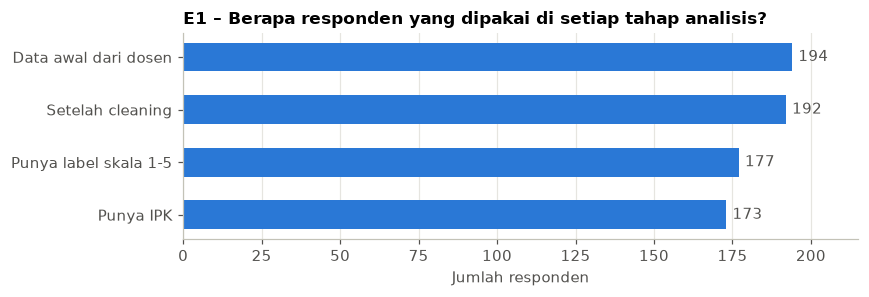

In [40]:
alur = pd.DataFrame({
    "Tahap": ["Data awal dari dosen", "Setelah cleaning", "Punya label skala 1-5", "Punya IPK"],
    "Responden": [len(raw), len(eda), int(ok.sum()), int(eda["IPK"].notna().sum())],
    "Alasan berkurang": ["-",
                         "2 respons kosong total dibuang (ID 11, 133)",
                         "15 straightliner: skor tetap ada, label Felder/Kolb/HM dikosongkan",
                         "19 belum punya IPK (mahasiswa baru / tanpa data nilai)"],
})
display(alur)

fig, ax = plt.subplots(figsize=(8, 2.8))
y = alur["Tahap"][::-1]
x = alur["Responden"][::-1]
ax.barh(y, x, color=BIRU, height=0.55)
for yi, v in enumerate(x):
    ax.text(v + 2, yi, str(v), va="center", color=TEKS)
ax.set_xlim(0, 215)
ax.set_xlabel("Jumlah responden")
ax.grid(axis="y", visible=False)
ax.set_title("E1 – Berapa responden yang dipakai di setiap tahap analisis?")
simpan(fig, "E1_alur_data")

**Interpretasi:** hampir semua data bisa dipakai. Hanya 2 dari 194 respons (1%) yang dibuang karena kosong total. Jumlah responden berbeda per analisis: analisis VARK dan skor memakai 192 orang, analisis label Felder/Kolb/Honey-Mumford memakai 177 orang (tanpa straightliner), dan analisis yang melibatkan IPK memakai 173 orang.
**Yang tidak bisa disimpulkan:** grafik ini tidak menunjukkan kualitas jawaban; itu dibahas di E3.

## E2 – Variabel konteks: angkatan & IPK
**Pertanyaan:** siapa respondennya? Dataset tidak punya prodi/semester, jadi konteks yang tersedia adalah perkiraan angkatan (P1) dan IPK.

,Responden,IPK_terisi,IPK_median,IPK_min,IPK_maks
angkatan_inferred,,,,,
<=2023,18,18,3.60,3.03,3.98
2024,107,107,3.38,1.97,4.00
2025,48,48,3.42,0.87,3.93
2026,11,0,NaN,NaN,NaN
Tidak diketahui,8,0,NaN,NaN,NaN


IPK (n=173): median 3.42, Q1 3.19, Q3 3.67, min 0.87, skewness -1.64


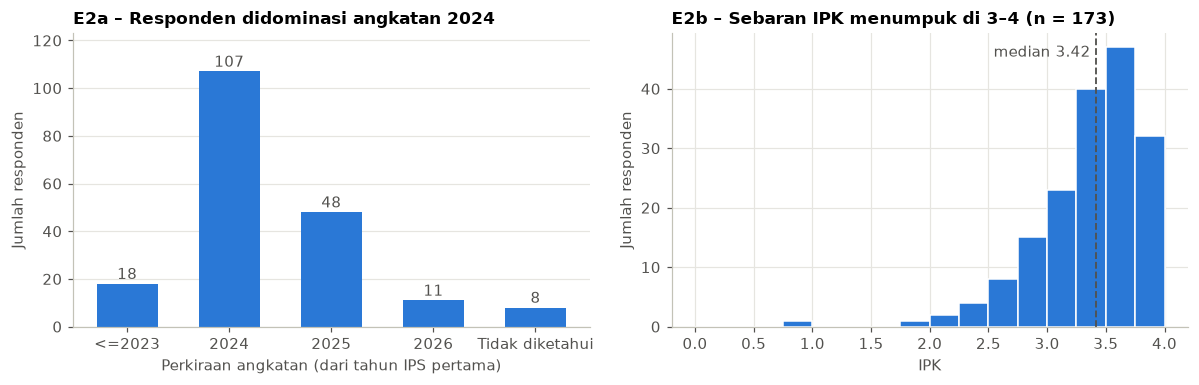

In [41]:
URUTAN_ANGKATAN = ["<=2023", "2024", "2025", "2026", "Tidak diketahui"]
angk = eda["angkatan_inferred"].value_counts().reindex(URUTAN_ANGKATAN)
ipk = eda["IPK"].dropna()

# 1) Ringkasan angka
display(eda.groupby("angkatan_inferred")["IPK"]
        .agg(Responden="size", IPK_terisi="count", IPK_median="median", IPK_min="min", IPK_maks="max")
        .reindex(URUTAN_ANGKATAN).round(2))
print(f"IPK (n={len(ipk)}): median {ipk.median():.2f}, Q1 {ipk.quantile(.25):.2f}, Q3 {ipk.quantile(.75):.2f}, "
      f"min {ipk.min():.2f}, skewness {ipk.skew():.2f}")

# 2) Grafik: kiri = jumlah per angkatan, kanan = sebaran IPK
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.bar(angk.index, angk.values, color=BIRU, width=0.6)
for xi, v in enumerate(angk.values):
    ax1.text(xi, v + 2, str(v), ha="center", color=TEKS)
ax1.set_ylim(0, angk.max() * 1.15)
ax1.set_ylabel("Jumlah responden")
ax1.set_xlabel("Perkiraan angkatan (dari tahun IPS pertama)")
ax1.grid(axis="x", visible=False)
ax1.set_title("E2a – Responden didominasi angkatan 2024")

ax2.hist(ipk, bins=[i / 4 for i in range(0, 17)], color=BIRU, edgecolor="white", linewidth=1)
ax2.axvline(ipk.median(), color=TEKS, linestyle="--", linewidth=1.2)
ax2.text(ipk.median() - 0.05, ax2.get_ylim()[1] * 0.92, f"median {ipk.median():.2f}", ha="right", color=TEKS)
ax2.set_xlabel("IPK")
ax2.set_ylabel("Jumlah responden")
ax2.set_title(f"E2b – Sebaran IPK menumpuk di 3–4 (n = {len(ipk)})")
simpan(fig, "E2_konteks_angkatan_ipk")

**Interpretasi:**
- Responden **didominasi angkatan 2024 (107 dari 192, 56%)**, jadi hasil EDA paling mewakili mahasiswa tahun kedua. Angkatan ≤2023 (18) dan 2026 (11) jumlahnya kecil, sehingga perbandingan antar-angkatan hanya bersifat deskriptif.
- IPK mayoritas tinggi: setengah responden ber-IPK 3,19–3,67 (median 3,42). Sebaran **miring ke kiri** (skewness −1,64) karena ada beberapa IPK sangat rendah (minimum 0,87). Karena itu analisis yang melibatkan IPK sebaiknya memakai median dan korelasi Spearman, bukan rata-rata dan Pearson.
- 19 responden (angkatan 2026 dan yang tidak diketahui angkatannya) belum punya IPK.

**Yang tidak bisa disimpulkan:** angkatan hanya **perkiraan** dari tahun IPS pertama, bukan data resmi. Dataset juga tidak berisi prodi, jadi sampel ini tidak bisa diklaim mewakili seluruh mahasiswa UAJY.

### E2 lanjutan – Apakah IPK berbeda antar-angkatan?
**Metode:** Kruskal-Wallis (membandingkan median beberapa kelompok tanpa asumsi normal), karena IPK miring.

Kruskal-Wallis IPK antar-angkatan: H = 5.25, p = 0.072


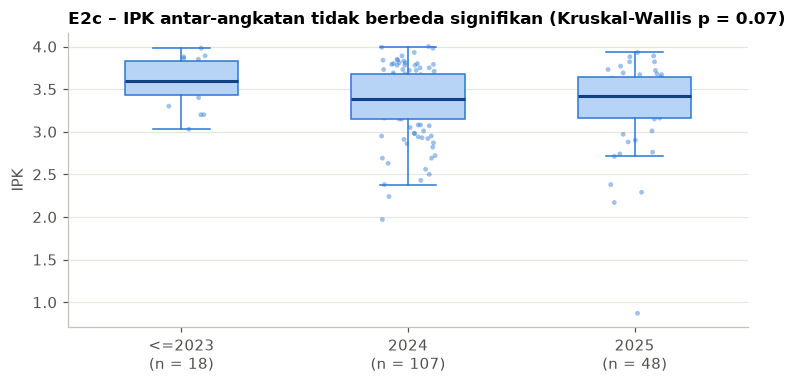

In [42]:
# E2 lanjutan: apakah IPK berbeda antar-angkatan? (hanya angkatan yang punya IPK)
grup_ipk = [a for a in URUTAN_ANGKATAN if eda.loc[eda["angkatan_inferred"] == a, "IPK"].notna().any()]
data_ipk = [eda.loc[eda["angkatan_inferred"] == a, "IPK"].dropna() for a in grup_ipk]
H, p_kw = stats.kruskal(*data_ipk)
print(f"Kruskal-Wallis IPK antar-angkatan: H = {H:.2f}, p = {p_kw:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.boxplot(data_ipk, tick_labels=[f"{a}\n(n = {len(d)})" for a, d in zip(grup_ipk, data_ipk)], widths=0.5,
           patch_artist=True, showfliers=False,
           boxprops=dict(facecolor="#b7d3f6", edgecolor=BIRU), medianprops=dict(color="#104281", linewidth=2),
           whiskerprops=dict(color=BIRU), capprops=dict(color=BIRU))
rng = np.random.default_rng(0)
for i, d in enumerate(data_ipk, start=1):                 # titik individual (digeser acak agar tidak menumpuk)
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(d)), d, s=10, color=BIRU, alpha=0.45, edgecolor="none")
ax.set_ylabel("IPK")
ax.grid(axis="x", visible=False)
ax.set_title(f"E2c – IPK antar-angkatan tidak berbeda signifikan (Kruskal-Wallis p = {p_kw:.2f})")
simpan(fig, "E2c_ipk_per_angkatan")

**Interpretasi:** median IPK angkatan ≤2023 (3,60) sedikit lebih tinggi dari 2024 (3,38) dan 2025 (3,42), tetapi perbedaannya **tidak signifikan** (p = 0,07). Kelompok ≤2023 juga kecil (18 orang).
**Yang tidak bisa disimpulkan:** tidak bisa dikatakan angkatan lama ber-IPK lebih tinggi; titik-titik individual menunjukkan sebaran yang tumpang tindih.

## E3 – Data kosong, pola jawaban, dan nilai ekstrem
**Pertanyaan:** di mana ada data kosong, apakah ada pola jawaban yang bisa mengganggu analisis, dan adakah nilai ekstrem?

,% kosong,Jumlah kosong,Alasan
IPS_2022_S1,99.5,191,Struktural: belum kuliah di semester itu
IPS_2022_S2,99.5,191,Struktural: belum kuliah di semester itu
IPS_2023_S1,90.6,174,Struktural: belum kuliah di semester itu
IPS_2023_S2,90.6,174,Struktural: belum kuliah di semester itu
IPS_2024_S1,34.9,67,Struktural: belum kuliah di semester itu
IPS_2024_S2,34.9,67,Struktural: belum kuliah di semester itu
IPS_2025_S1,9.9,19,Struktural: belum kuliah di semester itu
IPS_2025_S2,10.4,20,Struktural: belum kuliah di semester itu
IPS_2025_S3,91.7,176,Struktural: belum kuliah di semester itu
IPK,9.9,19,Belum punya IPK (mahasiswa baru / tanpa data)


Kolom survei (104 item) yang kosong: 0 sel


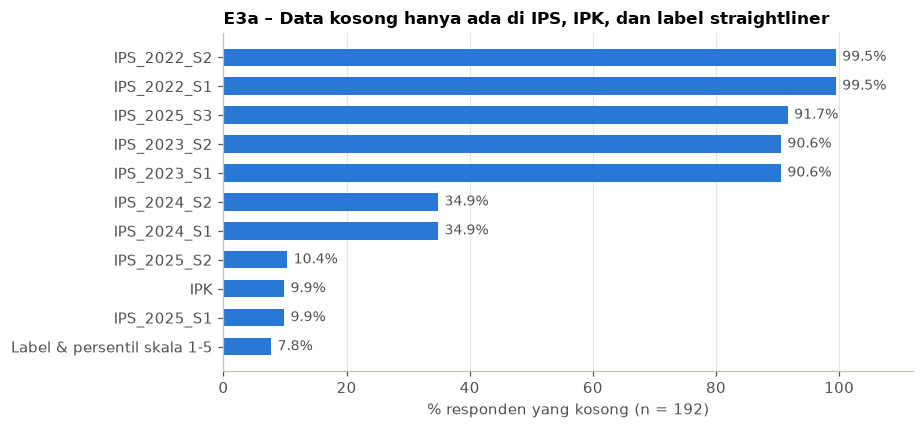

In [43]:
# ---------- a) Data kosong per kolom ----------
persen_kosong = eda.isna().mean().mul(100)
persen_kosong = persen_kosong[persen_kosong > 0]

def alasan_kosong(c):
    if c.startswith("IPS_"): return "Struktural: belum kuliah di semester itu"
    if c == "IPK":           return "Belum punya IPK (mahasiswa baru / tanpa data)"
    return "Straightliner: label skala 1-5 sengaja dikosongkan"

tabel_kosong = (persen_kosong.round(1).rename("% kosong").to_frame()
                .assign(**{"Jumlah kosong": eda[persen_kosong.index].isna().sum(),
                           "Alasan": [alasan_kosong(c) for c in persen_kosong.index]}))
# kolom label/persentil yang kosong karena straightliner digabung jadi satu baris
is_sl = tabel_kosong["Alasan"].str.startswith("Straightliner")
ringkas_kosong = pd.concat([
    tabel_kosong[~is_sl],
    pd.DataFrame({"% kosong": [tabel_kosong.loc[is_sl, "% kosong"].max()],
                  "Jumlah kosong": [tabel_kosong.loc[is_sl, "Jumlah kosong"].max()],
                  "Alasan": [f"Straightliner ({is_sl.sum()} kolom label/persentil)"]},
                 index=["Label & persentil skala 1-5"])])
display(ringkas_kosong)
print("Kolom survei (104 item) yang kosong:", int(eda[VARK_COLS + LIKERT_COLS].isna().sum().sum()), "sel")

fig, ax = plt.subplots(figsize=(8.5, 4))
data_plot = ringkas_kosong["% kosong"].sort_values()
ax.barh(data_plot.index, data_plot.values, color=BIRU, height=0.6)
for yi, v in enumerate(data_plot.values):
    ax.text(v + 1, yi, f"{v:.1f}%", va="center", color=TEKS, fontsize=9)
ax.set_xlim(0, 112)
ax.set_xlabel("% responden yang kosong (n = 192)")
ax.grid(axis="y", visible=False)
ax.set_title("E3a – Data kosong hanya ada di IPS, IPK, dan label straightliner")
simpan(fig, "E3a_data_kosong")

Rata-rata jawaban per responden: median 3.93 | % jawaban 4-5 seluruh data: 68.9%
Responden yang >= 80% jawabannya 4-5: 79 orang


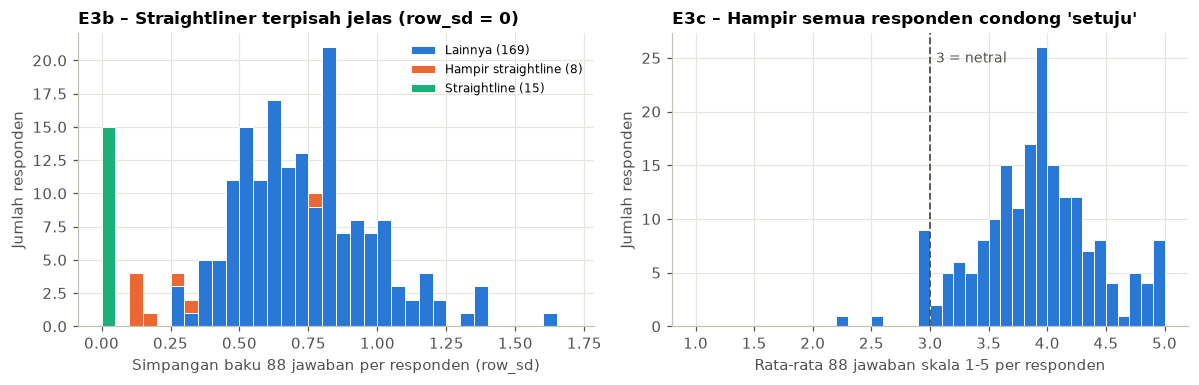

,n,Batas bawah,Batas atas,Di bawah,Di atas,Keputusan
IPK,173,2.47,4.39,8,0,Dipertahankan (nilai valid)
VARK_total,192,4.50,56.50,0,3,Dipertahankan (nilai valid)
FS_ACT_REF_score,177,-4.00,4.00,8,7,Dipertahankan (nilai valid)
FS_SEN_INT_score,177,-6.00,10.00,0,2,Dipertahankan (nilai valid)
FS_VIS_VRB_score,177,-5.50,6.50,5,6,Dipertahankan (nilai valid)
FS_SEQ_GLO_score,177,-4.50,7.50,3,8,Dipertahankan (nilai valid)
KOLB_ACCE,177,-6.50,5.50,8,4,Dipertahankan (nilai valid)
KOLB_AERO,177,-6.50,5.50,4,2,Dipertahankan (nilai valid)
HM_ACT_sum,177,19.00,43.00,1,0,Dipertahankan (nilai valid)
HM_REF_sum,177,21.50,41.50,1,0,Dipertahankan (nilai valid)


In [44]:
# ---------- b) Pola jawaban: variasi jawaban & kecenderungan setuju ----------
rata_jawaban = eda[LIKERT_COLS].astype(float).mean(axis=1)      # rata-rata 88 jawaban per orang
persen_setuju = (eda[LIKERT_COLS] >= 4).mean(axis=1) * 100
n_sl, n_near = int(eda["flag_straightline"].sum()), int(eda["flag_near_straight"].sum())
urut = [f"Lainnya ({len(eda) - n_sl - n_near})", f"Hampir straightline ({n_near})", f"Straightline ({n_sl})"]
kelompok = pd.Series(np.select([eda["flag_straightline"], eda["flag_near_straight"]], [urut[2], urut[1]], urut[0]),
                     index=eda.index)
print(f"Rata-rata jawaban per responden: median {rata_jawaban.median():.2f} | "
      f"% jawaban 4-5 seluruh data: {(eda[LIKERT_COLS] >= 4).to_numpy().mean() * 100:.1f}%")
print(f"Responden yang >= 80% jawabannya 4-5: {int((persen_setuju >= 80).sum())} orang")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.hist([eda.loc[kelompok == k, "row_sd"] for k in urut], bins=np.arange(0, 1.75, 0.05),
         stacked=True, color=[BIRU, ORANYE, HIJAU_TOSKA], label=urut, edgecolor="white", linewidth=0.6)
ax1.set_xlabel("Simpangan baku 88 jawaban per responden (row_sd)")
ax1.set_ylabel("Jumlah responden")
ax1.legend(frameon=False, fontsize=8)
ax1.set_title("E3b – Straightliner terpisah jelas (row_sd = 0)")

ax2.hist(rata_jawaban, bins=np.arange(1, 5.01, 0.1), color=BIRU, edgecolor="white", linewidth=0.6)
ax2.axvline(3, color=TEKS, linestyle="--", linewidth=1.2)
ax2.text(3.05, ax2.get_ylim()[1] * 0.9, "3 = netral", color=TEKS, fontsize=9)
ax2.set_xlabel("Rata-rata 88 jawaban skala 1-5 per responden")
ax2.set_ylabel("Jumlah responden")
ax2.set_title("E3c – Hampir semua responden condong 'setuju'")
simpan(fig, "E3b_pola_jawaban")

# ---------- c) Nilai ekstrem (aturan IQR, hanya ditandai) ----------
def ekstrem_iqr(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"n": len(s), "Batas bawah": round(bawah, 2), "Batas atas": round(atas, 2),
                      "Di bawah": int((s < bawah).sum()), "Di atas": int((s > atas).sum())})
kolom_numerik = (["IPK", "VARK_V", "VARK_A", "VARK_R", "VARK_K", "VARK_total"]
                 + [f"{d}_score" for d in FS_D] + ["KOLB_ACCE", "KOLB_AERO"] + [f"{g}_sum" for g in HM_G])
def subset(c):   # skor dari skala 1-5 dinilai tanpa straightliner (n = 177); VARK & IPK pakai semua
    return eda.loc[ok, c] if c.startswith(("FS_", "KOLB_", "HM_")) else eda[c]
tabel_ekstrem = pd.DataFrame({c: ekstrem_iqr(subset(c)) for c in kolom_numerik}).T.astype({"n": int, "Di bawah": int, "Di atas": int})
tabel_ekstrem = tabel_ekstrem[(tabel_ekstrem["Di bawah"] + tabel_ekstrem["Di atas"]) > 0]
tabel_ekstrem["Keputusan"] = "Dipertahankan (nilai valid)"
display(tabel_ekstrem)

**Interpretasi:**
- **Data kosong:** 104 item survei tidak punya sel kosong. Kekosongan hanya ada di IPS (struktural, mengikuti angkatan), IPK (19 orang belum punya), dan label skala 1–5 milik 15 straightliner (sengaja dikosongkan). Jadi kekosongan **tidak acak** dan **tidak diimputasi**.
- **Pola jawaban:** 15 straightliner (row_sd = 0) dan 8 hampir straightline terpisah jelas dari responden lain. Lebih penting lagi, **187 dari 192 responden rata-rata jawabannya ≥ 3**, dan 68,9% seluruh jawaban adalah 4/5. Ada kecenderungan menjawab "setuju" (*acquiescence*) yang membuat skor semua tipe sama-sama tinggi. Ini alasan rumus selisih (Felder, Kolb) dan norma relatif (Honey-Mumford) dipakai di scoring.
- **Nilai ekstrem (aturan IQR):** misalnya 8 IPK di bawah 2,47. Semuanya nilai yang mungkin, jadi **dipertahankan** dan hanya ditandai.

**Yang tidak bisa disimpulkan:** aturan IQR hanya menandai nilai yang jauh dari mayoritas, bukan bukti nilai itu salah.

### E3 lanjutan – Bukti visual missing struktural pada IPS

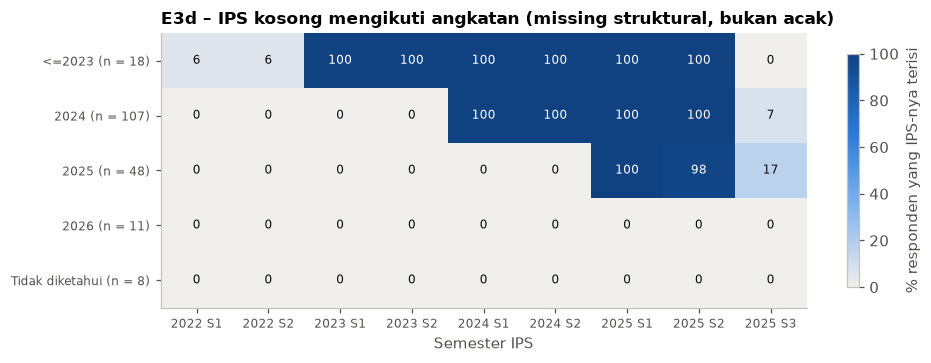

In [45]:
# E3 lanjutan: bukti visual bahwa IPS kosong mengikuti angkatan (missing struktural)
IPS_PLOT = [c for c in IPS_COLS if c in eda.columns]
terisi = (eda.groupby("angkatan_inferred")[IPS_PLOT].apply(lambda g: g.notna().mean() * 100)
          .reindex(URUTAN_ANGKATAN))
biru_seq = LinearSegmentedColormap.from_list("biru_seq", ["#f0efec", "#86b6ef", "#2a78d6", "#104281"])
fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(terisi, cmap=biru_seq, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(IPS_PLOT)), [c.replace("IPS_", "").replace("_", " ") for c in IPS_PLOT], fontsize=8)
ax.set_yticks(range(len(terisi)), [f"{a} (n = {(eda['angkatan_inferred'] == a).sum()})" for a in terisi.index], fontsize=8)
for i in range(terisi.shape[0]):
    for j in range(terisi.shape[1]):
        v = terisi.iloc[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 60 else "#0b0b0b")
ax.grid(False)
ax.set_xlabel("Semester IPS")
fig.colorbar(im, ax=ax, shrink=0.85, label="% responden yang IPS-nya terisi")
ax.set_title("E3d – IPS kosong mengikuti angkatan (missing struktural, bukan acak)")
simpan(fig, "E3d_pola_ips_per_angkatan")

**Interpretasi:** setiap angkatan punya IPS **100% terisi mulai semester pertamanya** dan 0% sebelumnya, seperti tangga. Ini membuktikan IPS kosong karena belum kuliah, bukan karena tidak diisi. IPS 2025 S3 hanya terisi 7–17% (kemungkinan semester pendek yang opsional), dan 6% di 2022 adalah 1 orang angkatan 2022.
**Yang tidak bisa disimpulkan:** angkatan sendiri diturunkan dari pola IPS ini, jadi grafik ini menunjukkan konsistensi datanya, bukan validasi independen terhadap angkatan resmi.

## E4 – Distribusi skor tiap framework
**Pertanyaan:** bagaimana sebaran skor di tiap framework, dan apakah item dalam satu tipe konsisten (Cronbach's alpha)?

n  Median    Q1    Q3  Min  Maks
Framework        Skor                                                
VARK             VARK_V            192     7.0   4.0  11.0    0    16
                 VARK_A            192     8.0   6.0  11.0    0    16
                 VARK_R            192     7.0   4.0  10.0    0    16
                 VARK_K            192     8.0   5.0  12.0    0    16
Felder-Silverman FS_ACT_REF_score  177     0.0  -1.0   1.0   -8    15
                 FS_SEN_INT_score  177     1.0   0.0   4.0   -5    12
                 FS_VIS_VRB_score  177     0.0  -1.0   2.0   -9    13
                 FS_SEQ_GLO_score  177     0.0   0.0   3.0   -6    11
Kolb             KOLB_CE_sum       177    24.0  22.0  27.0   10    30
                 KOLB_RO_sum       177    24.0  21.0  26.0   14    30
                 KOLB_AC_sum       177    24.0  21.0  26.0   11    30
                 KOLB_AE_sum       177    23.0  20.0  26.0   11    30
Honey-Mumford    HM_ACT_sum        177    31.0  28.0  34.0   18    40
                 HM_REF_sum        177    32.0  29.0  34.0   14    40
                 HM_THE_sum        177    32.0  29.0  35.0   14    40
                 HM_PRA_sum        177    32.0  29.0  36.0   19    40

Cronbach's alpha 16 subskala (n = 177): min 0.70 (FS_GLO), maks 0.86 (KOLB_CE); >= 0.70: 15 dari 16


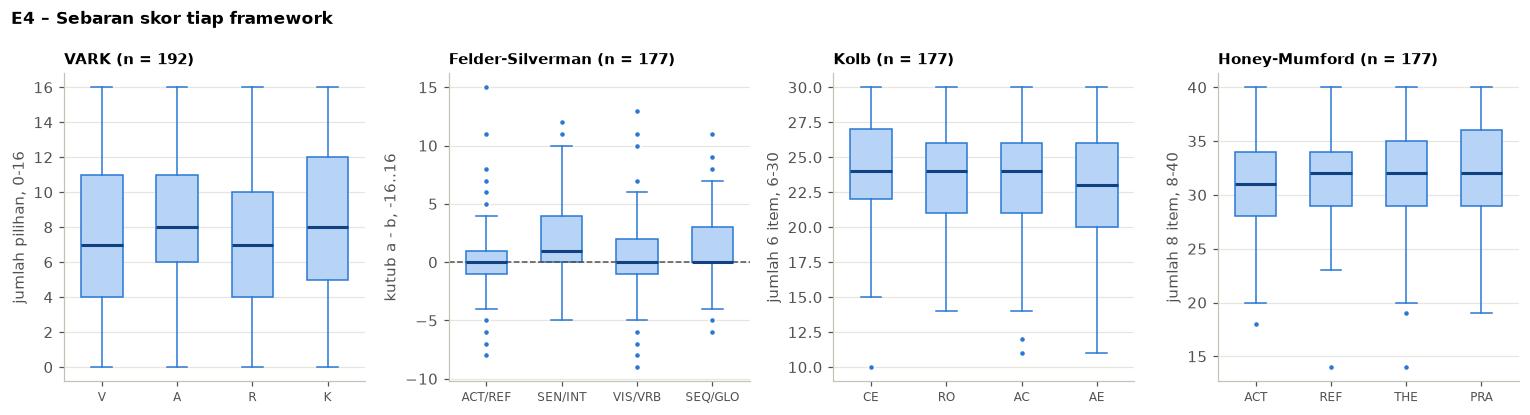

In [46]:
def cronbach_alpha(item):
    """Konsistensi internal sekelompok item (>= 0.70 dianggap memadai)."""
    item = item.astype(float).dropna()
    k = item.shape[1]
    return k / (k - 1) * (1 - item.var(ddof=1).sum() / item.sum(axis=1).var(ddof=1))

# 1) Ringkasan skor (VARK: n = 192; skor dari skala 1-5: n = 177 tanpa straightliner)
SKOR = {
    "VARK (jumlah pilihan, 0-16)":           ["VARK_V", "VARK_A", "VARK_R", "VARK_K"],
    "Felder-Silverman (kutub a - b, -16..16)": [f"{d}_score" for d in FS_D],
    "Kolb (jumlah 6 item, 6-30)":            [f"KOLB_{m}_sum" for m in KM],
    "Honey-Mumford (jumlah 8 item, 8-40)":   [f"{g}_sum" for g in HM_G],
}
baris = []
for fw, kol in SKOR.items():
    data = eda[kol] if fw.startswith("VARK") else eda.loc[ok, kol]
    for c in kol:
        s = data[c]
        baris.append({"Framework": fw.split(" (")[0], "Skor": c, "n": s.notna().sum(),
                      "Median": s.median(), "Q1": s.quantile(.25), "Q3": s.quantile(.75),
                      "Min": s.min(), "Maks": s.max()})
display(pd.DataFrame(baris).set_index(["Framework", "Skor"]).round(2))

# 2) Reliabilitas: apakah item dalam satu subskala konsisten? (n = 177)
subskala = {f"{g}": [c for c in LIKERT_COLS if c.startswith(f"{g}_")]
            for g in ["HM_ACT", "HM_REF", "HM_THE", "HM_PRA", "FS_ACT", "FS_REF", "FS_SEN", "FS_INT",
                      "FS_VIS", "FS_VRB", "FS_SEQ", "FS_GLO", "KOLB_CE", "KOLB_RO", "KOLB_AC", "KOLB_AE"]}
alpha = pd.Series({s: cronbach_alpha(eda.loc[ok, item]) for s, item in subskala.items()}).round(3)
print(f"Cronbach's alpha 16 subskala (n = {int(ok.sum())}): min {alpha.min():.2f} ({alpha.idxmin()}), "
      f"maks {alpha.max():.2f} ({alpha.idxmax()}); >= 0.70: {int((alpha >= 0.70).sum())} dari 16")

# 3) Grafik: boxplot per framework
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, (fw, kol) in zip(axes, SKOR.items()):
    data = eda[kol] if fw.startswith("VARK") else eda.loc[ok, kol]
    label = [c.replace("VARK_", "").replace("_score", "").replace("FS_", "").replace("KOLB_", "")
              .replace("_sum", "").replace("HM_", "").replace("_", "/") for c in kol]
    ax.boxplot([data[c].dropna() for c in kol], tick_labels=label, widths=0.55, patch_artist=True,
               boxprops=dict(facecolor="#b7d3f6", edgecolor=BIRU), medianprops=dict(color="#104281", linewidth=2),
               whiskerprops=dict(color=BIRU), capprops=dict(color=BIRU),
               flierprops=dict(marker="o", markersize=4, markerfacecolor=BIRU, markeredgecolor="white"))
    if "Felder" in fw:
        ax.axhline(0, color=TEKS, linestyle="--", linewidth=1)
    ax.grid(axis="x", visible=False)
    ax.set_title(f"{fw.split(' (')[0]} (n = {len(data)})", fontsize=10)
    ax.set_ylabel(fw[fw.index("(") + 1:-1])
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("E4 – Sebaran skor tiap framework", x=0.01, ha="left", fontweight="bold", fontsize=11)
simpan(fig, "E4_distribusi_skor")

**Interpretasi:**
- **VARK:** median keempat modalitas mirip (7–8 dari 16), sebarannya lebar. Tidak ada modalitas yang mendominasi seluruh kelas.
- **Felder:** skor menumpuk di sekitar 0 (seimbang). Hanya SEN-INT yang condong positif (median +1), artinya responden sedikit lebih suka fakta/contoh konkret.
- **Kolb & Honey-Mumford:** median keempat tahap/gaya hampir sama (Kolb 23–24, HM 31–32). Skor mentah saja sulit membedakan tipe; ini sejalan dengan temuan *acquiescence* di E3.
- **Reliabilitas:** Cronbach's alpha 16 subskala berkisar 0,70–0,86 (terendah FS_GLO 0,699). Item dalam satu tipe cukup konsisten, sehingga pengelompokan item untuk scoring bisa dipertanggungjawabkan.

**Yang tidak bisa disimpulkan:** skor antar-framework tidak bisa dibandingkan langsung karena satuannya berbeda (VARK 0–16, Felder −16..16, Kolb 6–30, HM 8–40).

### E4 lanjutan – Peta dua sumbu Kolb
Teori Kolb menempatkan setiap orang pada dua sumbu (AC−CE dan AE−RO); tipe ditentukan oleh kuadrannya.

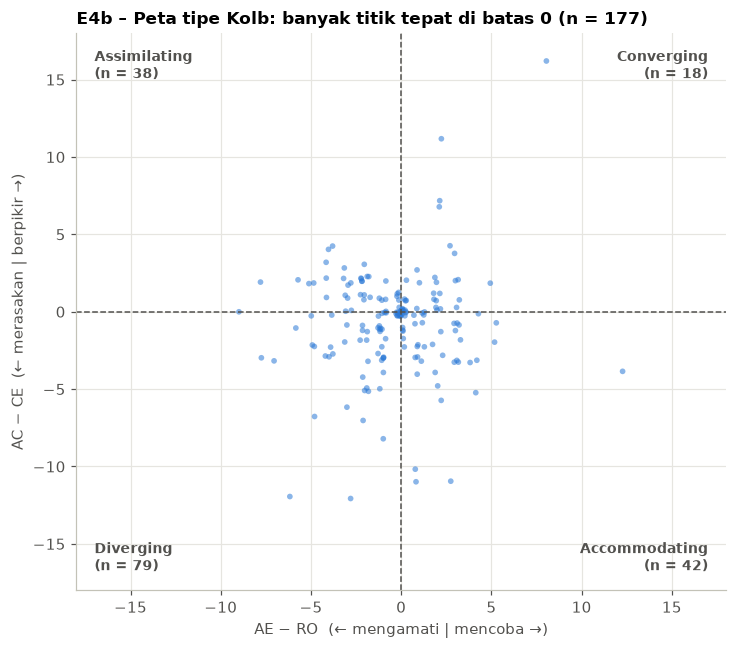

Tepat di garis batas: AC-CE = 0 -> 42 orang, AE-RO = 0 -> 35 orang


In [47]:
# E4 lanjutan: peta dua sumbu Kolb (inti teori Kolb), n = 177
x_k = eda.loc[ok, "KOLB_AERO"]; y_k = eda.loc[ok, "KOLB_ACCE"]
rng = np.random.default_rng(1)
fig, ax = plt.subplots(figsize=(6.8, 6))
ax.scatter(x_k + rng.uniform(-0.3, 0.3, len(x_k)), y_k + rng.uniform(-0.3, 0.3, len(y_k)),
           s=14, color=BIRU, alpha=0.55, edgecolor="none")
ax.axvline(CUT_AERO, color=TEKS, linestyle="--", linewidth=1)
ax.axhline(CUT_ACCE, color=TEKS, linestyle="--", linewidth=1)
batas = max(x_k.abs().max(), y_k.abs().max()) + 2
ax.set_xlim(-batas, batas); ax.set_ylim(-batas, batas)
jumlah = eda.loc[ok, "KOLB_style"].value_counts()
for teks, (xx, yy, ha, va) in {"Accommodating": (batas - 1, -batas + 1, "right", "bottom"),
                               "Diverging":     (-batas + 1, -batas + 1, "left", "bottom"),
                               "Assimilating":  (-batas + 1, batas - 1, "left", "top"),
                               "Converging":    (batas - 1, batas - 1, "right", "top")}.items():
    ax.text(xx, yy, f"{teks}\n(n = {jumlah[teks]})", ha=ha, va=va, fontsize=9, color=TEKS, fontweight="bold")
ax.set_xlabel("AE − RO  (← mengamati | mencoba →)")
ax.set_ylabel("AC − CE  (← merasakan | berpikir →)")
ax.set_title(f"E4b – Peta tipe Kolb: banyak titik tepat di batas 0 (n = {int(ok.sum())})")
simpan(fig, "E4b_peta_kolb")
print(f"Tepat di garis batas: AC-CE = 0 -> {int((y_k == CUT_ACCE).sum())} orang, AE-RO = 0 -> {int((x_k == CUT_AERO).sum())} orang")

**Interpretasi:** sebagian besar responden mengumpul di dekat titik tengah (0, 0), artinya preferensi Kolb mereka **tidak kuat ke arah mana pun**. Sebanyak 42 orang tepat di AC−CE = 0 dan 35 orang tepat di AE−RO = 0. Sesuai aturan manual, mereka masuk sisi merasakan/mengamati, sehingga Diverging menjadi kuadran terbesar (79).
**Yang tidak bisa disimpulkan:** titik di dekat garis batas bisa pindah kuadran hanya karena beda satu jawaban; label Kolb untuk mereka kurang stabil.

## E5 – Distribusi label & ketidakseimbangan kelas
**Pertanyaan:** bagaimana sebaran label tiap framework, dan apakah ada kelas yang terlalu kecil untuk tahap modelling?

,n,Distribusi,Kelas terkecil (%),Rasio terbesar:terkecil
Label,,,,
VARK_type,192,"Single=57, Bimodal=31, Trimodal=30, Quadmodal=74",15.6,2.5
KOLB_style,177,"Diverging=79, Assimilating=38, Converging=18, Accommodating=42",10.2,4.4
HM_dominant,177,"Activist=48, Reflector=51, Theorist=37, Pragmatist=37, Seri=4",21.4,1.4
FS_ACT_REF_pole,177,"ACT=67, NEUTRAL=46, REF=64",26.0,1.5
FS_SEN_INT_pole,177,"SEN=108, NEUTRAL=36, INT=33",18.6,3.3
FS_VIS_VRB_pole,177,"VIS=81, NEUTRAL=51, VRB=45",25.4,1.8
FS_SEQ_GLO_pole,177,"SEQ=86, NEUTRAL=50, GLO=41",23.2,2.1


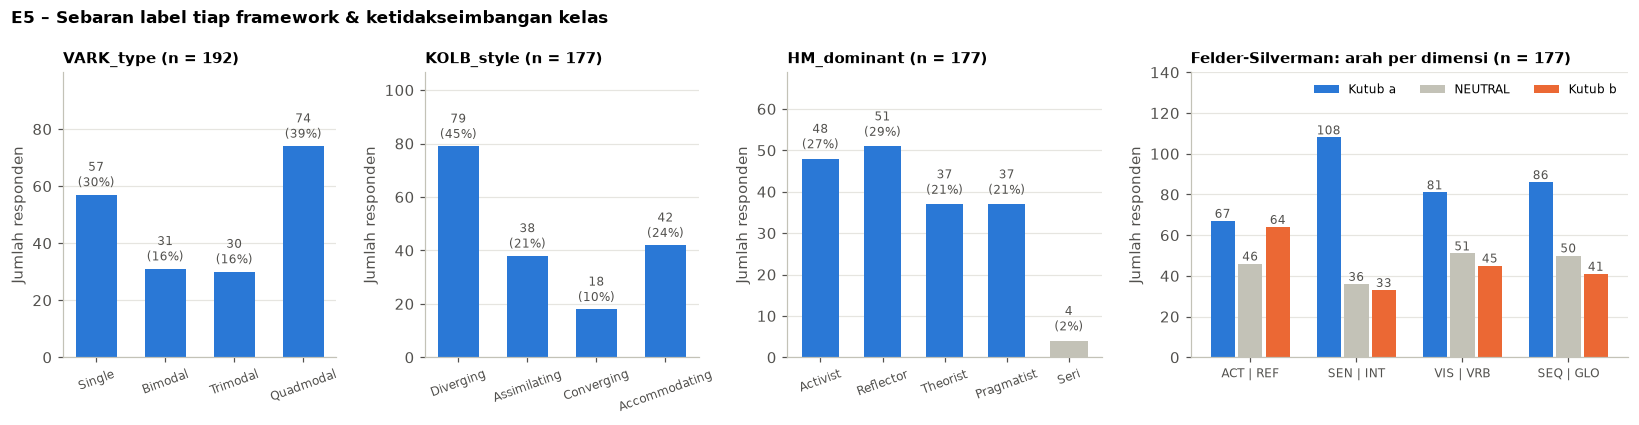

In [48]:
# 1) Distribusi label + indikator ketidakseimbangan kelas
LABEL = {
    "VARK_type":  (eda["VARK_type"], ["Single", "Bimodal", "Trimodal", "Quadmodal"]),
    "KOLB_style": (eda.loc[ok, "KOLB_style"], ["Diverging", "Assimilating", "Converging", "Accommodating"]),
    "HM_dominant": (eda.loc[ok, "HM_dominant"].where(~eda.loc[ok, "HM_dominant"].str.contains(r"\+"), "Seri"),
                    ["Activist", "Reflector", "Theorist", "Pragmatist", "Seri"]),
}
for d, (a, b) in FS_DIMS.items():
    LABEL[f"{d}_pole"] = (eda.loc[ok, f"{d}_pole"], [a, "NEUTRAL", b])

ringkas_label = []
for nama, (s, urutan) in LABEL.items():
    n = s.value_counts().reindex(urutan).fillna(0).astype(int)
    utama = n.drop("Seri", errors="ignore")                    # kelas "Seri" tidak dihitung sebagai kelas
    ringkas_label.append({"Label": nama, "n": int(s.notna().sum()),
                          "Distribusi": ", ".join(f"{k}={v}" for k, v in n.items()),
                          "Kelas terkecil (%)": round(utama.min() / utama.sum() * 100, 1),
                          "Rasio terbesar:terkecil": round(utama.max() / utama.min(), 1)})
ringkas_label = pd.DataFrame(ringkas_label).set_index("Label")
display(ringkas_label)

# 2) Grafik: 4 panel
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), gridspec_kw={"width_ratios": [1, 1, 1.15, 1.6]})
for ax, nama in zip(axes[:3], ["VARK_type", "KOLB_style", "HM_dominant"]):
    s, urutan = LABEL[nama]
    n = s.value_counts().reindex(urutan).fillna(0).astype(int)
    warna = [ABU if k == "Seri" else BIRU for k in n.index]
    ax.bar(n.index, n.values, color=warna, width=0.6)
    for xi, v in enumerate(n.values):
        ax.text(xi, v + 1.5, f"{v}\n({v / n.sum() * 100:.0f}%)", ha="center", va="bottom", fontsize=8, color=TEKS)
    ax.set_ylim(0, n.max() * 1.35)
    ax.set_title(f"{nama} (n = {n.sum()})", fontsize=10)
    ax.set_ylabel("Jumlah responden")
    ax.tick_params(axis="x", labelsize=8, rotation=20)
    ax.grid(axis="x", visible=False)

ax = axes[3]                                    # Felder: 4 dimensi x 3 arah
x = np.arange(len(FS_DIMS)); lebar = 0.26
for j, (arah, warna) in enumerate(zip(["Kutub a", "NEUTRAL", "Kutub b"], [BIRU, ABU, ORANYE])):
    nilai = []
    for d, (a, b) in FS_DIMS.items():
        target = {"Kutub a": a, "NEUTRAL": "NEUTRAL", "Kutub b": b}[arah]
        nilai.append(int((eda.loc[ok, f"{d}_pole"] == target).sum()))
    ax.bar(x + (j - 1) * lebar, nilai, width=lebar - 0.03, color=warna, label=arah)
    for xi, v in zip(x + (j - 1) * lebar, nilai):
        ax.text(xi, v + 1.5, str(v), ha="center", fontsize=8, color=TEKS)
ax.set_xticks(x, [f"{a} | {b}" for a, b in FS_DIMS.values()], fontsize=8)
ax.set_ylim(0, 140)
ax.set_ylabel("Jumlah responden")
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper right")
ax.grid(axis="x", visible=False)
ax.set_title(f"Felder-Silverman: arah per dimensi (n = {int(ok.sum())})", fontsize=10)
fig.suptitle("E5 – Sebaran label tiap framework & ketidakseimbangan kelas", x=0.01, ha="left", fontweight="bold", fontsize=11)
simpan(fig, "E5_distribusi_label")

**Interpretasi:**
- **HM_dominant paling seimbang** (kelas terkecil 21%, rasio terbesar:terkecil 1,4). Ini kandidat target modelling terbaik. Ada 4 responden seri yang perlu diputuskan penanganannya saat modelling.
- **KOLB_style paling timpang:** Converging hanya 18 orang (10%), rasio 4,4. Saat modelling perlu penanganan *class imbalance* (misalnya *class weight* atau *stratified split*).
- **VARK_type:** Quadmodal terbanyak (39%), sesuai teori Fleming bahwa multimodal itu umum.
- **Felder:** arah cukup bervariasi, kecuali SEN-INT yang condong ke Sensing (108 vs 33). Label kekuatan hampir semuanya *Balanced* (88–95%), jadi tidak dipakai sebagai target.

**Yang tidak bisa disimpulkan:** label bersifat relatif terhadap sampel ini (batas Kolb dan pita HM memakai norma lokal), jadi proporsinya tidak bisa dibandingkan dengan populasi lain.

### E5 lanjutan – Detail profil VARK

Jumlah kombinasi profil VARK: 15; profil dengan < 5 responden: 4


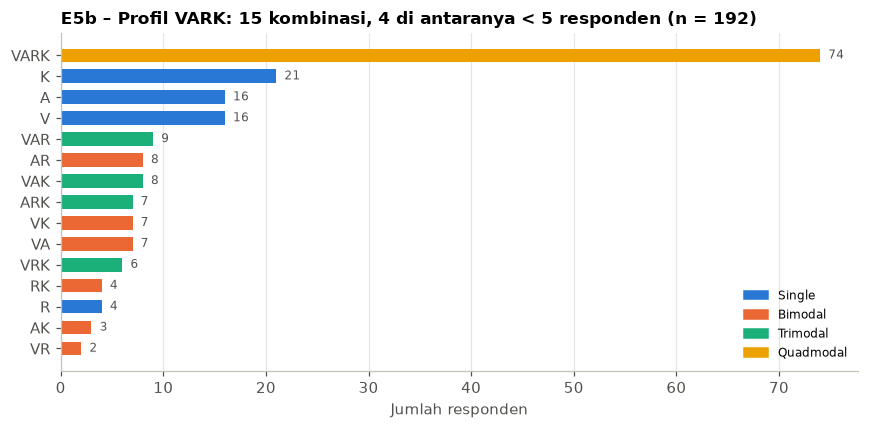

In [49]:
# E5 lanjutan: detail profil VARK (kombinasi modalitas), n = 192
profil = eda["VARK_profile"].value_counts()
print(f"Jumlah kombinasi profil VARK: {len(profil)}; profil dengan < 5 responden: {int((profil < 5).sum())}")
fig, ax = plt.subplots(figsize=(8, 4))
warna_tipe = {1: BIRU, 2: ORANYE, 3: HIJAU_TOSKA, 4: KUNING}
p = profil.sort_values()
ax.barh(p.index, p.values, color=[warna_tipe[len(k)] for k in p.index], height=0.65)
for yi, v in enumerate(p.values):
    ax.text(v + 0.8, yi, str(v), va="center", fontsize=8, color=TEKS)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(warna_tipe.values(), ["Single", "Bimodal", "Trimodal", "Quadmodal"])],
          frameon=False, fontsize=8, loc="lower right")
ax.set_xlabel("Jumlah responden")
ax.grid(axis="y", visible=False)
ax.set_title(f"E5b – Profil VARK: {len(profil)} kombinasi, {int((profil < 5).sum())} di antaranya < 5 responden (n = {len(eda)})")
simpan(fig, "E5b_profil_vark")

**Interpretasi:** dari 15 kombinasi profil, `VARK` (quadmodal) mendominasi (74), diikuti single K (21), A (16), V (16). Single R hanya 4 orang. Ada 4 profil dengan < 5 responden, jadi `VARK_profile` **tidak cocok** sebagai target modelling; `VARK_type` (4 kelas) lebih layak.
**Yang tidak bisa disimpulkan:** banyaknya quadmodal bisa juga karena responden yang memilih banyak opsi mendapat stepping distance yang longgar (aturan Fleming).

### E5 lanjutan – Label untuk UAS (Berdasarkan Analisis Kami pada label yang diperlukan untuk UAS)
**Pertanyaan:** kalau label dihitung dengan aturan UAS (S5), seberapa seimbang kelasnya untuk klasifikasi nanti?


,n,% Seri/Setara/Batas,Kelas terkecil,Rasio terbesar:terkecil,Kira-kira di test 20%,15 straightliner masuk ke
Label,,,,,,
VARK_label_uas,192,15.6,Seri = 30 (16%),1.7,6-10 per kelas,"Aural, Seri, Read/Write, Kinesthetic"
FS_AR_label_uas,192,31.8,Setara = 61 (32%),1.1,12-13 per kelas,Setara
HM_label_uas,192,33.3,Activist = 18 (9%),3.6,4-13 per kelas,Seri
KOLB_label_uas,192,36.5,AC_AE = 18 (9%),3.9,4-14 per kelas,Batas


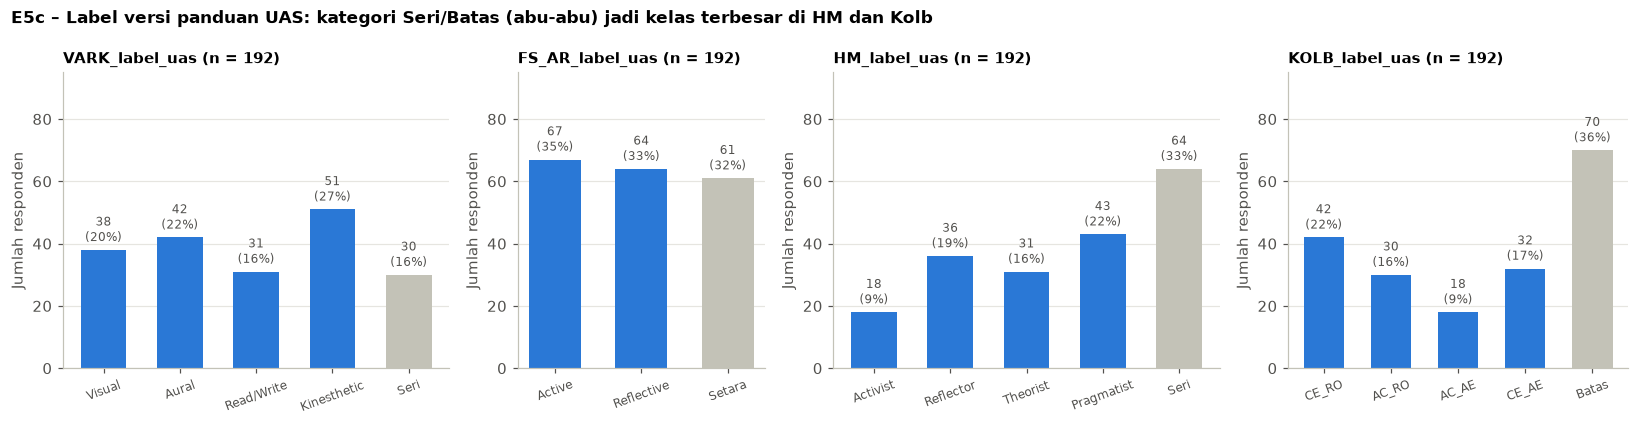

In [50]:
# E5c: distribusi label versi panduan UAS (calon target klasifikasi UAS), n = 192
URUT_UAS = {
    "VARK_label_uas":  ["Visual", "Aural", "Read/Write", "Kinesthetic", "Seri"],
    "FS_AR_label_uas": ["Active", "Reflective", "Setara"],
    "HM_label_uas":    ["Activist", "Reflector", "Theorist", "Pragmatist", "Seri"],
    "KOLB_label_uas":  ["CE_RO", "AC_RO", "AC_AE", "CE_AE", "Batas"],
}
OPERASIONAL = ["Seri", "Setara", "Batas"]            # kategori aturan tugas, bukan gaya belajar

ringkas_uas = []
for kol, urut in URUT_UAS.items():
    n = eda[kol].value_counts().reindex(urut).fillna(0).astype(int)
    ringkas_uas.append({"Label": kol, "n": int(n.sum()),
                        "% Seri/Setara/Batas": round(n[n.index.isin(OPERASIONAL)].sum() / n.sum() * 100, 1),
                        "Kelas terkecil": f"{n.idxmin()} = {n.min()} ({n.min() / n.sum() * 100:.0f}%)",
                        "Rasio terbesar:terkecil": round(n.max() / n.min(), 1),
                        "Kira-kira di test 20%": f"{n.min() * 0.2:.0f}-{n.max() * 0.2:.0f} per kelas",
                        "15 straightliner masuk ke": ", ".join(eda.loc[~ok, kol].value_counts().index)})
display(pd.DataFrame(ringkas_uas).set_index("Label"))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), gridspec_kw={"width_ratios": [1.25, 0.8, 1.25, 1.1]})
for ax, (kol, urut) in zip(axes, URUT_UAS.items()):
    n = eda[kol].value_counts().reindex(urut).fillna(0).astype(int)
    ax.bar(n.index, n.values, color=[ABU if k in OPERASIONAL else BIRU for k in n.index], width=0.6)
    for xi, v in enumerate(n.values):
        ax.text(xi, v + 1.5, f"{v}\n({v / n.sum() * 100:.0f}%)", ha="center", va="bottom", fontsize=8, color=TEKS)
    ax.set_ylim(0, 95)
    ax.set_title(f"{kol} (n = {n.sum()})", fontsize=10)
    ax.set_ylabel("Jumlah responden")
    ax.tick_params(axis="x", labelsize=8, rotation=20)
    ax.grid(axis="x", visible=False)
fig.suptitle("E5c – Label versi panduan UAS: kategori Seri/Batas (abu-abu) jadi kelas terbesar di HM dan Kolb",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
simpan(fig, "E5c_label_uas")


**Interpretasi:**
- **FS_AR_label_uas paling seimbang** (67 / 64 / 61, rasio 1,1), tetapi sepertiganya (32%) adalah kategori Setara.
- **VARK_label_uas cukup seimbang** (rasio 1,7); kelas terkecil Seri (30 orang, 16%).
- **HM dan Kolb didominasi kategori operasional:** Seri 33% (HM) dan Batas 36% (Kolb) menjadi kelas terbesar, sementara Activist dan AC_AE hanya 18 orang (9%). Di test set 20% kelas ini tinggal sekitar 4 contoh.
- **Ke-15 straightliner semuanya jatuh ke Setara/Seri/Batas** pada FS, HM, dan Kolb. Keputusan memakai atau mengecualikan mereka akan mengubah ukuran kelas tersebut.

**Dampak untuk UAS:** VARK dan FS lebih siap dipakai untuk klasifikasi dengan *stratified split*; untuk HM dan Kolb, macro-F1 dan analisis kesalahan perlu memperhatikan dominasi Seri/Batas. Gambaran ini berbeda dari E5 karena aturan labelnya berbeda (teori vs aturan operasional tugas).

**Yang tidak bisa disimpulkan:** Seri/Setara/Batas adalah aturan operasional tugas, bukan gaya belajar kelima. Distribusi ini juga tidak menunjukkan framework mana yang lebih benar; hanya mana yang kelasnya lebih seimbang untuk dimodelkan.


## E6 – Hubungan antar-skor (korelasi sesuai tipe data)
**Pertanyaan:** skor mana yang saling berhubungan, dan apakah gaya belajar berhubungan dengan IPK?
**Metode:** Spearman ρ, karena skor bersifat ordinal/hitungan dan IPK miring (tidak memakai Pearson). Uji ke IPK dikoreksi untuk uji berganda (FDR). Label kategorikal **tidak** dikorelasikan di sini (lihat E7).

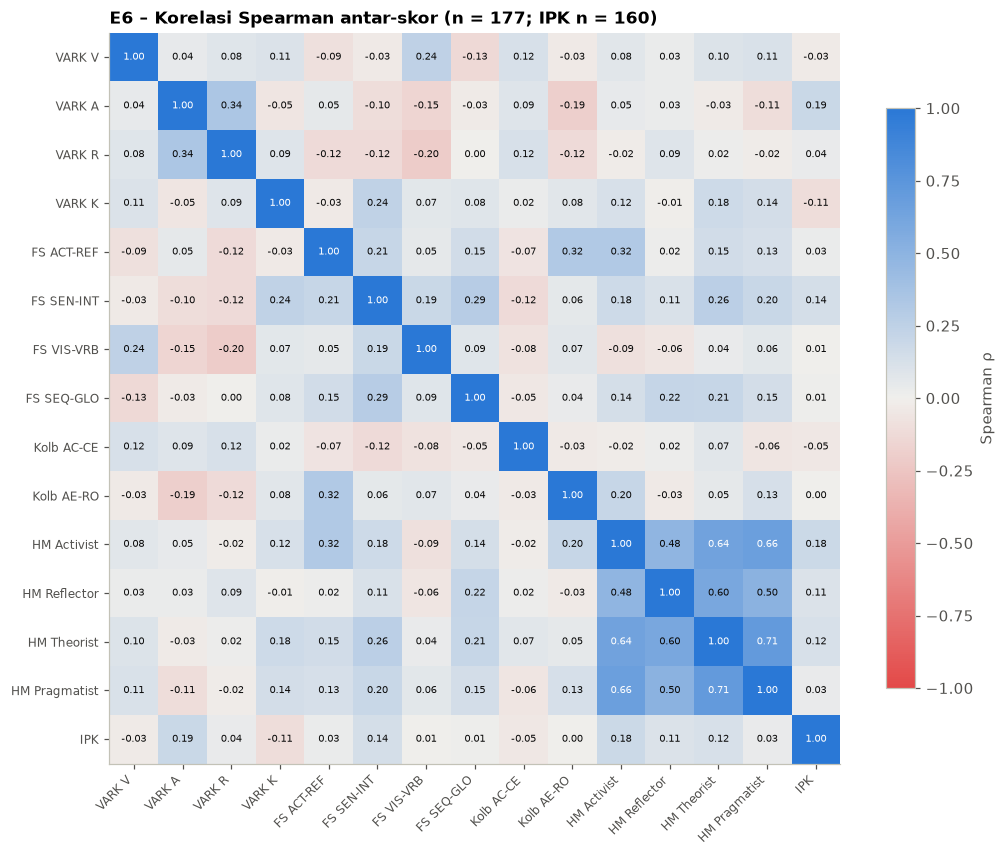

,Pasangan,rho,p
0,HM Activist ~ Kolb AE-RO,0.20,0.0063
1,HM Reflector ~ Kolb AE-RO,-0.03,0.6463
2,HM Theorist ~ Kolb AC-CE,0.07,0.3445
3,HM Activist ~ FS ACT-REF,0.32,0.0000
4,VARK V ~ FS VIS-VRB,0.24,0.0011
5,VARK K ~ HM Activist,0.12,0.1052


Korelasi dengan IPK (n = 160): |rho| maks 0.19; p < 0.05: 2 dari 14; signifikan setelah FDR: 0


,Skor,rho,p,q (FDR)
1,VARK A,0.189,0.017,0.155
10,HM Activist,0.181,0.022,0.155
5,FS SEN-INT,0.136,0.087,0.405
12,HM Theorist,0.124,0.118,0.413
11,HM Reflector,0.109,0.170,0.413


In [51]:
# Variabel numerik/ordinal -> Spearman (tidak mengasumsikan sebaran normal; IPK juga miring)
VAR_NUM = {"VARK_V": "VARK V", "VARK_A": "VARK A", "VARK_R": "VARK R", "VARK_K": "VARK K",
           "FS_ACT_REF_score": "FS ACT-REF", "FS_SEN_INT_score": "FS SEN-INT",
           "FS_VIS_VRB_score": "FS VIS-VRB", "FS_SEQ_GLO_score": "FS SEQ-GLO",
           "KOLB_ACCE": "Kolb AC-CE", "KOLB_AERO": "Kolb AE-RO",
           "HM_ACT_sum": "HM Activist", "HM_REF_sum": "HM Reflector",
           "HM_THE_sum": "HM Theorist", "HM_PRA_sum": "HM Pragmatist", "IPK": "IPK"}
data_kor = eda.loc[ok, list(VAR_NUM)].astype(float).rename(columns=VAR_NUM)     # n = 177 (IPK: 160)
rho = data_kor.corr(method="spearman")

# 1) Heatmap korelasi Spearman
cmap = LinearSegmentedColormap.from_list("biru_merah", ["#e34948", "#f0efec", "#2a78d6"])
fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(rho, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(rho)), rho.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(rho)), rho.index, fontsize=8)
for i in range(len(rho)):
    for j in range(len(rho)):
        ax.text(j, i, f"{rho.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(rho.iloc[i, j]) > 0.6 else "#0b0b0b")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.75, label="Spearman ρ")
ax.set_title(f"E6 – Korelasi Spearman antar-skor (n = {int(ok.sum())}; IPK n = {int(data_kor['IPK'].notna().sum())})")
simpan(fig, "E6_korelasi_spearman")

# 2) Pasangan yang secara teori berhubungan (lintas framework)
pasangan = [("HM Activist", "Kolb AE-RO"), ("HM Reflector", "Kolb AE-RO"), ("HM Theorist", "Kolb AC-CE"),
            ("HM Activist", "FS ACT-REF"), ("VARK V", "FS VIS-VRB"), ("VARK K", "HM Activist")]
tabel_pasangan = pd.DataFrame([{"Pasangan": f"{a} ~ {b}", "rho": round(rho.loc[a, b], 2),
                                "p": stats.spearmanr(data_kor[a], data_kor[b]).pvalue} for a, b in pasangan])
display(tabel_pasangan.round({"p": 4}))

# 3) Hubungan dengan IPK + koreksi uji berganda (Benjamini-Hochberg / FDR)
d_ipk = data_kor.dropna(subset=["IPK"])
uji = pd.DataFrame([{"Skor": c, "rho": stats.spearmanr(d_ipk[c], d_ipk["IPK"]).statistic,
                     "p": stats.spearmanr(d_ipk[c], d_ipk["IPK"]).pvalue} for c in rho.columns if c != "IPK"])
uji["q (FDR)"] = stats.false_discovery_control(uji["p"])
print(f"Korelasi dengan IPK (n = {len(d_ipk)}): |rho| maks {uji['rho'].abs().max():.2f}; "
      f"p < 0.05: {int((uji['p'] < .05).sum())} dari {len(uji)}; signifikan setelah FDR: {int((uji['q (FDR)'] < .05).sum())}")
display(uji.sort_values("rho", key=abs, ascending=False).round(3).head(5))

**Interpretasi:**
- Keempat skor **Honey-Mumford saling berkorelasi positif kuat (ρ 0,48–0,71)**. Orang yang tinggi di satu gaya cenderung tinggi di semua gaya: efek *acquiescence* dari E3.
- Hubungan lintas framework yang konsisten dengan teori ada, tetapi lemah sampai sedang: HM Activist ~ FS ACT-REF ρ = 0,32; HM Activist ~ Kolb AE-RO ρ = 0,20; VARK V ~ FS VIS-VRB ρ = 0,24.
- Sebagian pasangan yang secara teori seharusnya berhubungan justru hampir nol, misalnya HM Theorist ~ Kolb AC-CE (ρ = 0,07). Framework yang namanya mirip **tidak otomatis mengukur hal yang sama**.
- **Gaya belajar vs IPK:** semua |ρ| ≤ 0,19; 2 dari 14 uji p < 0,05, tetapi **tidak ada yang signifikan setelah koreksi FDR**.

**Yang tidak bisa disimpulkan:** korelasi bukan sebab-akibat. Tidak ada bukti gaya belajar tertentu menghasilkan IPK lebih tinggi di sampel ini.

### E6 lanjutan – Label gaya belajar vs IPK
**Metode:** label kategorikal vs IPK (numerik) diuji dengan **Kruskal-Wallis** dan ukuran efek **ε²** (0,01 kecil, 0,08 sedang, 0,26 besar), bukan korelasi. Label yang signifikan diuji lanjut berpasangan (Mann-Whitney + Bonferroni).

,n,Jumlah kelompok,H,p,epsilon²
Label,,,,,
VARK_type,173,4,11.085,0.011,0.048
KOLB_style,160,4,0.861,0.835,0.000
HM_dominant,156,4,1.982,0.576,0.000


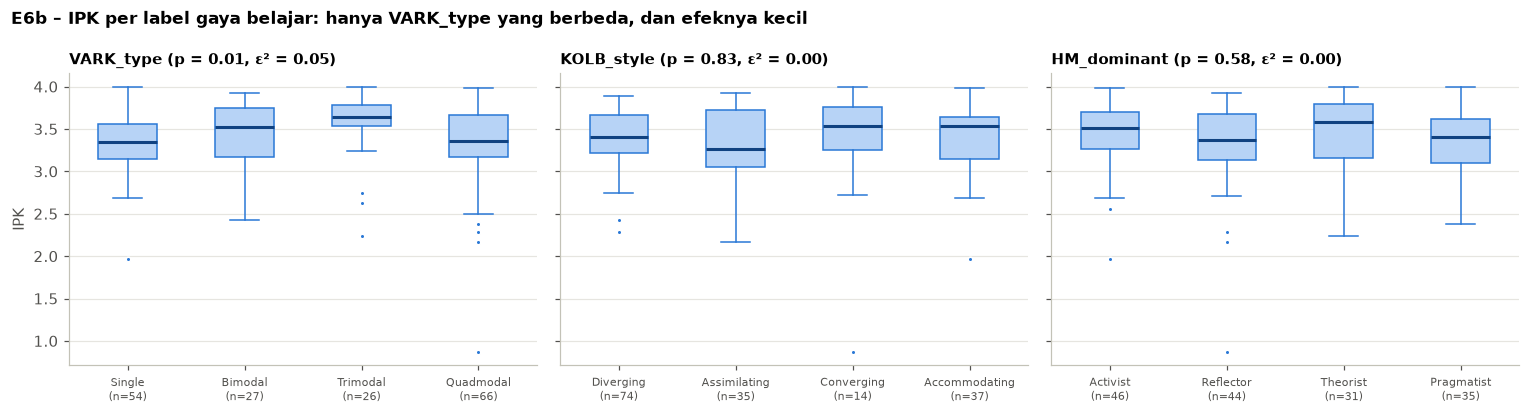

Post-hoc VARK_type:


,Pasangan,Median a,Median b,p (Bonferroni)
0,Single vs Bimodal,3.350,3.520,0.647
1,Single vs Trimodal,3.350,3.645,0.005
2,Single vs Quadmodal,3.350,3.355,1.000
3,Bimodal vs Trimodal,3.520,3.645,1.000
4,Bimodal vs Quadmodal,3.520,3.355,1.000
5,Trimodal vs Quadmodal,3.645,3.355,0.068


In [52]:
# E6 lanjutan: label (kategorikal) vs IPK (numerik) -> Kruskal-Wallis + effect size epsilon^2
def kruskal_eps(df_, label, nilai="IPK"):
    d = df_[[label, nilai]].dropna()
    grup = [g[nilai].values for _, g in d.groupby(label)]
    H, p = stats.kruskal(*grup)
    k, n = len(grup), len(d)
    return n, k, H, p, max((H - k + 1) / (n - k), 0)

LABEL_IPK = {"VARK_type": eda, "KOLB_style": eda.loc[ok],
             "HM_dominant": eda.loc[ok & ~eda["HM_dominant"].fillna("").str.contains(r"\+")]}
hasil_kw = pd.DataFrame([dict(zip(["Label", "n", "Jumlah kelompok", "H", "p", "epsilon²"], (lb, *kruskal_eps(d, lb))))
                         for lb, d in LABEL_IPK.items()]).set_index("Label").round(3)
display(hasil_kw)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (lb, d) in zip(axes, LABEL_IPK.items()):
    urut_lb = [k for k in LABEL[lb][1] if k in d[lb].dropna().unique()]
    data_lb = [d.loc[d[lb] == k, "IPK"].dropna() for k in urut_lb]
    ax.boxplot(data_lb, tick_labels=[f"{k}\n(n={len(v)})" for k, v in zip(urut_lb, data_lb)], widths=0.5,
               patch_artist=True, showfliers=True,
               boxprops=dict(facecolor="#b7d3f6", edgecolor=BIRU), medianprops=dict(color="#104281", linewidth=2),
               whiskerprops=dict(color=BIRU), capprops=dict(color=BIRU),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=BIRU, markeredgecolor="white"))
    ax.tick_params(axis="x", labelsize=7.5)
    ax.grid(axis="x", visible=False)
    ax.set_title(f"{lb} (p = {hasil_kw.loc[lb, 'p']:.2f}, ε² = {hasil_kw.loc[lb, 'epsilon²']:.2f})", fontsize=10)
axes[0].set_ylabel("IPK")
fig.suptitle("E6b – IPK per label gaya belajar: hanya VARK_type yang berbeda, dan efeknya kecil",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
simpan(fig, "E6b_ipk_per_label")

# Uji lanjutan (post-hoc) untuk label yang p < 0.05: Mann-Whitney berpasangan + koreksi Bonferroni
from itertools import combinations
for lb in hasil_kw.index[hasil_kw["p"] < 0.05]:
    d = LABEL_IPK[lb]; kel = [k for k in LABEL[lb][1] if k in d[lb].dropna().unique()]
    pas = list(combinations(kel, 2))
    posthoc = pd.DataFrame([{"Pasangan": f"{a} vs {b}",
                             "Median a": d.loc[d[lb] == a, "IPK"].median(), "Median b": d.loc[d[lb] == b, "IPK"].median(),
                             "p (Bonferroni)": min(stats.mannwhitneyu(d.loc[d[lb] == a, "IPK"].dropna(),
                                                                       d.loc[d[lb] == b, "IPK"].dropna()).pvalue * len(pas), 1)}
                            for a, b in pas]).round(3)
    print(f"Post-hoc {lb}:"); display(posthoc)

**Interpretasi:**
- Tipe Kolb dan gaya dominan Honey-Mumford **tidak berhubungan** dengan IPK (p = 0,83 dan 0,58; ε² = 0).
- `VARK_type` berbeda signifikan (p = 0,011), tetapi **efeknya kecil** (ε² = 0,05). Uji lanjut hanya menemukan beda Single vs Trimodal (median 3,35 vs 3,65; p Bonferroni = 0,005). Polanya tidak berurutan: Quadmodal (3,36) mirip Single, dan jumlah total pilihan VARK tidak berkorelasi dengan IPK (ρ = 0,05).

**Yang tidak bisa disimpulkan:** temuan ini bukan bukti bahwa menjadi trimodal membuat IPK lebih tinggi. Kelompoknya kecil (26 orang) dan ada beberapa uji sekaligus, jadi temuan ini perlu dikonfirmasi di data lain.

## E7 – Kesesuaian antar-framework (label kategorikal)
**Pertanyaan:** apakah label dari framework berbeda saling sejalan?
**Metode:** label bersifat nominal, jadi asosiasinya diukur dengan **Cramér's V** dari tabel kontingensi (chi-square), bukan korelasi numerik. Analisis memakai 173 responden (tanpa straightliner dan tanpa HM seri).

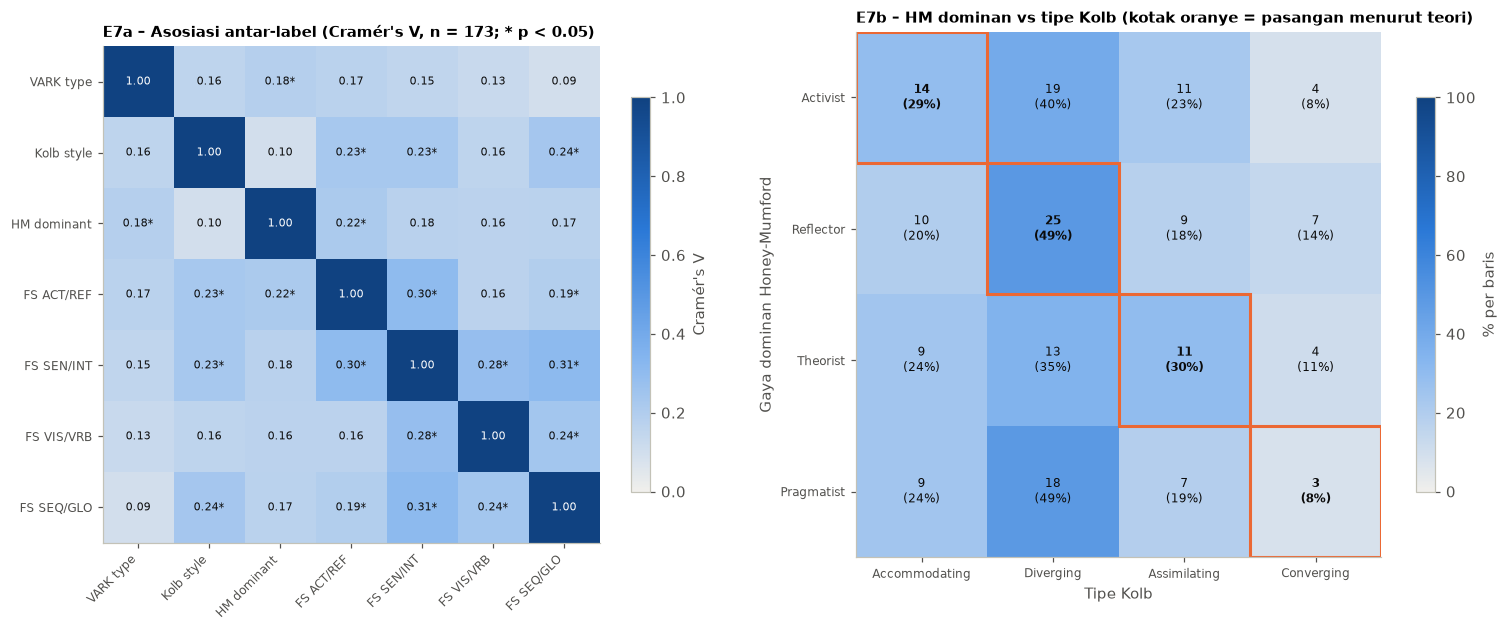

HM dominan cocok dengan pasangan teorinya di Kolb: 53 dari 173 (30.6%) | kecocokan yang diharapkan kalau tidak berhubungan: 26.4% | Cramér's V = 0.10, p = 0.848
Sel tabel silang dengan frekuensi harapan < 5: 3 dari 16 -> p-value chi-square hanya indikatif


Cramér's V      p
FS SEN/INT FS SEQ/GLO       0.309  0.000
FS ACT/REF FS SEN/INT       0.303  0.000
FS SEN/INT FS VIS/VRB       0.284  0.000
FS VIS/VRB FS SEQ/GLO       0.241  0.000
Kolb style FS SEQ/GLO       0.238  0.003
           FS SEN/INT       0.230  0.006

In [53]:
def cramers_v(x, y):
    """Asosiasi dua variabel kategorikal (0 = tidak berhubungan, 1 = identik)."""
    tabel = pd.crosstab(x, y)
    chi2, p, dof, _ = stats.chi2_contingency(tabel, correction=False)
    return np.sqrt(chi2 / (tabel.values.sum() * (min(tabel.shape) - 1))), p

# Label kategorikal (nominal) -> Cramér's V, BUKAN korelasi numerik. n = 173 (tanpa straightliner & tanpa HM seri)
lab = eda.loc[ok, ["VARK_type", "KOLB_style", "HM_dominant"] + [f"{d}_pole" for d in FS_D]].copy()
lab = lab[~lab["HM_dominant"].str.contains(r"\+")]
nama_lab = {"VARK_type": "VARK type", "KOLB_style": "Kolb style", "HM_dominant": "HM dominant",
            "FS_ACT_REF_pole": "FS ACT/REF", "FS_SEN_INT_pole": "FS SEN/INT",
            "FS_VIS_VRB_pole": "FS VIS/VRB", "FS_SEQ_GLO_pole": "FS SEQ/GLO"}
lab = lab.rename(columns=nama_lab)
V = pd.DataFrame(index=lab.columns, columns=lab.columns, dtype=float)
P = V.copy()
for a in lab.columns:
    for b in lab.columns:
        V.loc[a, b], P.loc[a, b] = (1.0, 0.0) if a == b else cramers_v(lab[a], lab[b])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1, 1.1]})
biru = LinearSegmentedColormap.from_list("biru", ["#f0efec", "#86b6ef", "#2a78d6", "#104281"])
im = ax1.imshow(V.astype(float), cmap=biru, vmin=0, vmax=1)
ax1.set_xticks(range(len(V)), V.columns, rotation=45, ha="right", fontsize=8)
ax1.set_yticks(range(len(V)), V.index, fontsize=8)
for i in range(len(V)):
    for j in range(len(V)):
        bintang = "*" if (i != j and P.iloc[i, j] < 0.05) else ""
        ax1.text(j, i, f"{V.iloc[i, j]:.2f}{bintang}", ha="center", va="center", fontsize=7.5,
                 color="white" if V.iloc[i, j] > 0.6 else "#0b0b0b")
ax1.grid(False)
fig.colorbar(im, ax=ax1, shrink=0.75, label="Cramér's V")
ax1.set_title(f"E7a – Asosiasi antar-label (Cramér's V, n = {len(lab)}; * p < 0.05)", fontsize=10)

# Tabel silang HM dominan x tipe Kolb (secara teori: ACT~Accommodating, REF~Diverging, THE~Assimilating, PRA~Converging)
URUT_HM = ["Activist", "Reflector", "Theorist", "Pragmatist"]
URUT_KOLB = ["Accommodating", "Diverging", "Assimilating", "Converging"]
silang = pd.crosstab(lab["HM dominant"], lab["Kolb style"]).reindex(index=URUT_HM, columns=URUT_KOLB)
persen_baris = silang.div(silang.sum(axis=1), axis=0) * 100
im2 = ax2.imshow(persen_baris, cmap=biru, vmin=0, vmax=100)
ax2.set_xticks(range(4), URUT_KOLB, fontsize=8)
ax2.set_yticks(range(4), URUT_HM, fontsize=8)
for i in range(4):
    for j in range(4):
        tebal = "bold" if i == j else "normal"
        ax2.text(j, i, f"{silang.iloc[i, j]}\n({persen_baris.iloc[i, j]:.0f}%)", ha="center", va="center",
                 fontsize=8, fontweight=tebal, color="white" if persen_baris.iloc[i, j] > 60 else "#0b0b0b")
        if i == j:
            ax2.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=ORANYE, linewidth=2))
ax2.grid(False)
ax2.set_xlabel("Tipe Kolb")
ax2.set_ylabel("Gaya dominan Honey-Mumford")
fig.colorbar(im2, ax=ax2, shrink=0.75, label="% per baris")
ax2.set_title("E7b – HM dominan vs tipe Kolb (kotak oranye = pasangan menurut teori)", fontsize=10)
simpan(fig, "E7_kesesuaian_antar_framework")

n_silang = silang.values.sum()
cocok = int(np.trace(silang.values))
cocok_acak = (silang.sum(axis=1).values * silang.sum(axis=0).values).sum() / n_silang ** 2 * 100
v_hk, p_hk = cramers_v(lab["HM dominant"], lab["Kolb style"])
print(f"HM dominan cocok dengan pasangan teorinya di Kolb: {cocok} dari {n_silang} ({cocok / n_silang * 100:.1f}%) "
      f"| kecocokan yang diharapkan kalau tidak berhubungan: {cocok_acak:.1f}% | Cramér's V = {v_hk:.2f}, p = {p_hk:.3f}")
print("Sel tabel silang dengan frekuensi harapan < 5:",
      int((stats.chi2_contingency(silang)[3] < 5).sum()), "dari 16 -> p-value chi-square hanya indikatif")
tabel_v = V.where(np.triu(np.ones(V.shape), k=1).astype(bool)).stack().rename("Cramér's V").to_frame()
tabel_v["p"] = P.where(np.triu(np.ones(P.shape), k=1).astype(bool)).stack()
display(tabel_v.sort_values("Cramér's V", ascending=False).head(6).round(3))

**Interpretasi:**
- Asosiasi antar-label **lemah** (Cramér's V umumnya 0,09–0,31). Yang paling kuat justru sesama dimensi Felder (0,24–0,31), sebagian karena responden yang "NEUTRAL" di satu dimensi cenderung NEUTRAL juga di dimensi lain.
- **HM dominan vs tipe Kolb:** secara teori Activist↔Accommodating, Reflector↔Diverging, Theorist↔Assimilating, Pragmatist↔Converging. Hanya **53 dari 173 (30,6%)** yang cocok, hampir sama dengan kecocokan kalau keduanya tidak berhubungan (26,4%); Cramér's V = 0,10, p = 0,85. Hanya Reflector↔Diverging yang cukup terlihat (49%).
- Kesimpulannya, **keempat framework tidak mengukur konstruk yang identik**, sehingga label satu framework tidak bisa dipakai menggantikan framework lain.

**Yang tidak bisa disimpulkan:** 3 dari 16 sel tabel silang punya frekuensi harapan < 5, jadi p-value chi-square hanya indikatif.

## E8 – Ringkasan temuan EDA

| # | Temuan | Dampak untuk tahap berikutnya |
|---|---|---|
| 1 | 192 dari 194 respons dipakai; 15 straightliner diberi flag | Label skala 1–5 dan analisis memakai n = 177 |
| 2 | Responden didominasi angkatan 2024 (56%); tanpa data prodi | Generalisasi terbatas |
| 3 | Data kosong hanya struktural (IPS, IPK) atau disengaja (label straightliner) | Tidak perlu imputasi |
| 4 | Kecenderungan menjawab "setuju" kuat (68,9% jawaban 4/5) | Skor mentah antar-tipe sulit dibedakan; gunakan skor selisih/relatif |
| 5 | Item tiap subskala konsisten (alpha 0,70–0,86) | Scoring per subskala layak |
| 6 | HM_dominant seimbang; KOLB_style timpang (Converging 10%) dan banyak titik tepat di batas; VARK_profile punya 4 kelas < 5 responden; kekuatan Felder hampir semua Balanced | Dengan aturan UTS (teori), HM_dominant paling seimbang; Kolb perlu penanganan imbalance; pakai VARK_type, bukan VARK_profile |
| 7 | Hubungan lintas framework lemah; HM vs Kolb hanya 30,6% cocok | Framework tidak saling menggantikan |
| 8 | Skor gaya belajar tidak berkorelasi dengan IPK setelah koreksi FDR; dari label, hanya VARK_type yang berbeda dengan efek kecil (Trimodal > Single) | IPK bukan target yang menjanjikan dari fitur gaya belajar |
| 9 | Dengan aturan panduan UAS (E5c): FS dan VARK seimbang; HM didominasi Seri (33%) dan Kolb didominasi Batas (36%); semua straightliner jatuh ke Setara/Seri/Batas | Untuk klasifikasi UAS, VARK atau FS lebih siap; keputusan straightliner diambil dan dijelaskan di UAS |

**Keterbatasan:** sampel non-probabilitas dan didominasi satu angkatan; instrumen versi Likert berbeda dari instrumen asli sehingga label memakai norma lokal; angkatan hanya perkiraan; ada efek *acquiescence* karena semua item berarah positif.